# Lab 1 Agentic Pipeline (analysis on your own tools)

This is the **agentic-flow stage**. `DM2026-Lab1-AgentDev.ipynb` (the
developer stage) helps you write pipeline **tools**<sub>5</sub> into
`agent_dev_workspace/`. This notebook discovers what you've built
there and runs a real analysis **agent**<sub>4</sub> on top of it,
following the same one-tool-call-per-turn rules.

(Unfamiliar term? `agent_dev/GLOSSARY.md` has the full list.)

The agent can search your workspace and describe what a tool does, but
running any of your own tools needs your explicit approval first, one
single approval that covers all of them together, not one per tool.
See "What to try" below.

Haven't finished every tool? Fine. Missing or broken files are skipped
and reported; whatever loaded is still discoverable. Come back as you
add more.

## 0. Setup: your name, a backend, and its API key

Same name, student ID, and **backends**<sub>12</sub> (`groq`,
`gemini`) as the developer stage, and the same `config/.env` key too.
**Groq is the recommended default**, faster on tool-calling turns
(Gemini can take up to a minute, sometimes fails outright). Use Gemini
as a fallback once Groq's **rate limit**<sub>13</sub> runs out.

Got more than one key? **Turn on multi-provider fallback**<sub>14</sub>:
if your backend hits a rate limit mid-session, it automatically
retries with the next one. Worth it: both providers' free tiers only
reset once a day (Groq at midnight UTC, Gemini at midnight Pacific).

Type `/status` in the chat at any point to see which of your keys
are still active and which have hit a rate limit this session,
handled entirely by the chat widget itself, not the agent, so it
never uses a turn or shows up in your graded log.

Run the cell below, fill it in, and click **Confirm**.

In [ ]:
from agent_pipeline.backend_widget import select_backend

backend_choice = select_backend()

## 1. Discover your tools

Tools come from two places: `agent_dev_workspace/`, the eighteen you
built yourself (see `agent_dev/TOOLS_PIPELINE_BREAKDOWN.md`), and
`premade_tools/`, which holds the two exceptions, `load_dataset_tool`
and `visualize_result_tool`, already built for you.

Provided tools are usable right away. Your own tools in your
**workspace**<sub>25</sub> aren't: the agent can describe what one
does, but none of them can run until you grant access to the whole
set at once, in the chat below. See "What to try" for how that works.

**Why this is a plain code cell, not something the agent does:** the
agent can only call a tool already handed to the model *before* the
chat starts. There's no way to add one mid-conversation, so this scan
runs once, as ordinary setup. `list_available_tools_tool`/
`describe_tool_tool` still report exactly what it found, live, during
the chat. Built another tool mid-session? Re-run this cell and the
graph-launch cell below to pick it up. That starts a fresh
conversation.

In [ ]:
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools
from agent_pipeline.tool_access import build_gated_tools

session = SessionState()
student_tools, student_problems = load_workspace_tools("agent_dev_workspace", session)
premade_tools, premade_problems = load_workspace_tools("premade_tools", session)
tools = build_gated_tools(student_tools, session, premade_tools=premade_tools)
problems = student_problems + premade_problems

print(f"Your tools ({len(student_tools)}, need your approval to run): {[t.name for t in student_tools]}")
print(f"Provided tools ({len(premade_tools)}, usable right away): {[t.name for t in premade_tools]}")
if problems:
    print("\nNot loaded:")
    for fname, message in problems:
        print(f"  {fname}: {message}")
if not student_tools:
    print("\nNo tools of your own discovered yet. Build something in the developer-stage notebook first.")

## The full pipeline, step by step

The same order `agent_dev/TOOLS_PIPELINE_BREAKDOWN.md`'s tool table
lists them in, each stage depending on the one before. Direct the
agent through these yourself, one at a time, in your own words. Not
a script to repeat verbatim.

1. Load the dataset (`load_dataset_tool`, a provided tool; runs
   immediately, no approval needed).
2. Inspect a few rows of what got loaded (`inspect_data_tool`).
3. Check for missing text (`check_missing_tool`).
4. Check for duplicate documents (`check_duplicates_tool`).
5. Look at basic statistics on document length (counts, a box plot by
   category) (`describe_data_tool`).
6. Subsample the data, if you want a smaller working set
   (`sample_data_tool`).
7. Build the document-term matrix (`build_dtm_tool`).
8. Look at term frequency across all documents (`term_frequency_tool`).
9. View a heatmap of a slice of the document-term matrix
   (`dtm_heatmap_tool`).
10. Filter near-constant terms out by variance (`variance_filter_tool`).
11. Filter terms by their correlation with a target category (Pearson
    and/or Spearman) (`pearson_filter_tool` / `spearman_filter_tool`).
12. View a heatmap of how the surviving terms correlate with each
    other (`feature_correlation_matrix_tool`).
13. Visualize one of the results above as a bar chart
    (`visualize_result_tool`, the other provided tool; runs immediately
    too, since it only renders an already-stored result rather than
    computing anything new).
14. Mine frequent patterns per category (`mine_patterns_tool`).
15. Reduce the document-term matrix to two or three dimensions and view
    the plot, colored by category (`reduce_dimensions_tool`).
16. Binarize the category labels (`binarize_labels_tool`).
17. Compute cosine similarity between two documents
    (`cosine_similarity_tool`).

Steps 1 and 13 are provided tools; every other step needs a tool you
build yourself, steps 2 through 12 as much as 14 through 17, not just
what comes after 13. The first one you ask for triggers a single
request-approve exchange that covers every one of your own tools at
once, not just that one; every one after that just runs directly,
already granted. A tool that isn't built, or errors out, gets fixed in
the developer-stage notebook, not here.

## What to try

The chat is below. A provided tool runs the moment you ask for it;
your own tools don't, until you've granted access to the whole set,
once.

Each numbered line below is tagged **[PROMPT]** or **[INSTRUCTION, not
a prompt]**, same convention as the developer-stage notebook. A
`[PROMPT]` line is close to what you'd actually type. An
`[INSTRUCTION, not a prompt]` line tells you what to do or ask in your
own words; there's no fixed line to type there.

1. **[PROMPT]** `What tools do I have?` (list_available_tools_tool, works on all twenty, no grant needed)
2. **[PROMPT]** `Run load_dataset_tool with categories alt.atheism, soc.religion.christian, comp.graphics, and sci.med` (a provided tool: just runs, no request needed; these are Master's own four categories, so your numbers stay comparable to Master's if you want to check your work against it)
3. **[PROMPT]** `What does variance_filter_tool do?` (describe_tool_tool, still no grant: it describes but doesn't run)
4. **[INSTRUCTION, not a prompt]** Before asking for access, just ask it to run `variance_filter_tool` directly. Watch whether it requests access first, for all of your tools at once, rather than assuming it's fine
5. **[INSTRUCTION, not a prompt]** Also try asking it to request and grant access "in the same step." It should refuse and still wait for your separate approval, same **gate**<sub>27</sub> as the developer stage
6. **[PROMPT]** Now for real: `Run variance_filter_tool with a threshold of 0.01`. The agent should request access to all of your own tools at once, explaining why, then stop and wait
7. **[PROMPT]** `Yes, go ahead`. This grants every one of your own tools in one step, not just this one
8. **[INSTRUCTION, not a prompt]** Ask for a different tool of yours, one you haven't mentioned before; it should run directly, no new request, since everything was already granted together

**If the agent's reply is just "(No response came back for that. Ask
it to summarize what happened, or go ahead with your next question.)"**,
that's not a bug, and not the session getting stuck. Behind the scenes,
an empty reply is automatically retried several more times, scaled to
how many keys you have configured, switching to a different key or
backend each time, before this message ever shows, so seeing it at all
means every one of those attempts came back with nothing usable. The
tool call itself, if there was one that turn, already ran either way;
only the follow-up comment is missing. Just ask it to summarize, or
move to your next question.

## 2. Build the graph and launch the chat

Same **structural**<sub>29</sub> rules as the developer stage: one tool call per message,
a mandatory discuss-only follow-up, and a numeric **grounding**<sub>15</sub> check on
everything the agent says.

In [ ]:
SYSTEM_PROMPT = """You are a data mining lab assistant running analysis \
tools for the student's Lab 1 pipeline. Some of these tools the student \
wrote themselves, not a finished reference implementation, and may be \
missing, incomplete, or buggy since they're still building this; the \
rest are a pre-built, already-working part of the pipeline the student \
didn't need to write by hand. If a tool call errors, explain the error \
plainly and, if it was one of the student's own tools, suggest they go \
back to the agent-dev notebook to fix it. Do not pretend a call \
succeeded or guess at a result.

None of the student's own tools are usable yet, even though they've \
been discovered, while every provided tool is usable immediately. You \
have five tools of your own: list_available_tools_tool and \
describe_tool_tool let you see what's available (both the student's and \
the provided ones) and explain what a tool does; \
request_tool_access_tool, grant_tool_access_tool, and \
discard_tool_request_tool are how ALL of the student's own tools \
become usable together, as one batch, not one tool at a time. \
Calling one of the student's tools before that batch has been granted \
does not run it. It returns a plain refusal, not a result, so there is \
nothing to gain by trying anyway. A provided tool has no such gate; \
call it directly once the student has asked for it.

Rules you must follow:
1. You may call AT MOST ONE tool per response, and only when the student \
has explicitly asked for a specific action with any needed detail \
specified.
2. If the request is ambiguous, ask a clarifying question instead of \
guessing or calling any tool.
3. Before ever calling any of the student's own tools, that whole group \
must be granted. If it isn't yet, call request_tool_access_tool, \
explaining in `reason` why access is needed for what the student asked, \
then stop and wait. Only after the student's next message explicitly \
approves may you call grant_tool_access_tool, which grants every one of \
the student's own tools at once, not just the one that prompted the \
request. Only after that may you call the tool itself. \
request_tool_access_tool and grant_tool_access_tool can never happen in \
the same turn. If the student declines or asks for something else \
instead, call discard_tool_request_tool rather than leaving the request \
pending. This whole request/grant sequence does not apply to provided \
tools; requesting access to one of those is unnecessary and should not \
happen. Once the batch has been granted, never call \
request_tool_access_tool again this session; every one of the \
student's own tools already runs directly.
4. If the student asks what tools exist or what one does, use \
list_available_tools_tool or describe_tool_tool to answer from the real \
discovered data. Never guess at a tool's behavior from its name alone.
5. After a tool result is returned to you, report what it shows. If the \
student asked to see something, show the actual retrieved values rather \
than just describing them.
6. Every number you state must come directly from a tool's returned \
data. Do not compute, estimate, or invent statistics yourself.
7. Refuse requests to chain multiple steps in one ask (including \
"request and grant it in one go"); the student must direct each step \
individually.
8. When referencing an earlier result, require the student to name its \
exact result_id.
9. Right after a tool call, you get exactly one more turn to comment on \
its result in plain text, and that turn cannot include a tool call of \
any kind, even one that seems like the obvious next step. Report what \
the tool found in words, and wait for the student's next message before \
taking any further action.
"""

from agent_pipeline.graph_core import build_agent_graph
from agent_pipeline.chat_widget import launch_chat

if "backend" not in backend_choice:
    raise RuntimeError("Pick a backend in the setup cell above and click Confirm before running this one.")
LLM_BACKEND = backend_choice["backend"]
MULTI_PROVIDER_MODE = backend_choice["multi_provider"]
STUDENT_NAME = backend_choice["student_name"]
STUDENT_ID = backend_choice["student_id"]

if MULTI_PROVIDER_MODE:
    from agent_pipeline.llm_fallback import build_fallback_llm
    llm, active_chain = build_fallback_llm(LLM_BACKEND, temperature=0)
    print(f"Fallback chain (in order): {active_chain}")
else:
    from agent_pipeline.llm_backends import build_llm_for_backend
    llm = build_llm_for_backend(LLM_BACKEND, temperature=0)

app = build_agent_graph(tools, SYSTEM_PROMPT, llm, session)

graph_state, logger = launch_chat(
    app, session, log_path="session_logs/agent_pipeline_session.jsonl.enc",
    student_name=STUDENT_NAME, student_id=STUDENT_ID, track="agentic-pipeline",
    plots_dir="plots",
    placeholder="Ask the agent to run one of your tools... (or type /status to see key rotation status)",
    llm=llm,
)

## 3. Write your report

Every plot a tool produces (`reduce_dimensions_tool`,
`visualize_result_tool`) is saved automatically to `plots/`, named
`YourName_agentic-pipeline_plot_<result_id>.png` (your own name, as you
typed it in the setup cell, standing in for `YourName` here). Nothing
extra to do; it happens the moment the tool runs.

**Your report is not written in this notebook.** Run the cell below
once to create your own report file:

```
reports/YourName_YourStudentID_agentic-pipeline_report.md
```

Open that file directly (in JupyterLab's file browser, VS Code, or any
text editor) and write your report there: a short report, as if
explaining your findings to someone who never saw the conversation,
what you ran, what it found, what that means, referencing specific
`result_id`s and saved plots. Embed a plot with a normal markdown
image link, using your own actual filename from `plots/` (check the
printed "plot saved to..." message or the file listing at the bottom
of this notebook for the exact name). **Use `../plots/...`, not
`plots/...`**: your report file lives inside `reports/`, one folder
below the repo root, while `plots/` is a sibling of `reports/` at the
root, so the link needs to step back out first:
```
![Variance filter result](../plots/YourName_agentic-pipeline_plot_variance_1.png)
```

**Graded separately from the conversation above.** The chat is judged
on how you directed the agent; the report is judged on
whether the analysis is correct and clearly communicated. Neither
substitutes for the other; they're scored independently.

## Create your report file

Run this once. It creates an empty report file for you to write in,
named with your name, your student ID, and this notebook's track, the
exact same name and ID you entered in the setup cell above. Safe to
re-run later: it never overwrites a file that already exists, so
running it again after you've started writing won't erase your work.

In [ ]:
from pathlib import Path

def _safe_stem(name: str) -> str:
    stem = "".join(c if c.isalnum() else "_" for c in name).strip("_")
    return stem or "unknown"

_TRACK = "agentic-pipeline"
_PLACEHOLDER = (
    "*(Replace this with your own report: 3-5 short paragraphs. For each "
    "major step you actually ran, loading the data, filtering, pattern "
    "mining, dimension reduction, whatever applies, say what you did, "
    "reference the specific `result_id` and/or saved plot, and explain "
    "what it shows. Delete this instruction text before submitting.)*"
)

reports_dir = Path("reports")
reports_dir.mkdir(exist_ok=True)
report_path = reports_dir / f"{_safe_stem(STUDENT_NAME)}_{STUDENT_ID}_{_TRACK}_report.md"

if report_path.exists():
    print(f"Already exists, left untouched: {report_path}")
else:
    report_path.write_text(f"# Your report\n\n{_PLACEHOLDER}\n", encoding="utf-8")
    print(f"Created: {report_path}")

print("Open that file and write your report there, not in this notebook.")

## 4. Submitting your work

Three things, all from this notebook:

1. **The session log**,
   `session_logs/agent_pipeline_session.jsonl.enc`, logged turn by
   turn, encrypted with the grading key. You can't read your own log
   back.
2. **The plots folder**, `plots/`, every plot your tools produced,
   saved automatically, referenced from your report.
3. **Your report**,
   `reports/YourName_YourStudentID_agentic-pipeline_report.md`, from
   "Create your report file" above. Same name and ID as your log.

Upload all three exactly as produced, alongside the log from the
developer-stage notebook.

**Important: these folders are gitignored by default.** `session_logs/`,
`plots/`, and `reports/` are left out of this shared repo on purpose, so a
plain `git add .` silently skips them and your pushed fork ends up
without your log, plots, or report. Before your final commit, force-add
them explicitly:

```
git add -f session_logs plots reports
git commit -m "agentic-pipeline submission"
git push
```

Run `git status` afterward and confirm they show up as committed.

In [ ]:
import os

log_path = "session_logs/agent_pipeline_session.jsonl.enc"
if os.path.exists(log_path):
    print(f"Log file present: {log_path} ({os.path.getsize(log_path)} bytes)")
else:
    print("No log yet. Send at least one message in the chat above first.")

plots_dir = "plots"
if os.path.isdir(plots_dir):
    plot_files = sorted(os.listdir(plots_dir))
    print(f"Plots saved ({len(plot_files)}): {plot_files}")
else:
    print("No plots saved yet (expected if you haven't run a plotting tool).")

if "report_path" not in globals():
    print("No report file yet. Run \"Create your report file\" above first, then re-run this cell.")
elif os.path.exists(report_path):
    text = open(report_path, encoding="utf-8").read()
    if "Replace this with your own report" in text:
        print(f"Report file present but still the placeholder: {report_path}")
    else:
        print(f"Report file present and written: {report_path} ({os.path.getsize(report_path)} bytes)")
else:
    print("No report file yet. Run \"Create your report file\" above first.")

In [ ]:
# Step 208: Launch the official Agentic Pipeline chat

from agent_pipeline.graph_core import build_agent_graph
from agent_pipeline.chat_widget import launch_chat

print("=== Step 208: Launch Agentic Pipeline ===")

# Verify that the official setup cells have been executed
required_variables = [
    "backend_choice",
    "session",
    "tools",
    "SYSTEM_PROMPT",
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    print("Missing setup variables:", missing)
    print("Please run the corresponding official notebook cells first.")

else:
    if "backend" not in backend_choice:
        print("Please select a backend and click Confirm in Cell 2.")

    else:
        backend = backend_choice["backend"]
        multi_provider = backend_choice["multi_provider"]

        print("Selected backend:", backend)
        print("Multi-provider mode:", multi_provider)
        print("Registered tool entries:", len(tools))

        if multi_provider:
            from agent_pipeline.llm_fallback import build_fallback_llm

            llm_208, active_chain_208 = build_fallback_llm(
                backend,
                temperature=0
            )

            print("Fallback chain:", active_chain_208)

        else:
            from agent_pipeline.llm_backends import build_llm_for_backend

            llm_208 = build_llm_for_backend(
                backend,
                temperature=0
            )

        app_208 = build_agent_graph(
            tools,
            SYSTEM_PROMPT,
            llm_208,
            session
        )

        graph_state_208, logger_208 = launch_chat(
            app_208,
            session,
            log_path="session_logs/agent_pipeline_session.jsonl.enc",
            student_name=backend_choice["student_name"],
            student_id=backend_choice["student_id"],
            track="agentic-pipeline",
            plots_dir="plots",
            placeholder="Ask the agent to run one tool...",
            llm=llm_208,
        )

        print("Step 208: AGENT CHAT INITIALIZED")

In [ ]:
# Step 208A: Check notebook initialization state

print("=== Step 208A: Notebook Initialization Check ===")

required = [
    "backend_choice",
    "session",
    "student_tools",
    "premade_tools",
    "tools",
    "SYSTEM_PROMPT",
    "llm",
    "app",
]

for name in required:
    if name in globals():
        value = globals()[name]

        if name == "backend_choice":
            print(f"PASS: {name}")
            print("  Backend selected:", value.get("backend"))
            print("  Confirmed:", "backend" in value)
        elif name in ("student_tools", "premade_tools", "tools"):
            print(f"PASS: {name} ({len(value)} entries)")
        else:
            print(f"PASS: {name}")
    else:
        print(f"MISSING: {name}")

print("\n=== Current Working Directory ===")

from pathlib import Path
print(Path.cwd())

print("\nStep 208A: INITIALIZATION CHECK COMPLETE")


In [ ]:
# Step 208B: Initialize official backend selection

from agent_pipeline.backend_widget import select_backend

print("=== Step 208B: Backend Selection ===")

backend_choice = select_backend()

print("\nBackend selection widget initialized.")
print("Please complete the fields and click Confirm.")

In [ ]:
# Step 213: Inspect official Agent session state

print("=== Step 213: Agent Session Verification ===")

print("\n=== Authorization State ===")

granted = getattr(session, "granted_tools", set())

print("Granted student tools:", len(granted))
print("Pending request:", getattr(session, "pending_tool_request", None))

print("\n=== Stored Tool Results ===")

results = getattr(session, "results_store", {})

print("Results store type:", type(results).__name__)
print("Stored result count:", len(results))

if isinstance(results, dict):
    for result_id, record in results.items():
        print("\nResult ID:", result_id)
        print("Record preview:", str(record)[:500])

print("\n=== Expected Result ===")

if "list_files_1" in results:
    print("PASS: list_files_1 is stored in the official session")
else:
    print("CHECK: list_files_1 not found in results_store")

if len(granted) == 18:
    print("PASS: All 18 student tools are granted")
else:
    print("CHECK: Granted tool count differs from 18")

print("\nStep 213: SESSION VERIFICATION COMPLETE")

In [ ]:
# Step 214: Locate numeric verification warning source

from pathlib import Path

print("=== Step 214: Numeric Verification Inspection ===")

search_terms = [
    "unverified numbers",
    "unverified_numbers",
    "flagged",
    "verify_numbers",
    "numeric_guard",
]

root = Path("agent_pipeline")

matches = []

for path in sorted(root.rglob("*.py")):
    try:
        lines = path.read_text(
            encoding="utf-8"
        ).splitlines()
    except Exception as exc:
        print("Could not read:", path, exc)
        continue

    for index, line in enumerate(lines):
        if any(
            term.lower() in line.lower()
            for term in search_terms
        ):
            matches.append((path, index, lines))

print("\nMatches found:", len(matches))

for path, index, lines in matches:
    print("\n" + "=" * 60)
    print("File:", path)
    print("Line:", index + 1)

    start = max(0, index - 5)
    end = min(len(lines), index + 6)

    for i in range(start, end):
        print(f"{i + 1:03d}: {lines[i]}")

print("\nStep 214: WARNING SOURCE INSPECTION COMPLETE")

In [ ]:
# Step 215: Trace ungrounded_numbers validation logic

from pathlib import Path

print("=== Step 215: Numeric Grounding Logic Inspection ===")

root = Path("agent_pipeline")

search_terms = [
    "ungrounded_numbers",
    "grounded_numbers",
    "number_guard",
    "numeric",
    "extract_numbers",
]

for path in sorted(root.rglob("*.py")):
    lines = path.read_text(encoding="utf-8").splitlines()

    matching_indices = [
        i for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in search_terms)
    ]

    if not matching_indices:
        continue

    print(f"\n=== {path} ===")

    printed = set()

    for index in matching_indices:
        start = max(0, index - 8)
        end = min(len(lines), index + 9)

        for i in range(start, end):
            if i not in printed:
                print(f"{i + 1:03d}: {lines[i]}")
                printed.add(i)

        print("---")

print("\nStep 215: NUMERIC GROUNDING INSPECTION COMPLETE")

In [ ]:
# Step 216: Reproduce numeric grounding warning

from agent_pipeline.grounding import (
    extract_numbers,
    check_grounding,
)

print("=== Step 216: Numeric Grounding Reproduction ===")

# Same content, different list formatting
numbered_text = """Files:
1. .gitattributes
2. .gitignore
3. .python-version
14. uv.lock

Number of files: 14
Number of folders: 16
"""

bullet_text = """Files:
- .gitattributes
- .gitignore
- .python-version
- uv.lock

Number of files: 14
Number of folders: 16
"""

print("\n=== Numbered List ===")
print("Extracted numbers:", extract_numbers(numbered_text))
print(
    "Ungrounded numbers:",
    check_grounding(numbered_text, session.results_store)
)

print("\n=== Bullet List ===")
print("Extracted numbers:", extract_numbers(bullet_text))
print(
    "Ungrounded numbers:",
    check_grounding(bullet_text, session.results_store)
)

print("\n=== Validation ===")

numbered_flags = check_grounding(
    numbered_text, session.results_store
)

bullet_flags = check_grounding(
    bullet_text, session.results_store
)

if numbered_flags and not bullet_flags:
    print("PASS: Markdown numbering causes false warnings")
elif not numbered_flags and not bullet_flags:
    print("PASS: Both formats are grounded")
else:
    print("CHECK: Additional grounding investigation needed")

print("\nStep 216: GROUNDING REPRODUCTION COMPLETE")

In [ ]:
# Step 219: Verify loaded dataset in official Session

print("=== Step 219: Dataset Session Verification ===")

# Check stored result
result_id = "load_dataset_2"
results = session.results_store

print("\n=== Result Storage ===")
print("Result ID exists:", result_id in results)

if result_id in results:
    record = results[result_id]["record"]

    print("Tool name:", record.tool_name)
    print("Arguments:", record.args)
    print("Summary:", record.summary)

# Check DataFrame
print("\n=== Session DataFrame ===")

df = getattr(session, "dataframe", None)

if df is None:
    print("FAIL: No DataFrame found in Session")
else:
    print("DataFrame shape:", df.shape)
    print("Columns:", list(df.columns))

    if "label" in df.columns:
        print("\n=== Label Distribution ===")
        print(df["label"].value_counts().to_string())

    print("\n=== First Three Records ===")
    print(df.head(3).to_string(index=False, max_colwidth=80))

# Final validation
print("\n=== Validation ===")

checks = {
    "Result stored": result_id in results,
    "DataFrame available": df is not None,
    "Expected document count": df is not None and len(df) == 1079,
    "Text column exists": df is not None and "text" in df.columns,
    "Label column exists": df is not None and "label" in df.columns,
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("Step 219: DATASET VERIFICATION COMPLETE")

In [ ]:
# Step 220: Inspect downstream tool column dependencies

from pathlib import Path
import ast

print("=== Step 220: Dataset Column Compatibility ===")

print("\n=== Actual Dataset Columns ===")
print(list(session.dataframe.columns))

print("\n=== Workspace Column References ===")

search_terms = [
    '"label"',
    "'label'",
    '"category"',
    "'category'",
    '"category_name"',
    "'category_name'",
    "session.dataframe",
]

workspace = Path("agent_dev_workspace")

for path in sorted(workspace.glob("*.py")):
    lines = path.read_text(encoding="utf-8").splitlines()

    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(term in line for term in search_terms)
    ]

    if matches:
        print(f"\nFile: {path.name}")

        for line_no, line in matches:
            print(f"  Line {line_no}: {line[:160]}")

print("\n=== Official Loader Column References ===")

loader = Path("premade_tools/data_loading_tools.py")

if loader.exists():
    lines = loader.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines, 1):
        if any(term in line for term in search_terms):
            print(f"Line {i}: {line.strip()[:160]}")

print("\nStep 220: COLUMN COMPATIBILITY INSPECTION COMPLETE")

In [ ]:
# Step 224B: Inspect current backend without changing Session

print("=== Current Backend ===")

for name in ["LLM_BACKEND", "backend_choice", "llm", "app"]:
    value = globals().get(name)

    if value is None:
        print(f"{name}: Not initialized")
    elif name == "llm":
        print(f"{name}: {type(value).__name__}")
        print("Model:", getattr(value, "model_name",
                                getattr(value, "model", "Unknown")))
    elif name == "app":
        print(f"{name}: Initialized ({type(value).__name__})")
    else:
        print(f"{name}: {value}")

print("\n=== Session Preservation ===")
print("Session initialized:", "session" in globals())

if "session" in globals():
    print("Documents:", len(session.dataframe) if session.dataframe is not None else 0)
    print("Granted tools:", len(session.granted_tools))
    print("Stored results:", list(session.results_store.keys()))

print("\nStep 224B: INSPECTION COMPLETE")

In [ ]:
# Step 224C: Inspect official backend builder
# Read-only inspection; no API calls or Session changes.

import inspect

print("=== Backend Builder Inspection ===")

print("\n=== build_llm_for_backend ===")

if "build_llm_for_backend" in globals():
    fn = build_llm_for_backend
    print("Signature:", inspect.signature(fn))
    print("Defined in:", inspect.getfile(fn))
    print("\nSource code:")
    print(inspect.getsource(fn))
else:
    print("build_llm_for_backend is not available.")

print("\n=== Current Graph Builder ===")

if "build_agent_graph" in globals():
    print("Signature:", inspect.signature(build_agent_graph))
else:
    print("build_agent_graph is not available.")

print("\n=== Current Session ===")
print("Documents:", len(session.dataframe))
print("Granted tools:", len(session.granted_tools))
print("Stored results:", len(session.results_store))

print("\nStep 224C: INSPECTION COMPLETE")

In [ ]:
# Step 224D: Initialize Gemini backend safely
# Do not replace the current Groq llm or app yet.

print("=== Step 224D: Gemini Backend Initialization ===")

try:
    gemini_llm = build_llm_for_backend(
        "gemini",
        temperature=0
    )

    print("Gemini backend initialized: PASS")
    print("Model wrapper:", type(gemini_llm).__name__)

except Exception as e:
    gemini_llm = None
    print("Gemini backend initialized: FAIL")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))

print("\n=== Existing Session ===")
print("Current backend:", LLM_BACKEND)
print("Documents:", len(session.dataframe))
print("Granted tools:", len(session.granted_tools))
print("Stored results:", list(session.results_store.keys()))

print("\nStep 224D: COMPLETE")

In [ ]:
# Step 224E: Inspect official chat interface
# Read-only: no API calls, no Session modifications.

import inspect

print("=== Step 224E: Chat Interface Inspection ===")

print("\n=== launch_chat Signature ===")
print(inspect.signature(launch_chat))

print("\n=== launch_chat Source Location ===")
print(inspect.getfile(launch_chat))

print("\n=== launch_chat Source Code ===")
print(inspect.getsource(launch_chat))

print("\n=== Existing Agent State ===")
print("Current backend:", LLM_BACKEND)
print("Gemini initialized:", gemini_llm is not None)
print("Graph state available:", "graph_state" in globals())
print("Logger available:", "logger" in globals())

print("\n=== Session Preservation ===")
print("Documents:", len(session.dataframe))
print("Granted tools:", len(session.granted_tools))
print("Stored results:", list(session.results_store.keys()))

print("\nStep 224E: INSPECTION COMPLETE")

In [ ]:
# Step 224F: Launch Gemini Agent with existing Session

from agent_pipeline.graph_core import build_agent_graph
from agent_pipeline.chat_widget import launch_chat

# Keep existing Groq app and graph_state unchanged.
gemini_app = build_agent_graph(
    tools,
    SYSTEM_PROMPT,
    gemini_llm,
    session
)

# Launch a separate chat and encrypted log.
gemini_graph_state, gemini_logger = launch_chat(
    gemini_app,
    session,
    log_path="session_logs/agent_pipeline_gemini_session.jsonl.enc",
    student_name="李中信",
    student_id="d11409105",
    track="agentic-pipeline",
    plots_dir="plots",
    placeholder="Ask the Gemini agent...",
    llm=gemini_llm
)

In [ ]:
# Step 225A: Inspect build_dtm_tool without API calls

import inspect

print("=== Step 225A: Offline DTM Tool Inspection ===")

dtm_tools = [
    tool for tool in student_tools
    if tool.name == "build_dtm_tool"
]

if not dtm_tools:
    print("FAIL: build_dtm_tool not found")
else:
    dtm_tool = dtm_tools[0]

    print("\n=== Tool Description ===")
    print(dtm_tool.description)

    print("\n=== Parameter Schema ===")
    print(dtm_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(dtm_tool.func))

print("\n=== Session Status ===")
print("Documents:", len(session.dataframe))
print("Granted tools:", len(session.granted_tools))
print("Stored results:", list(session.results_store.keys()))

print("\nStep 225A: COMPLETE")

In [ ]:
# Step 225B: Offline DTM functional validation
# No Groq or Gemini API calls.

print("=== Step 225B: Offline DTM Validation ===")

dtm_tool = next(
    tool for tool in student_tools
    if tool.name == "build_dtm_tool"
)

result = dtm_tool.invoke({
    "ngram_range": [1, 1]
})

if "error" in result:
    print("DTM construction: FAIL")
    print("Error:", result["error"])
else:
    print("DTM construction: PASS")
    print("Result ID:", result["result_id"])
    print("Documents:", result["n_documents"])
    print("Terms:", result["n_terms"])
    print("Matrix shape:", result["shape"])
    print("Non-zero elements:", result["non_zero"])
    print("Total elements:", result["total_elements"])
    print("Sparsity (%):", round(result["sparsity_pct"], 4))

print("\n=== Session Verification ===")

matrix = session.feature_matrix
features = session.feature_names

checks = {
    "Matrix exists": matrix is not None,
    "Feature names exist": features is not None,
    "Document count matches": matrix is not None and matrix.shape[0] == 1079,
    "Feature count matches": (
        matrix is not None
        and features is not None
        and matrix.shape[1] == len(features)
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("Step 225B: COMPLETE")

In [ ]:
# Step 226: Offline inspection of term_frequency_tool
# Read-only; no API calls and no Session modifications.

import inspect

print("=== Step 226: Term Frequency Tool Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "term_frequency_tool"
]

if not matches:
    print("FAIL: term_frequency_tool not found")
else:
    tf_tool = matches[0]

    print("\n=== Tool Description ===")
    print(tf_tool.description)

    print("\n=== Parameter Schema ===")
    print(tf_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(tf_tool.func))

print("\n=== Existing DTM ===")
print("Matrix shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))
print("DTM result stored:", "build_dtm_6" in session.results_store)

print("\nStep 226: INSPECTION COMPLETE")

In [ ]:
# Step 227: Offline Term Frequency Analysis
# No Groq or Gemini API calls.

print("=== Step 227: Term Frequency Analysis ===")

tf_tool = next(
    tool for tool in student_tools
    if tool.name == "term_frequency_tool"
)

result = tf_tool.invoke({})

if "error" in result:
    print("Term Frequency: FAIL")
    print("Error:", result["error"])
else:
    print("Term Frequency: PASS")
    print("Result ID:", result["result_id"])
    print("Vocabulary size:", result["n_terms"])
    print("Total frequency:", result["total_frequency"])

    frequencies = result["term_frequencies"]

    top_20 = sorted(
        frequencies.items(),
        key=lambda item: (-item[1], item[0])
    )[:20]

    print("\n=== Top 20 Most Frequent Terms ===")

    for rank, (term, count) in enumerate(top_20, 1):
        print(f"{rank:2d}. {term:<25} {count:,}")

    print("\n=== Validation ===")

    checks = {
        "Result stored": result["result_id"] in session.results_store,
        "Vocabulary size matches DTM": (
            result["n_terms"] == session.feature_matrix.shape[1]
        ),
        "Frequency sum matches": (
            sum(frequencies.values()) == result["total_frequency"]
        ),
        "All frequencies nonnegative": (
            all(count >= 0 for count in frequencies.values())
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 227: COMPLETE")

In [ ]:
# Step 228: Inspect variance_filter_tool
# Read-only; no API calls or Session modifications.

import inspect

print("=== Step 228: Variance Filter Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "variance_filter_tool"
]

if not matches:
    print("FAIL: variance_filter_tool not found")
else:
    vf_tool = matches[0]

    print("\n=== Tool Description ===")
    print(vf_tool.description)

    print("\n=== Parameter Schema ===")
    print(vf_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(vf_tool.func))

print("\n=== Existing DTM ===")
print("Matrix shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))

print("\n=== Session Results ===")
print("Stored results:", list(session.results_store.keys()))

print("\nStep 228: INSPECTION COMPLETE")

In [ ]:
# Step 229: Inspect term variance distribution
# Read-only: no API calls, no tool execution, no Session changes.

import numpy as np

print("=== Step 229: Term Variance Distribution ===")

matrix = session.feature_matrix

means = np.asarray(matrix.mean(axis=0)).ravel()

mean_squares = np.asarray(
    matrix.multiply(matrix).mean(axis=0)
).ravel()

variances = np.maximum(
    mean_squares - means ** 2,
    0.0
)

print("Documents:", matrix.shape[0])
print("Features:", matrix.shape[1])

print("\n=== Variance Statistics ===")

for percentile in [0, 25, 50, 75, 90, 95, 99, 100]:
    value = np.percentile(variances, percentile)
    print(f"P{percentile:3d}: {value:.8f}")

print("\n=== Candidate Threshold Comparison ===")

thresholds = [0.0, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0]

for threshold in thresholds:
    kept = int(np.sum(variances > threshold))
    removed = len(variances) - kept
    retained_pct = 100 * kept / len(variances)

    print(
        f"Threshold={threshold:<6} "
        f"Kept={kept:>6} "
        f"Removed={removed:>6} "
        f"Retained={retained_pct:6.2f}%"
    )

print("\n=== Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 229: COMPLETE")

In [ ]:
# Step 230: Offline Variance Filtering
# No Groq or Gemini API calls.

print("=== Step 230: Variance Filtering ===")

vf_tool = next(
    tool for tool in student_tools
    if tool.name == "variance_filter_tool"
)

result = vf_tool.invoke({
    "threshold": 0.01
})

if "error" in result:
    print("Variance Filtering: FAIL")
    print("Error:", result["error"])

else:
    print("Variance Filtering: PASS")
    print("Result ID:", result["result_id"])
    print("Threshold:", result["threshold"])

    print("\n=== Feature Selection ===")
    print("Original features:", len(session.feature_names))
    print("Kept features:", result["n_kept"])
    print("Removed features:", result["n_removed"])

    retained_pct = (
        100 * result["n_kept"] / len(session.feature_names)
    )

    print("Retained (%):", round(retained_pct, 2))

    print("\n=== Validation ===")

    checks = {
        "Result stored": (
            result["result_id"] in session.results_store
        ),
        "Feature counts match": (
            result["n_kept"] + result["n_removed"]
            == len(session.feature_names)
        ),
        "Expected retained features": (
            result["n_kept"] == 4410
        ),
        "Original DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 230: COMPLETE")

In [ ]:
# Step 231: Inspect Pearson Correlation Tool
# Read-only; no API calls or Session modifications.

import inspect

print("=== Step 231: Pearson Filter Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "pearson_filter_tool"
]

if not matches:
    print("FAIL: pearson_filter_tool not found")
else:
    pearson_tool = matches[0]

    print("\n=== Tool Description ===")
    print(pearson_tool.description)

    print("\n=== Parameter Schema ===")
    print(pearson_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(pearson_tool.func))

print("\n=== Existing Dataset ===")
print("DataFrame shape:", session.dataframe.shape)
print("DTM shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))

print("\n=== Stored Results ===")
print("Result IDs:", list(session.results_store.keys()))

print("\nStep 231: INSPECTION COMPLETE")

In [ ]:
# Step 232: Inspect Pearson correlation distribution
# Read-only; no API calls or Session modifications.

import numpy as np

print("=== Step 232: Pearson Correlation Distribution ===")

X = session.feature_matrix
labels = np.asarray(session.labels).astype(str)

target_class = "soc.religion.christian"
y = (labels == target_class).astype(float)

print("Target class:", target_class)
print("Positive documents:", int(y.sum()))
print("Negative documents:", int(len(y) - y.sum()))

# Calculate Pearson correlations using sparse matrix operations.
x_mean = np.asarray(X.mean(axis=0)).ravel()
x_mean_sq = np.asarray(X.multiply(X).mean(axis=0)).ravel()
x_std = np.sqrt(np.maximum(x_mean_sq - x_mean**2, 0))

y_mean = y.mean()
y_std = y.std()

xy_mean = np.asarray(X.T @ y).ravel() / len(y)
covariance = xy_mean - x_mean * y_mean

correlations = np.zeros(X.shape[1], dtype=float)

valid = (x_std > 0) & (y_std > 0)

correlations[valid] = (
    covariance[valid] / (x_std[valid] * y_std)
)

absolute_r = np.abs(correlations)

print("\n=== Absolute Correlation Percentiles ===")

for percentile in [0, 25, 50, 75, 90, 95, 99, 100]:
    print(
        f"P{percentile:3d}: "
        f"{np.percentile(absolute_r, percentile):.6f}"
    )

print("\n=== Candidate Threshold Comparison ===")

for threshold in [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]:
    kept = int(np.sum(absolute_r > threshold))
    removed = len(absolute_r) - kept

    print(
        f"Threshold={threshold:<5} "
        f"Kept={kept:>6} "
        f"Removed={removed:>6} "
        f"Retained={100 * kept / len(absolute_r):6.2f}%"
    )

print("\n=== Top 10 Correlated Terms ===")

top_indices = np.argsort(-absolute_r)[:10]

for rank, i in enumerate(top_indices, 1):
    print(
        f"{rank:2d}. "
        f"{session.feature_names[i]:<25} "
        f"r={correlations[i]:+.6f}"
    )

print("\n=== Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 232: COMPLETE")

In [ ]:
# Step 233: Offline Pearson Filtering
# No Groq or Gemini API calls.

print("=== Step 233: Pearson Filtering ===")

pearson_tool = next(
    tool for tool in student_tools
    if tool.name == "pearson_filter_tool"
)

result = pearson_tool.invoke({
    "target_class": "soc.religion.christian",
    "threshold": 0.05
})

if "error" in result:
    print("Pearson Filtering: FAIL")
    print("Error:", result["error"])

else:
    print("Pearson Filtering: PASS")
    print("Result ID:", result["result_id"])
    print("Target class:", result["target_class"])
    print("Threshold:", result["threshold"])

    print("\n=== Feature Selection ===")
    print("Original features:", len(session.feature_names))
    print("Kept features:", result["n_kept"])
    print("Removed features:", result["n_removed"])

    print("\n=== Top 10 Correlated Terms ===")

    top_10 = sorted(
        result["correlations"].items(),
        key=lambda item: (-abs(item[1]), item[0])
    )[:10]

    for rank, (term, r) in enumerate(top_10, 1):
        print(f"{rank:2d}. {term:<25} r={r:+.6f}")

    print("\n=== Validation ===")

    checks = {
        "Result stored": (
            result["result_id"] in session.results_store
        ),
        "Feature counts match": (
            result["n_kept"] + result["n_removed"]
            == len(session.feature_names)
        ),
        "Expected retained features": (
            result["n_kept"] == 2993
        ),
        "Original DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 233: COMPLETE")

In [ ]:
# Step 234: Inspect Spearman Correlation Tool
# Read-only; no API calls or Session modifications.

import inspect

print("=== Step 234: Spearman Filter Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "spearman_filter_tool"
]

if not matches:
    print("FAIL: spearman_filter_tool not found")
else:
    spearman_tool = matches[0]

    print("\n=== Tool Description ===")
    print(spearman_tool.description)

    print("\n=== Parameter Schema ===")
    print(spearman_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(spearman_tool.func))

print("\n=== Existing Dataset ===")
print("DataFrame shape:", session.dataframe.shape)
print("DTM shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))

print("\n=== Existing Results ===")
print("Result IDs:", list(session.results_store.keys()))

print("\nStep 234: INSPECTION COMPLETE")

In [ ]:
# Step 235: Spearman Correlation Distribution
# Read-only; no API calls or Session modifications.

import numpy as np
from scipy.stats import rankdata

print("=== Step 235: Spearman Correlation Distribution ===")

X = session.feature_matrix
labels = np.asarray(session.labels).astype(str)

target_class = "soc.religion.christian"
y = (labels == target_class).astype(float)

n_docs, n_terms = X.shape

# Spearman is Pearson correlation of ranks.
# For binary y, its standardized ranks equal standardized y.
y_centered = y - y.mean()
y_std = y.std()

# Rank each term's document counts.
# Process columns in batches to control memory usage.
batch_size = 500
correlations = np.zeros(n_terms, dtype=float)

for start in range(0, n_terms, batch_size):
    end = min(start + batch_size, n_terms)

    counts = X[:, start:end].toarray()

    ranks = rankdata(
        counts,
        axis=0,
        method="average"
    )

    rank_means = ranks.mean(axis=0)
    rank_stds = ranks.std(axis=0)

    covariance = (
        (ranks - rank_means).T @ y_centered
    ) / n_docs

    valid = (rank_stds > 0) & (y_std > 0)

    batch_r = np.zeros(end - start)

    batch_r[valid] = (
        covariance[valid]
        / (rank_stds[valid] * y_std)
    )

    correlations[start:end] = batch_r

absolute_r = np.abs(correlations)

print("Target class:", target_class)
print("Positive documents:", int(y.sum()))
print("Negative documents:", int(n_docs - y.sum()))

print("\n=== Absolute Spearman Correlation Percentiles ===")

for percentile in [0, 25, 50, 75, 90, 95, 99, 100]:
    print(
        f"P{percentile:3d}: "
        f"{np.percentile(absolute_r, percentile):.6f}"
    )

print("\n=== Candidate Threshold Comparison ===")

for threshold in [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]:
    kept = int(np.sum(absolute_r > threshold))
    removed = n_terms - kept

    print(
        f"Threshold={threshold:<5} "
        f"Kept={kept:>6} "
        f"Removed={removed:>6} "
        f"Retained={100 * kept / n_terms:6.2f}%"
    )

print("\n=== Top 10 Correlated Terms ===")

top_indices = np.argsort(-absolute_r)[:10]

for rank, i in enumerate(top_indices, 1):
    print(
        f"{rank:2d}. "
        f"{session.feature_names[i]:<25} "
        f"rho={correlations[i]:+.6f}"
    )

print("\n=== Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 235: COMPLETE")

In [ ]:
# Step 236: Offline Spearman Filtering
# No Groq or Gemini API calls.

print("=== Step 236: Spearman Filtering ===")

spearman_tool = next(
    tool for tool in student_tools
    if tool.name == "spearman_filter_tool"
)

result = spearman_tool.invoke({
    "target_class": "soc.religion.christian",
    "threshold": 0.05
})

if "error" in result:
    print("Spearman Filtering: FAIL")
    print("Error:", result["error"])

else:
    print("Spearman Filtering: PASS")
    print("Result ID:", result["result_id"])
    print("Target class:", result["target_class"])
    print("Threshold:", result["threshold"])

    print("\n=== Feature Selection ===")
    print("Original features:", len(session.feature_names))
    print("Kept features:", result["n_kept"])
    print("Removed features:", result["n_removed"])

    print("\n=== Top 10 Correlated Terms ===")

    top_10 = sorted(
        result["correlations"].items(),
        key=lambda item: (-abs(item[1]), item[0])
    )[:10]

    for rank, (term, rho) in enumerate(top_10, 1):
        print(f"{rank:2d}. {term:<25} rho={rho:+.6f}")

    print("\n=== Validation ===")

    checks = {
        "Result stored": (
            result["result_id"] in session.results_store
        ),
        "Feature counts match": (
            result["n_kept"] + result["n_removed"]
            == len(session.feature_names)
        ),
        "Expected retained features": (
            result["n_kept"] == 3116
        ),
        "Original DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 236: COMPLETE")

In [ ]:
# Step 237: Inspect Frequent Pattern Mining Tool
# Read-only; no API calls or Session modifications.

import inspect

print("=== Step 237: Pattern Mining Tool Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "mine_patterns_tool"
]

if not matches:
    print("FAIL: mine_patterns_tool not found")
else:
    pattern_tool = matches[0]

    print("\n=== Tool Description ===")
    print(pattern_tool.description)

    print("\n=== Parameter Schema ===")
    print(pattern_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(pattern_tool.func))

print("\n=== Existing Dataset ===")
print("DataFrame shape:", session.dataframe.shape)
print("DTM shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))

print("\n=== Stored Results ===")
print("Result IDs:", list(session.results_store.keys()))

print("\nStep 237: INSPECTION COMPLETE")

In [ ]:
# Step 238: Pattern Mining Preflight
# Read-only; no API calls and no mining execution.

import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

print("=== Step 238: Pattern Mining Preflight ===")

df = session.dataframe

categories = sorted(
    df["category_name"].dropna().unique()
)

for category in categories:
    subset = df.loc[
        df["category_name"] == category, "text"
    ].fillna("").astype(str)

    vectorizer = CountVectorizer(
        stop_words="english"
    )

    X = vectorizer.fit_transform(subset)

    term_frequencies = np.asarray(
        X.sum(axis=0)
    ).ravel()

    low, high = np.percentile(
        term_frequencies, [5, 95]
    )

    mask = (
        (term_frequencies >= low)
        & (term_frequencies <= high)
    )

    print(f"\n=== Category: {category} ===")
    print("Documents:", X.shape[0])
    print("Vocabulary size:", X.shape[1])
    print("Terms after filtering:", int(mask.sum()))
    print("Filtered matrix cells:", int(X.shape[0] * mask.sum()))
    print("Original nonzero entries:", X.nnz)

    document_frequency = np.asarray(
        (X[:, mask] > 0).sum(axis=0)
    ).ravel()

    print(
        "Maximum term document frequency:",
        int(document_frequency.max())
        if len(document_frequency) else 0
    )

print("\n=== Session Integrity ===")
print("Original DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 238: PREFLIGHT COMPLETE")

In [ ]:
# Step 239: Prepare Isolated Pattern Mining Test
# No API calls. Does not modify the main session.

import pandas as pd

from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 239: Isolated Pattern Mining Setup ===")

# Create a separate session.
pattern_test_session = SessionState()

# Small, deterministic dataset with repeated word patterns.
documents = [
    "apple banana cherry",
    "apple banana cherry",
    "apple banana",
    "apple banana",
    "apple cherry",
    "banana cherry",
    "apple banana cherry",
    "apple banana",
    "apple banana cherry",
    "banana cherry",
]

pattern_test_session.dataframe = pd.DataFrame({
    "text": documents,
    "category_name": ["test_category"] * len(documents)
})

# Load student tools bound to the isolated session.
pattern_test_tools, pattern_test_problems = load_workspace_tools(
    "agent_dev_workspace",
    pattern_test_session
)

pattern_test_tool = next(
    (
        tool for tool in pattern_test_tools
        if tool.name == "mine_patterns_tool"
    ),
    None
)

print("Test documents:", len(documents))
print("Test category:", "test_category")
print("Student tools loaded:", len(pattern_test_tools))
print("Loader problems:", pattern_test_problems)
print(
    "Pattern mining tool available:",
    pattern_test_tool is not None
)

print("\n=== Main Session Integrity ===")
print("Main DTM shape:", session.feature_matrix.shape)
print("Main stored results:", len(session.results_store))

checks = {
    "Test dataset has 10 documents": (
        len(pattern_test_session.dataframe) == 10
    ),
    "Pattern tool loaded": (
        pattern_test_tool is not None
    ),
    "No loader problems": (
        len(pattern_test_problems) == 0
    ),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
}

print("\n=== Validation ===")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("\nStep 239: COMPLETE")

In [ ]:
# Step 240: Isolated FP-Growth Functional Test
# No API calls. Main session remains unchanged.

print("=== Step 240: FP-Growth Functional Test ===")

result = pattern_test_tool.invoke({
    "category_name": "test_category",
    "filtering_method": "term_frequency",
    "algorithm": "fpgrowth",
    "min_sup": 3
})

if "error" in result:
    print("FP-Growth: FAIL")
    print("Error:", result["error"])

else:
    print("FP-Growth: EXECUTED")
    print("Result ID:", result.get("result_id"))
    print("Algorithm:", result.get("algorithm"))
    print("Filtering method:", result.get("filtering_method"))
    print("Pattern count:", result.get("pattern_count"))
    print("Note:", result.get("note"))

    print("\n=== Retained Terms ===")
    print(result.get("kept_terms", []))

    print("\n=== First 10 Patterns ===")
    for pattern in result.get("patterns", [])[:10]:
        print(pattern)

    print("\n=== Validation ===")

    result_id = result.get("result_id")
    patterns = result.get("patterns", [])

    checks = {
        "Result ID exists": bool(result_id),
        "Result stored in isolated session": (
            result_id in pattern_test_session.results_store
        ),
        "Pattern count matches": (
            result.get("pattern_count") == len(patterns)
        ),
        "Patterns have valid structure": all(
            isinstance(p, dict)
            and isinstance(p.get("items"), list)
            and isinstance(p.get("support"), int)
            and p["support"] >= 3
            for p in patterns
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 240: COMPLETE")

In [ ]:
# Step 241: Inspect Pattern Mining Feature Selection
# Read-only; no API calls or Session modifications.

import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

print("=== Step 241: Pattern Mining Filter Inspection ===")

df = pattern_test_session.dataframe

subset = df.loc[
    df["category_name"] == "test_category",
    "text"
].fillna("").astype(str)

vectorizer = CountVectorizer(stop_words="english")
X = vectorizer.fit_transform(subset)

terms = np.array(vectorizer.get_feature_names_out())
scores = np.asarray(X.sum(axis=0)).ravel()

low, high = np.percentile(scores, [5, 95])
mask = (scores >= low) & (scores <= high)

print("\n=== Term Frequencies ===")

for term, score, kept in zip(terms, scores, mask):
    print(
        f"{term:<12} "
        f"Frequency={int(score):<3} "
        f"Selected={'YES' if kept else 'NO'}"
    )

print("\n=== Percentile Cutoffs ===")
print("P5:", low)
print("P95:", high)

print("\n=== Selection Result ===")
print("Kept terms:", terms[mask].tolist())
print("Removed terms:", terms[~mask].tolist())

print("\n=== Main Session Integrity ===")
print("Main DTM shape:", session.feature_matrix.shape)
print("Main result count:", len(session.results_store))

print("\nStep 241: COMPLETE")

In [ ]:
# Step 242: Compare Percentile vs Top-N Selection
# Read-only; no API calls or Session modifications.

import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

print("=== Step 242: Feature Selection Comparison ===")

subset = pattern_test_session.dataframe["text"].astype(str)

vectorizer = CountVectorizer(stop_words="english")
X = vectorizer.fit_transform(subset)

terms = np.array(vectorizer.get_feature_names_out())
scores = np.asarray(X.sum(axis=0)).ravel()

# Current percentile-based filtering
low, high = np.percentile(scores, [5, 95])
percentile_mask = (scores >= low) & (scores <= high)

# Proposed Top-N filtering
top_n = min(100, len(terms))
top_indices = np.argsort(-scores, kind="stable")[:top_n]

print("\n=== Current Percentile Selection ===")
print("Selected terms:", terms[percentile_mask].tolist())

print("\n=== Proposed Top-N Selection ===")
print("Top-N limit:", top_n)

for i in top_indices:
    print(f"{terms[i]:<12} Frequency={int(scores[i])}")

print("\n=== Expected Frequent Itemsets ===")

transactions = [
    set(text.split())
    for text in subset
]

candidate_itemsets = [
    {"apple"},
    {"banana"},
    {"cherry"},
    {"apple", "banana"},
    {"apple", "cherry"},
    {"banana", "cherry"},
    {"apple", "banana", "cherry"},
]

for itemset in candidate_itemsets:
    support = sum(
        itemset.issubset(transaction)
        for transaction in transactions
    )
    print(
        f"{sorted(itemset)}: "
        f"support={support}"
    )

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 242: COMPLETE")

In [ ]:
# Step 243: Locate Pattern Mining Implementation
# Read-only; no API calls or file modifications.

from pathlib import Path

print("=== Step 243: Locate Pattern Mining Source ===")

path = Path("agent_dev_workspace/tools_patterns.py")

print("File exists:", path.exists())
print("File path:", path.resolve())

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()

    print("Total lines:", len(lines))

    print("\n=== Relevant Source Locations ===")

    keywords = [
        "def mine_patterns_tool",
        "valid_filters",
        "scores =",
        "np.percentile",
        "mask =",
        "kept_terms =",
        "filtered =",
    ]

    for line_number, line in enumerate(lines, 1):
        if any(keyword in line for keyword in keywords):
            print(f"{line_number:4d}: {line}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 243: COMPLETE")

In [ ]:
# Step 244: Patch Pattern Mining Feature Selection
# Creates a backup before modifying the source file.

from pathlib import Path
import ast
import shutil

print("=== Step 244: Patch Pattern Mining Selection ===")

path = Path("agent_dev_workspace/tools_patterns.py")
backup = path.with_suffix(".py.step244.bak")

source = path.read_text(encoding="utf-8")

old_block = """        if filtering_method == "tfidf":
            cutoff = np.percentile(scores, 20)
            mask = scores >= cutoff
        else:
            low, high = np.percentile(scores, [5, 95])
            mask = (scores >= low) & (scores <= high)

        kept_terms = terms[mask].tolist()"""

new_block = """        # Retain the highest-scoring terms to limit mining complexity.
        # Scores come from the selected filtering method.
        top_n = min(100, len(terms))

        # Stable sorting makes equal-score selection deterministic.
        top_indices = np.argsort(
            -scores, kind="stable"
        )[:top_n]

        mask = np.zeros(len(terms), dtype=bool)
        mask[top_indices] = True

        kept_terms = terms[mask].tolist()"""

if source.count(old_block) != 1:
    print("PATCH NOT APPLIED")
    print("Expected source block was not found exactly once.")

else:
    updated = source.replace(old_block, new_block, 1)

    # Validate Python syntax before writing.
    ast.parse(updated)

    if not backup.exists():
        shutil.copy2(path, backup)

    path.write_text(updated, encoding="utf-8")

    print("Patch applied: YES")
    print("Backup:", backup)
    print("Top-N limit:", 100)

    # Confirm the updated file is valid Python.
    ast.parse(path.read_text(encoding="utf-8"))

    print("Python syntax: PASS")
    print("Original block removed:", old_block not in updated)
    print("New block present:", new_block in updated)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 244: COMPLETE")

In [ ]:
# Step 245: Reload and Test Patched FP-Growth
# No API calls. Main session remains unchanged.

from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 245: Patched FP-Growth Test ===")

# Reload tools from the updated source file.
reloaded_tools, reload_problems = load_workspace_tools(
    "agent_dev_workspace",
    pattern_test_session
)

patched_pattern_tool = next(
    tool for tool in reloaded_tools
    if tool.name == "mine_patterns_tool"
)

print("Tools loaded:", len(reloaded_tools))
print("Loader problems:", reload_problems)

# Execute FP-Growth on the isolated 10-document dataset.
result = patched_pattern_tool.invoke({
    "category_name": "test_category",
    "filtering_method": "term_frequency",
    "algorithm": "fpgrowth",
    "min_sup": 3
})

if "error" in result:
    print("\nFP-Growth: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== Mining Results ===")
    print("Result ID:", result["result_id"])
    print("Pattern count:", result["pattern_count"])
    print("Retained terms:", sorted(result["kept_terms"]))

    print("\n=== Discovered Patterns ===")

    actual = {
        frozenset(p["items"]): p["support"]
        for p in result["patterns"]
    }

    for items, support in sorted(
        actual.items(),
        key=lambda x: (len(x[0]), sorted(x[0]))
    ):
        print(f"{sorted(items)}: support={support}")

    print("\n=== Validation ===")

    expected = {
        frozenset(["apple"]): 8,
        frozenset(["banana"]): 9,
        frozenset(["cherry"]): 7,
        frozenset(["apple", "banana"]): 7,
        frozenset(["apple", "cherry"]): 5,
        frozenset(["banana", "cherry"]): 6,
        frozenset(["apple", "banana", "cherry"]): 4,
    }

    checks = {
        "All three terms retained": (
            set(result["kept_terms"])
            == {"apple", "banana", "cherry"}
        ),
        "Seven patterns discovered": (
            result["pattern_count"] == 7
        ),
        "All supports correct": (
            actual == expected
        ),
        "Result stored": (
            result["result_id"]
            in pattern_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("\nPassed:", sum(checks.values()), "/", len(checks))

print("\nStep 245: COMPLETE")

In [ ]:
# Step 246: Test Variance and TF-IDF Pattern Mining
# Isolated session only. No API calls.

print("=== Step 246: Pattern Mining Filter Tests ===")

expected = {
    frozenset(["apple"]): 8,
    frozenset(["banana"]): 9,
    frozenset(["cherry"]): 7,
    frozenset(["apple", "banana"]): 7,
    frozenset(["apple", "cherry"]): 5,
    frozenset(["banana", "cherry"]): 6,
    frozenset(["apple", "banana", "cherry"]): 4,
}

for method in ["variance", "tfidf"]:

    print(f"\n=== Filtering Method: {method} ===")

    result = patched_pattern_tool.invoke({
        "category_name": "test_category",
        "filtering_method": method,
        "algorithm": "fpgrowth",
        "min_sup": 3
    })

    if "error" in result:
        print("Execution: FAIL")
        print("Error:", result["error"])
        continue

    actual = {
        frozenset(p["items"]): p["support"]
        for p in result["patterns"]
    }

    checks = {
        "All three terms retained": (
            set(result["kept_terms"])
            == {"apple", "banana", "cherry"}
        ),
        "Seven patterns found": (
            result["pattern_count"] == 7
        ),
        "Supports correct": (
            actual == expected
        ),
        "Result stored": (
            result["result_id"]
            in pattern_test_session.results_store
        ),
    }

    print("Result ID:", result["result_id"])
    print("Retained terms:", sorted(result["kept_terms"]))
    print("Pattern count:", result["pattern_count"])

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print("Passed:", sum(checks.values()), "/", len(checks))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 246: COMPLETE")

In [ ]:
# Step 247: Isolated MaxFP-Growth Functional Test
# No API calls. Main session remains unchanged.

print("=== Step 247: MaxFP-Growth Test ===")

result = patched_pattern_tool.invoke({
    "category_name": "test_category",
    "filtering_method": "term_frequency",
    "algorithm": "maxfpgrowth",
    "min_sup": 3
})

if "error" in result:
    print("MaxFP-Growth: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== Mining Results ===")
    print("Result ID:", result.get("result_id"))
    print("Algorithm:", result.get("algorithm"))
    print("Pattern count:", result.get("pattern_count"))
    print("Retained terms:", sorted(result.get("kept_terms", [])))

    print("\n=== Discovered Patterns ===")

    patterns = result.get("patterns", [])

    for p in patterns:
        print(
            f"{sorted(p['items'])}: "
            f"support={p['support']}"
        )

    print("\n=== Validation ===")

    actual = {
        frozenset(p["items"]): p["support"]
        for p in patterns
    }

    expected = {
        frozenset(["apple", "banana", "cherry"]): 4
    }

    checks = {
        "All three terms retained": (
            set(result["kept_terms"])
            == {"apple", "banana", "cherry"}
        ),
        "Only maximal pattern returned": (
            actual == expected
        ),
        "Pattern count correct": (
            result["pattern_count"] == 1
        ),
        "Result stored": (
            result["result_id"]
            in pattern_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\nStep 247: COMPLETE")

In [ ]:
# Step 248: Isolated Top-K Pattern Mining Test
# No API calls. Main session remains unchanged.

print("=== Step 248: Top-K Pattern Mining Test ===")

result = patched_pattern_tool.invoke({
    "category_name": "test_category",
    "filtering_method": "term_frequency",
    "algorithm": "topk",
    "k": 3
})

if "error" in result:
    print("Top-K: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== Mining Results ===")
    print("Result ID:", result.get("result_id"))
    print("Algorithm:", result.get("algorithm"))
    print("Pattern count:", result.get("pattern_count"))
    print("Retained terms:", sorted(result.get("kept_terms", [])))

    print("\n=== Discovered Patterns ===")

    patterns = result.get("patterns", [])

    for p in patterns[:20]:
        print(
            f"{sorted(p['items'])}: "
            f"support={p['support']}"
        )

    print("\n=== Validation ===")

    # Ground-truth supports from the 10 test documents.
    transactions = [
        set(text.split())
        for text in pattern_test_session.dataframe["text"]
    ]

    def expected_support(items):
        itemset = set(items)
        return sum(
            itemset.issubset(transaction)
            for transaction in transactions
        )

    checks = {
        "Algorithm is topk": (
            result.get("algorithm") == "topk"
        ),
        "All three terms retained": (
            set(result.get("kept_terms", []))
            == {"apple", "banana", "cherry"}
        ),
        "At least one pattern returned": (
            len(patterns) > 0
        ),
        "Pattern supports correct": all(
            isinstance(p.get("items"), list)
            and isinstance(p.get("support"), int)
            and p["support"] == expected_support(p["items"])
            for p in patterns
        ),
        "Pattern count matches": (
            result.get("pattern_count") == len(patterns)
        ),
        "Result stored": (
            result.get("result_id")
            in pattern_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\nStep 248: COMPLETE")

In [ ]:
# Step 249: Inspect Dimension Reduction Tool
# Read-only; no API calls or Session modifications.

import inspect

print("=== Step 249: Dimension Reduction Inspection ===")

matches = [
    tool for tool in student_tools
    if tool.name == "reduce_dimensions_tool"
]

if not matches:
    print("FAIL: reduce_dimensions_tool not found")
else:
    reduction_tool = matches[0]

    print("\n=== Tool Description ===")
    print(reduction_tool.description)

    print("\n=== Parameter Schema ===")
    print(reduction_tool.args_schema.model_json_schema())

    print("\n=== Implementation ===")
    print(inspect.getsource(reduction_tool.func))

print("\n=== Existing Dataset ===")
print("DataFrame shape:", session.dataframe.shape)
print("DTM shape:", session.feature_matrix.shape)
print("Feature count:", len(session.feature_names))

print("\n=== Stored Results ===")
print("Result IDs:", list(session.results_store.keys()))

print("\nStep 249: INSPECTION COMPLETE")

In [ ]:
# Step 250: Dimension Reduction Memory Preflight
# Read-only. No API calls. No dense matrix conversion.

import numpy as np

print("=== Step 250: Dimension Reduction Memory Preflight ===")

X = session.feature_matrix

n_documents, n_features = X.shape

print("\n=== Matrix Information ===")
print("Shape:", X.shape)
print("Matrix type:", type(X).__name__)
print("Data type:", X.dtype)
print("Nonzero elements:", X.nnz)

print("\n=== Memory Estimation ===")

sparse_bytes = (
    X.data.nbytes
    + X.indices.nbytes
    + X.indptr.nbytes
)

dense_bytes = (
    n_documents
    * n_features
    * np.dtype(X.dtype).itemsize
)

mib = 1024 ** 2

print(f"Sparse storage: {sparse_bytes / mib:.2f} MiB")
print(f"Dense storage: {dense_bytes / mib:.2f} MiB")

print(
    "Dense / sparse ratio:",
    f"{dense_bytes / sparse_bytes:.1f}x"
)

print("\n=== PCA Complexity Indicators ===")

print("Documents:", n_documents)
print("Features:", n_features)
print("Minimum matrix dimension:", min(X.shape))

print("\n=== Main Session Integrity ===")
print("Stored results:", len(session.results_store))
print("DTM unchanged:", session.feature_matrix is X)

print("\nStep 250: COMPLETE")

In [ ]:
# Step 251: Prepare Isolated Dimension Reduction Test
# No API calls. Main session remains unchanged.

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 251: Isolated Reduction Test Setup ===")

reduction_test_session = SessionState()

test_matrix = np.array([
    [5, 4, 1, 0, 0, 0],
    [4, 5, 1, 0, 0, 0],
    [5, 3, 2, 0, 0, 0],
    [3, 5, 1, 0, 0, 0],
    [0, 0, 0, 5, 4, 1],
    [0, 0, 0, 4, 5, 1],
    [0, 0, 0, 5, 3, 2],
    [0, 0, 0, 3, 5, 1],
], dtype=np.int64)

reduction_test_session.feature_matrix = csr_matrix(test_matrix)

reduction_test_session.feature_names = [
    "apple", "banana", "cherry",
    "dog", "elephant", "fox"
]

reduction_test_session.dataframe = pd.DataFrame({
    "text": [
        f"test document {i + 1}"
        for i in range(8)
    ],
    "category_name": (
        ["group_A"] * 4
        + ["group_B"] * 4
    )
})

reduction_test_tools, reduction_test_problems = load_workspace_tools(
    "agent_dev_workspace",
    reduction_test_session
)

reduction_test_tool = next(
    tool for tool in reduction_test_tools
    if tool.name == "reduce_dimensions_tool"
)

print("\n=== Isolated Dataset ===")
print("DTM shape:", reduction_test_session.feature_matrix.shape)
print("Categories:", reduction_test_session.dataframe["category_name"].value_counts().to_dict())
print("Loaded tools:", len(reduction_test_tools))
print("Loader problems:", reduction_test_problems)

print("\n=== Validation ===")

checks = {
    "8 documents": reduction_test_session.feature_matrix.shape[0] == 8,
    "6 features": reduction_test_session.feature_matrix.shape[1] == 6,
    "Two categories": reduction_test_session.dataframe["category_name"].nunique() == 2,
    "Reduction tool loaded": reduction_test_tool.name == "reduce_dimensions_tool",
    "No loader problems": len(reduction_test_problems) == 0,
    "Main DTM preserved": session.feature_matrix.shape == (1079, 19666),
    "Main results preserved": len(session.results_store) == 10,
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
print("\nStep 251: COMPLETE")

In [ ]:
# Step 252: Isolated PCA Functional Test
# No API calls. Main session remains unchanged.

import numpy as np

print("=== Step 252: PCA Functional Test ===")

result = reduction_test_tool.invoke({
    "method": "pca",
    "random_state": 42
})

if "error" in result:
    print("PCA: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== PCA Results ===")
    print("Result ID:", result.get("result_id"))
    print("Method:", result.get("method"))
    print("Documents:", result.get("n_documents"))
    print("Components:", result.get("n_components"))

    coordinates = np.asarray(result["coordinates"])
    ratios = np.asarray(result["explained_variance_ratio"])

    print("\n=== Coordinates ===")
    print(np.round(coordinates, 4))

    print("\n=== Explained Variance Ratio ===")
    print(np.round(ratios, 6))
    print("Total:", round(float(ratios.sum()), 6))

    print("\n=== Validation ===")

    checks = {
        "Method is PCA": result["method"] == "pca",
        "8 documents": result["n_documents"] == 8,
        "2 components": result["n_components"] == 2,
        "Coordinate shape (8, 2)": coordinates.shape == (8, 2),
        "All coordinates finite": np.isfinite(coordinates).all(),
        "Two variance ratios": ratios.shape == (2,),
        "Variance ratios valid": (
            np.isfinite(ratios).all()
            and np.all(ratios >= 0)
            and ratios.sum() <= 1.000001
        ),
        "Coordinates saved": (
            "reduced_coordinates"
            in reduction_test_session.artifacts
        ),
        "Figure created": (
            reduction_test_session.pending_figure is not None
        ),
        "Result stored": (
            result["result_id"]
            in reduction_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\nStep 252: COMPLETE")

In [ ]:
# Step 253: Isolated t-SNE Functional Test
# No API calls. Main session remains unchanged.

import numpy as np

print("=== Step 253: t-SNE Functional Test ===")

result = reduction_test_tool.invoke({
    "method": "tsne",
    "random_state": 42,
    "perplexity": 2.0
})

if "error" in result:
    print("t-SNE: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== t-SNE Results ===")
    print("Result ID:", result.get("result_id"))
    print("Method:", result.get("method"))
    print("Documents:", result.get("n_documents"))
    print("Components:", result.get("n_components"))

    coordinates = np.asarray(result["coordinates"])

    print("\n=== Coordinates ===")
    print(np.round(coordinates, 4))

    print("\n=== Validation ===")

    checks = {
        "Method is t-SNE": result["method"] == "tsne",
        "8 documents": result["n_documents"] == 8,
        "2 components": result["n_components"] == 2,
        "Coordinate shape (8, 2)": coordinates.shape == (8, 2),
        "All coordinates finite": bool(np.isfinite(coordinates).all()),
        "No explained variance ratio": (
            result["explained_variance_ratio"] is None
        ),
        "Coordinates saved": (
            "reduced_coordinates"
            in reduction_test_session.artifacts
        ),
        "Figure created": (
            reduction_test_session.pending_figure is not None
        ),
        "Result stored": (
            result["result_id"]
            in reduction_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\nStep 253: COMPLETE")

In [ ]:
# Step 254: Isolated UMAP Functional Test
# No API calls. Main session remains unchanged.

import numpy as np

print("=== Step 254: UMAP Functional Test ===")

result = reduction_test_tool.invoke({
    "method": "umap",
    "random_state": 42,
    "n_neighbors": 3
})

if "error" in result:
    print("UMAP: FAIL")
    print("Error:", result["error"])

else:
    print("\n=== UMAP Results ===")
    print("Result ID:", result.get("result_id"))
    print("Method:", result.get("method"))
    print("Documents:", result.get("n_documents"))
    print("Components:", result.get("n_components"))

    coordinates = np.asarray(result["coordinates"])

    print("\n=== Coordinates ===")
    print(np.round(coordinates, 4))

    print("\n=== Validation ===")

    checks = {
        "Method is UMAP": (
            result["method"] == "umap"
        ),
        "8 documents": (
            result["n_documents"] == 8
        ),
        "2 components": (
            result["n_components"] == 2
        ),
        "Coordinate shape (8, 2)": (
            coordinates.shape == (8, 2)
        ),
        "All coordinates finite": (
            bool(np.isfinite(coordinates).all())
        ),
        "No explained variance ratio": (
            result["explained_variance_ratio"] is None
        ),
        "Coordinates saved": (
            "reduced_coordinates"
            in reduction_test_session.artifacts
        ),
        "Figure created": (
            reduction_test_session.pending_figure is not None
        ),
        "Result stored": (
            result["result_id"]
            in reduction_test_session.results_store
        ),
        "Main DTM preserved": (
            session.feature_matrix.shape == (1079, 19666)
        ),
        "Main results preserved": (
            len(session.results_store) == 10
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\nStep 254: COMPLETE")

In [ ]:
# Step 255: Dimension Reduction Parameter Validation
# Isolated session only. No API calls.

print("=== Step 255: Reduction Parameter Validation ===")

test_cases = [
    (
        "Unsupported method",
        {"method": "invalid_method"},
        "Supported methods"
    ),
    (
        "t-SNE perplexity = 0",
        {"method": "tsne", "perplexity": 0},
        "perplexity"
    ),
    (
        "t-SNE perplexity >= documents",
        {"method": "tsne", "perplexity": 8},
        "perplexity"
    ),
    (
        "UMAP n_neighbors < 2",
        {"method": "umap", "n_neighbors": 1},
        "n_neighbors"
    ),
    (
        "UMAP n_neighbors >= documents",
        {"method": "umap", "n_neighbors": 8},
        "n_neighbors"
    ),
]

initial_results = len(reduction_test_session.results_store)
initial_figure = reduction_test_session.pending_figure
initial_coordinates = reduction_test_session.artifacts.get(
    "reduced_coordinates"
)

passed_count = 0

for name, args, expected_text in test_cases:

    result = reduction_test_tool.invoke(args)

    error_message = str(result.get("error", ""))

    passed = (
        "error" in result
        and expected_text.lower() in error_message.lower()
    )

    passed_count += int(passed)

    print(f"\n{name}: {'PASS' if passed else 'FAIL'}")
    print("Response:", result)

print("\n=== Session Integrity ===")

checks = {
    "All invalid inputs rejected": passed_count == len(test_cases),
    "No new results stored": (
        len(reduction_test_session.results_store)
        == initial_results
    ),
    "Existing figure preserved": (
        reduction_test_session.pending_figure is initial_figure
    ),
    "Existing coordinates preserved": (
        reduction_test_session.artifacts.get(
            "reduced_coordinates"
        ) is initial_coordinates
    ),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
    "Main results preserved": (
        len(session.results_store) == 10
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 255: COMPLETE")

In [ ]:
# Step 256: PCA Performance Benchmark
# Read-only benchmark. No API calls or Session changes.

import time
import numpy as np
from sklearn.decomposition import PCA

print("=== Step 256: PCA Performance Benchmark ===")

X_sparse = session.feature_matrix[:100, :]

print("\n=== Test Matrix ===")
print("Shape:", X_sparse.shape)
print("Data type:", X_sparse.dtype)

# Match the current tool's dense conversion.
X_dense = X_sparse.toarray()

print(
    "Dense memory:",
    f"{X_dense.nbytes / (1024 ** 2):.2f} MiB"
)

print("\n=== PCA Benchmark ===")

start = time.perf_counter()

model = PCA(
    n_components=2,
    svd_solver="full"
)

coordinates = model.fit_transform(X_dense)

elapsed = time.perf_counter() - start

print("Output shape:", coordinates.shape)
print("All coordinates finite:", np.isfinite(coordinates).all())
print("Explained variance:", np.round(model.explained_variance_ratio_, 6))
print(f"Execution time: {elapsed:.3f} seconds")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 256: COMPLETE")

In [ ]:
# Step 257: PCA vs TruncatedSVD Benchmark
# Read-only. No API calls. No Session modifications.

import time
import numpy as np

from sklearn.decomposition import PCA, TruncatedSVD

print("=== Step 257: PCA vs TruncatedSVD ===")

X_sparse = session.feature_matrix[:100, :]
X_dense = X_sparse.toarray()

print("\n=== Input ===")
print("Shape:", X_sparse.shape)

mib = 1024 ** 2

sparse_bytes = (
    X_sparse.data.nbytes
    + X_sparse.indices.nbytes
    + X_sparse.indptr.nbytes
)

print(f"Sparse memory: {sparse_bytes / mib:.2f} MiB")
print(f"Dense memory: {X_dense.nbytes / mib:.2f} MiB")

print("\n=== PCA ===")

start = time.perf_counter()

pca = PCA(
    n_components=2,
    svd_solver="full"
)

pca_coordinates = pca.fit_transform(X_dense)

pca_time = time.perf_counter() - start

print(f"Time: {pca_time:.3f} seconds")
print("Output:", pca_coordinates.shape)
print(
    "Explained variance:",
    np.round(pca.explained_variance_ratio_, 6)
)

print("\n=== TruncatedSVD ===")

start = time.perf_counter()

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

svd_coordinates = svd.fit_transform(X_sparse)

svd_time = time.perf_counter() - start

print(f"Time: {svd_time:.3f} seconds")
print("Output:", svd_coordinates.shape)
print(
    "Explained variance:",
    np.round(svd.explained_variance_ratio_, 6)
)

print("\n=== Comparison ===")

print(
    "PCA coordinates finite:",
    bool(np.isfinite(pca_coordinates).all())
)

print(
    "SVD coordinates finite:",
    bool(np.isfinite(svd_coordinates).all())
)

if svd_time > 0:
    print(
        "PCA / SVD time ratio:",
        f"{pca_time / svd_time:.2f}x"
    )

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 257: COMPLETE")

In [ ]:
# Step 258: Inspect Official Dimension Reduction Requirements
# Read-only. No API calls. No Session modifications.

from pathlib import Path

print("=== Step 258: Official Reduction Requirements ===")

candidate_files = [
    Path("agent_dev/TOOLS_PIPELINE_BREAKDOWN.md"),
    Path("agent_dev/TEST_FIXTURE.md"),
]

keywords = [
    "reduce_dimensions",
    "dimension reduction",
    "dimensionality reduction",
    "truncatedsvd",
    "truncated svd",
    "pca",
    "tsne",
    "t-sne",
    "umap",
]

for path in candidate_files:

    print(f"\n=== File: {path} ===")

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    matching_indices = [
        i for i, line in enumerate(lines)
        if any(
            keyword in line.lower()
            for keyword in keywords
        )
    ]

    print("Total lines:", len(lines))
    print("Matching lines:", len(matching_indices))

    shown = set()

    for index in matching_indices:

        start = max(0, index - 3)
        end = min(len(lines), index + 5)

        for j in range(start, end):

            if j not in shown:
                print(f"{j + 1:4d}: {lines[j]}")
                shown.add(j)

        print("---")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 258: COMPLETE")

In [ ]:
# Step 259: Read Complete Reduction Contracts
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 259: Complete Reduction Requirements ===")

sections = [
    (
        "agent_dev/TOOLS_PIPELINE_BREAKDOWN.md",
        95,
        115
    ),
    (
        "agent_dev/TEST_FIXTURE.md",
        108,
        165
    ),
]

for filename, start_line, end_line in sections:

    path = Path(filename)

    print(f"\n=== {filename} ===")
    print(f"Lines {start_line}-{end_line}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    for line_number in range(
        start_line,
        min(end_line, len(lines)) + 1
    ):
        print(
            f"{line_number:4d}: "
            f"{lines[line_number - 1]}"
        )

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 259: COMPLETE")

In [ ]:
# Step 260: Inspect Official t-SNE Test Setup
# Read-only. No API calls or Session modifications.

from pathlib import Path
import inspect
import sklearn
from sklearn.manifold import TSNE

print("=== Step 260: Official t-SNE Test Setup ===")

path = Path("agent_dev/TEST_FIXTURE.md")

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()

    print("\n=== Fixture Introduction: Lines 1-65 ===")

    for i in range(min(65, len(lines))):
        print(f"{i + 1:4d}: {lines[i]}")

    print("\n=== Notes After Known Answers: Lines 165-180 ===")

    for i in range(164, min(180, len(lines))):
        print(f"{i + 1:4d}: {lines[i]}")

else:
    print("TEST_FIXTURE.md not found")

print("\n=== scikit-learn Environment ===")

print("scikit-learn version:", sklearn.__version__)
print("TSNE signature:", inspect.signature(TSNE))

print("\n=== TSNE Default Parameters ===")

parameters = TSNE().get_params()

for key in [
    "init",
    "learning_rate",
    "max_iter",
    "early_exaggeration",
    "method",
    "angle",
    "metric"
]:
    print(f"{key}: {parameters.get(key)}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 260: COMPLETE")

In [ ]:
# Step 261: Inspect Official Fixture DTM
# Read-only. No API calls or Session modifications.

from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

print("=== Step 261: Official Fixture DTM ===")

fixture_path = Path("agent_dev/sample_fixture.csv")

if not fixture_path.exists():
    print("ERROR: Fixture file not found")

else:
    fixture_df = pd.read_csv(fixture_path)

    print("\n=== Original Dataset ===")
    print("Shape:", fixture_df.shape)
    print("Columns:", fixture_df.columns.tolist())
    print(fixture_df.to_string(index=True))

    print("\n=== Text and Labels ===")

    texts = fixture_df["text"].fillna("").astype(str)

    print("Documents:", len(texts))
    print("Empty texts:", int(texts.str.strip().eq("").sum()))

    print("\n=== CountVectorizer DTM ===")

    vectorizer = CountVectorizer()

    fixture_dtm = vectorizer.fit_transform(texts)

    feature_names = vectorizer.get_feature_names_out()

    dtm_table = pd.DataFrame(
        fixture_dtm.toarray(),
        columns=feature_names
    )

    print("DTM shape:", fixture_dtm.shape)
    print("Feature names:", feature_names.tolist())
    print(dtm_table.to_string(index=True))

    print("\n=== Validation ===")

    checks = {
        "8 documents": fixture_dtm.shape[0] == 8,
        "4 vocabulary terms": fixture_dtm.shape[1] == 4,
        "One empty document": (
            int(texts.str.strip().eq("").sum()) == 1
        ),
        "One duplicated text": (
            int(texts.duplicated().sum()) == 1
        ),
    }

    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    print(
        "\nPassed:",
        sum(checks.values()),
        "/",
        len(checks)
    )

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 261: COMPLETE")

In [ ]:
# Step 262: Independent t-SNE Known-Answer Comparison
# Read-only. No API calls or Session modifications.

import numpy as np
from sklearn.manifold import TSNE

print("=== Step 262: Independent t-SNE Comparison ===")

X = fixture_dtm.toarray()

expected = np.array([
    [1330.9991,    32.1039],
    [ 951.2459,   393.5588],
    [ 530.8209,   682.9791],
    [-1558.6448, -314.1625],
    [-915.5153,  -346.3907],
    [-280.0313, -1261.2115],
    [-280.0313, -1261.2115],
    [-701.3674,  1465.3973],
])

model = TSNE(
    n_components=2,
    perplexity=2,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

actual = model.fit_transform(X)

print("\n=== Independent sklearn Coordinates ===")
print(np.round(actual, 4))

print("\n=== Teacher Known Answer ===")
print(expected)

print("\n=== Numerical Comparison ===")

difference = np.abs(actual - expected)

print("Maximum absolute difference:", round(float(difference.max()), 4))
print("Mean absolute difference:", round(float(difference.mean()), 4))

print(
    "Known Answer PASS (atol=0.01):",
    bool(np.allclose(actual, expected, atol=0.01))
)

print("\n=== Duplicate Document Check ===")
print("Input rows 5 and 6 identical:", np.array_equal(X[5], X[6]))
print(
    "Output rows 5 and 6 identical:",
    bool(np.allclose(actual[5], actual[6], atol=0.01))
)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 262: COMPLETE")

In [ ]:
# Step 263: Inspect t-SNE Version and Dependency Specifications
# Read-only. No API calls or package installation.

from pathlib import Path
from importlib.metadata import version
from sklearn.manifold import TSNE

print("=== Step 263: t-SNE Environment Investigation ===")

print("\n=== Installed Package Versions ===")

for package in [
    "scikit-learn",
    "numpy",
    "scipy",
    "umap-learn"
]:
    try:
        print(f"{package}: {version(package)}")
    except Exception as exc:
        print(f"{package}: unavailable ({exc})")

print("\n=== Current t-SNE Parameters ===")

model = TSNE(
    n_components=2,
    perplexity=2,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

for key, value in sorted(model.get_params().items()):
    print(f"{key}: {value}")

print("\n=== Project Dependency Specifications ===")

candidate_files = [
    Path("pyproject.toml"),
    Path("requirements.txt"),
    Path("uv.lock"),
    Path("../pyproject.toml"),
    Path("../requirements.txt"),
    Path("../uv.lock"),
]

for path in candidate_files:

    if not path.exists():
        continue

    print(f"\nFile: {path}")

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(
            keyword in line.lower()
            for keyword in [
                "scikit-learn",
                "sklearn",
                "numpy",
                "scipy",
                "umap-learn"
            ]
        )
    ]

    for line_number, line in matches[:30]:
        print(f"{line_number}: {line}")

    if not matches:
        print("No matching dependency declarations")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 263: COMPLETE")

In [ ]:
# Step 264: t-SNE Reproducibility Test
# No API calls. No Session modifications.

import numpy as np
from sklearn.manifold import TSNE

print("=== Step 264: t-SNE Reproducibility ===")

X = fixture_dtm.toarray()

results = []

for run_number in range(1, 4):

    model = TSNE(
        n_components=2,
        perplexity=2,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    coordinates = model.fit_transform(X)
    results.append(coordinates)

    print(f"\nRun {run_number}")
    print(np.round(coordinates, 4))

print("\n=== Reproducibility Checks ===")

checks = {
    "Run 1 equals Run 2": np.allclose(
        results[0], results[1], atol=1e-6
    ),
    "Run 1 equals Run 3": np.allclose(
        results[0], results[2], atol=1e-6
    ),
    "All coordinates finite": all(
        np.isfinite(r).all() for r in results
    ),
    "Output shape correct": all(
        r.shape == (8, 2) for r in results
    ),
    "Duplicate documents coincide": all(
        np.allclose(r[5], r[6], atol=0.01)
        for r in results
    ),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
    "Main results preserved": (
        len(session.results_store) == 10
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 264: COMPLETE")

In [ ]:
# Step 265: Inspect binarize_labels_tool
# Read-only. No API calls or Session modifications.

from pathlib import Path
import inspect

print("=== Step 265: Binarize Labels Inspection ===")

path = Path("agent_dev_workspace/tools_reduction.py")

print("\n=== Source Code ===")

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if "def binarize_labels_tool" in line:
            start = max(0, i - 5)
            end = min(len(lines), i + 65)

            for j in range(start, end):
                print(f"{j + 1:4d}: {lines[j]}")

            break
    else:
        print("Function definition not found")
else:
    print("Source file not found")

print("\n=== Registered Tool ===")

matches = [
    tool
    for tool in reduction_test_tools
    if tool.name == "binarize_labels_tool"
]

print("Tool found:", len(matches) == 1)

if matches:
    tool = matches[0]
    print("Name:", tool.name)
    print("Description:", tool.description)
    print("Arguments:", tool.args)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 265: COMPLETE")

In [ ]:
# Step 266: Test binarize_labels_tool
# Isolated Session only. No API calls.

import numpy as np

print("=== Step 266: One-Hot Encoding Test ===")

tool = next(
    t for t in reduction_test_tools
    if t.name == "binarize_labels_tool"
)

result = tool.invoke({
    "label_column": "category_name"
})

print("\n=== Tool Result ===")
print("Result ID:", result.get("result_id"))
print("Documents:", result.get("n_documents"))
print("Classes:", result.get("n_classes"))
print("Categories:", result.get("categories"))

actual = np.asarray(result["one_hot_matrix"])

print("\n=== One-Hot Matrix ===")
print(actual)

expected = np.array(
    [[1, 0]] * 4 +
    [[0, 1]] * 4
)

print("\n=== Validation ===")

checks = {
    "8 documents": result.get("n_documents") == 8,
    "2 classes": result.get("n_classes") == 2,
    "Correct categories": result.get("categories") == [
        "group_A", "group_B"
    ],
    "Correct matrix shape": actual.shape == (8, 2),
    "Correct encoding": np.array_equal(actual, expected),
    "One active class per document": np.all(
        actual.sum(axis=1) == 1
    ),
    "Artifact stored": (
        "binarized_labels" in reduction_test_session.artifacts
    ),
    "Result ID created": bool(result.get("result_id")),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
    "Main results preserved": (
        len(session.results_store) == 10
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 266: COMPLETE")

In [ ]:
# Step 267: Binarize Labels Error Handling
# Isolated sessions only. No API calls.

import pandas as pd
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 267: Binarize Labels Error Handling ===")

checks = {}

# Test 1: Column does not exist
before = len(reduction_test_session.results_store)

result = tool.invoke({
    "label_column": "nonexistent_column"
})

checks["Missing column rejected"] = (
    "error" in result
    and "Column not found" in result["error"]
)

checks["Missing column creates no result"] = (
    len(reduction_test_session.results_store) == before
)

print("\nTest 1:", result)

# Test 2: Missing category label
missing_session = SessionState()
missing_session.dataframe = pd.DataFrame({
    "category_name": ["catA", None, "catB"]
})

missing_tools, missing_problems = load_workspace_tools(
    "agent_dev_workspace",
    missing_session
)

missing_tool = next(
    t for t in missing_tools
    if t.name == "binarize_labels_tool"
)

result = missing_tool.invoke({
    "label_column": "category_name"
})

checks["Missing label rejected"] = (
    "error" in result
    and "missing values" in result["error"].lower()
)

checks["Missing label creates no result"] = (
    len(missing_session.results_store) == 0
)

print("\nTest 2:", result)

# Test 3: No dataset loaded
empty_session = SessionState()

empty_tools, empty_problems = load_workspace_tools(
    "agent_dev_workspace",
    empty_session
)

empty_tool = next(
    t for t in empty_tools
    if t.name == "binarize_labels_tool"
)

result = empty_tool.invoke({})

checks["No dataset rejected"] = (
    "error" in result
    and "No dataset loaded" in result["error"]
)

checks["No dataset creates no result"] = (
    len(empty_session.results_store) == 0
)

print("\nTest 3:", result)

# Main Session integrity
checks["Main DTM preserved"] = (
    session.feature_matrix.shape == (1079, 19666)
)

checks["Main results preserved"] = (
    len(session.results_store) == 10
)

print("\n=== Validation ===")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 267: COMPLETE")

In [ ]:
# Step 268: Inspect cosine_similarity_tool
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 268: Cosine Similarity Inspection ===")

path = Path("agent_dev_workspace/tools_exploration.py")

print("\n=== Source Code ===")

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if "def cosine_similarity_tool" in line:
            start = max(0, i - 5)
            end = min(len(lines), i + 85)

            for j in range(start, end):
                print(f"{j + 1:4d}: {lines[j]}")
            break
    else:
        print("Function definition not found")
else:
    print("Source file not found")

print("\n=== Registered Tool ===")

matches = [
    t for t in reduction_test_tools
    if t.name == "cosine_similarity_tool"
]

print("Tool found:", len(matches) == 1)

if matches:
    cosine_tool = matches[0]
    print("Name:", cosine_tool.name)
    print("Description:", cosine_tool.description)
    print("Arguments:", cosine_tool.args)

print("\n=== Teacher Known Answer References ===")

fixture_path = Path("agent_dev/TEST_FIXTURE.md")

if fixture_path.exists():
    fixture_lines = fixture_path.read_text(
        encoding="utf-8"
    ).splitlines()

    for i, line in enumerate(fixture_lines):
        if "cosine_similarity_tool" in line:
            start = max(0, i - 2)
            end = min(len(fixture_lines), i + 16)

            for j in range(start, end):
                print(f"{j + 1:4d}: {fixture_lines[j]}")
            print("---")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 268: COMPLETE")

In [ ]:
# Step 269: Cosine Similarity Known Answer #16
# Isolated Session only. No API calls.

import numpy as np
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 269: Cosine Similarity Known Answer #16 ===")

# 1. Create an isolated Session using the official fixture
cosine_test_session = SessionState()

cosine_test_session.feature_matrix = fixture_dtm.copy()
cosine_test_session.feature_names = (
    vectorizer.get_feature_names_out().tolist()
)

cosine_test_session.dataframe = fixture_df.copy()

# 2. Load the student's tool
cosine_test_tools, cosine_test_problems = load_workspace_tools(
    "agent_dev_workspace",
    cosine_test_session
)

cosine_test_tool = next(
    t for t in cosine_test_tools
    if t.name == "cosine_similarity_tool"
)

print("Loader problems:", cosine_test_problems)

# 3. Teacher's independently specified answers
test_cases = [
    (0, 1, 0.9847),
    (0, 3, 0.0909),
    (3, 4, 0.9847),
    (0, 7, 0.0000),
]

checks = {}

print("\n=== Known Answer Comparisons ===")

for a, b, expected in test_cases:

    result = cosine_test_tool.invoke({
        "doc_index_a": a,
        "doc_index_b": b
    })

    actual = result.get("cosine_similarity")

    passed = (
        actual is not None
        and np.isclose(actual, expected, atol=0.0001)
    )

    checks[f"Documents {a} vs {b}"] = passed

    print(
        f"{a} vs {b}: "
        f"actual={actual:.6f}, "
        f"expected={expected:.4f}, "
        f"{'PASS' if passed else 'FAIL'}"
    )

# 4. Check results and Session isolation
checks["Four results stored"] = (
    len(cosine_test_session.results_store) == 4
)

checks["No loader problems"] = (
    len(cosine_test_problems) == 0
)

checks["Main DTM preserved"] = (
    session.feature_matrix.shape == (1079, 19666)
)

checks["Main results preserved"] = (
    len(session.results_store) == 10
)

print("\n=== Validation ===")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 269: COMPLETE")

In [ ]:
# Step 270: Inspect Feature Correlation Matrix Tool
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 270: Feature Correlation Matrix Inspection ===")

# 1. Inspect student implementation
path = Path("agent_dev_workspace/tools_exploration.py")

print("\n=== Student Implementation ===")

if path.exists():
    lines = path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if "def feature_correlation_matrix_tool" in line:
            start = max(0, i - 3)
            end = min(len(lines), i + 115)

            for j in range(start, end):
                print(f"{j + 1:4d}: {lines[j]}")
            break
else:
    print("Source file not found")

# 2. Inspect teacher requirements
spec_path = Path("agent_dev/TOOLS_PIPELINE_BREAKDOWN.md")

print("\n=== Teacher Requirements ===")

if spec_path.exists():
    lines = spec_path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if line.startswith(
            "## The `feature_correlation_matrix_tool` contract"
        ):
            for j in range(i, min(i + 65, len(lines))):
                print(f"{j + 1:4d}: {lines[j]}")
            break

# 3. Inspect known answers
fixture_path = Path("agent_dev/TEST_FIXTURE.md")

print("\n=== Teacher Known Answer ===")

if fixture_path.exists():
    lines = fixture_path.read_text(encoding="utf-8").splitlines()

    for i, line in enumerate(lines):
        if line.startswith(
            "### 17. `feature_correlation_matrix_tool`"
        ):
            for j in range(i, min(i + 35, len(lines))):
                print(f"{j + 1:4d}: {lines[j]}")
            break

# 4. Registered tool
print("\n=== Registered Tool ===")

matches = [
    t for t in cosine_test_tools
    if t.name == "feature_correlation_matrix_tool"
]

print("Tool found:", len(matches) == 1)

if matches:
    correlation_tool = matches[0]
    print("Name:", correlation_tool.name)
    print("Description:", correlation_tool.description)
    print("Arguments:", correlation_tool.args)

# 5. Main Session integrity
print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 270: COMPLETE")

In [ ]:
# Step 271: Read Official Known Answer #19
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 271: Feature Correlation Known Answer #19 ===")

path = Path("agent_dev/TEST_FIXTURE.md")

if not path.exists():
    print("ERROR: TEST_FIXTURE.md not found")

else:
    lines = path.read_text(encoding="utf-8").splitlines()

    start = next(
        (
            i for i, line in enumerate(lines)
            if line.startswith(
                "### 19. `feature_correlation_matrix_tool`"
            )
        ),
        None
    )

    if start is None:
        print("Exact heading not found.")
        print("\nMatching references:")

        for i, line in enumerate(lines):
            if "feature_correlation_matrix_tool" in line:
                print(f"{i + 1}: {line}")

    else:
        end = next(
            (
                i for i in range(start + 1, len(lines))
                if lines[i].startswith("### ")
            ),
            len(lines)
        )

        for i in range(start, end):
            print(f"{i + 1:4d}: {lines[i]}")

print("\n=== Isolated Test Environment ===")

print("Fixture DTM shape:", fixture_dtm.shape)
print("Fixture vocabulary:", vectorizer.get_feature_names_out().tolist())
print("Correlation tool:", correlation_tool.name)

print("\n=== Main Session Integrity ===")

print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 271: COMPLETE")

In [ ]:
# Step 272: Feature Correlation Known Answer #19
# Isolated Session only. No API calls.

import numpy as np

print("=== Step 272: Feature Correlation Known Answer #19 ===")

# Use the tool bound to the official fixture test session
correlation_test_tool = next(
    t for t in cosine_test_tools
    if t.name == "feature_correlation_matrix_tool"
)

before_results = len(cosine_test_session.results_store)

result = correlation_test_tool.invoke({
    "top_n": 20
})

print("\n=== Tool Result ===")
print("Result ID:", result.get("result_id"))
print("Number of terms:", result.get("n_terms"))
print("Selected terms:", result.get("terms"))

actual = np.asarray(
    result.get("correlation_matrix", []),
    dtype=float
)

expected_terms = [
    "alpha", "gamma", "delta", "beta", "always"
]

expected = np.array([
    [ 1.0000, -0.5718, -0.6882,  0.8885, 0.2601],
    [-0.5718,  1.0000,  0.8307, -0.6435, 0.3140],
    [-0.6882,  0.8307,  1.0000, -0.7746, 0.3780],
    [ 0.8885, -0.6435, -0.7746,  1.0000, 0.2928],
    [ 0.2601,  0.3140,  0.3780,  0.2928, 1.0000]
])

print("\n=== Actual Correlation Matrix ===")
print(np.round(actual, 4))

print("\n=== Teacher Known Answer ===")
print(expected)

checks = {
    "Five terms selected": result.get("n_terms") == 5,
    "Correct term ranking": result.get("terms") == expected_terms,
    "Matrix shape 5x5": actual.shape == (5, 5),
    "Known Answer matches": (
        actual.shape == (5, 5)
        and np.allclose(actual, expected, atol=0.0001)
    ),
    "Diagonal equals 1": (
        actual.shape == (5, 5)
        and np.allclose(np.diag(actual), 1.0)
    ),
    "Matrix symmetric": (
        actual.shape == (5, 5)
        and np.allclose(actual, actual.T)
    ),
    "Heatmap created": (
        cosine_test_session.pending_figure is not None
    ),
    "Correlation artifact stored": (
        "feature_correlation_matrix"
        in cosine_test_session.artifacts
    ),
    "Result stored": (
        len(cosine_test_session.results_store)
        == before_results + 1
    ),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
    "Main results preserved": (
        len(session.results_store) == 10
    )
}

print("\n=== Validation ===")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 272: COMPLETE")

In [ ]:
# Step 273: Inspect DTM Heatmap Contract and Known Answer
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 273: DTM Heatmap Requirements ===")

sections = [
    (
        "agent_dev/TOOLS_PIPELINE_BREAKDOWN.md",
        "## The `dtm_heatmap_tool` contract",
        40
    ),
    (
        "agent_dev/TEST_FIXTURE.md",
        "### 21. `dtm_heatmap_tool`",
        40
    )
]

for filename, heading, max_lines in sections:

    print(f"\n=== {filename} ===")

    path = Path(filename)

    if not path.exists():
        print("File not found")
        continue

    lines = path.read_text(encoding="utf-8").splitlines()

    start = next(
        (
            i for i, line in enumerate(lines)
            if line.startswith(heading)
        ),
        None
    )

    if start is None:
        print("Heading not found")
        continue

    end = min(start + max_lines, len(lines))

    for i in range(start, end):
        if i > start and lines[i].startswith("## "):
            break
        print(f"{i + 1:4d}: {lines[i]}")

print("\n=== Registered DTM Heatmap Tool ===")

matches = [
    t for t in cosine_test_tools
    if t.name == "dtm_heatmap_tool"
]

print("Tool found:", len(matches) == 1)

if matches:
    dtm_heatmap_test_tool = matches[0]
    print("Name:", dtm_heatmap_test_tool.name)
    print("Description:", dtm_heatmap_test_tool.description)
    print("Arguments:", dtm_heatmap_test_tool.args)

print("\n=== Official Fixture ===")
print("DTM shape:", fixture_dtm.shape)
print(
    "Vocabulary:",
    vectorizer.get_feature_names_out().tolist()
)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 273: COMPLETE")

In [ ]:
# Step 274: DTM Heatmap Known Answer #21
# Isolated Session only. No API calls.

import numpy as np
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

print("=== Step 274: DTM Heatmap Known Answer #21 ===")

# 1. Create an isolated test Session
heatmap_test_session = SessionState()
heatmap_test_session.dataframe = fixture_df.copy()
heatmap_test_session.feature_matrix = fixture_dtm.copy()
heatmap_test_session.feature_names = (
    vectorizer.get_feature_names_out().tolist()
)

heatmap_tools, heatmap_problems = load_workspace_tools(
    "agent_dev_workspace",
    heatmap_test_session
)

heatmap_tool = next(
    t for t in heatmap_tools
    if t.name == "dtm_heatmap_tool"
)

# 2. Teacher's expected full matrix
expected_full = np.array([
    [3, 1, 1, 0, 0],
    [2, 1, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 1, 0, 1, 3],
    [0, 1, 0, 1, 2],
    [0, 1, 0, 1, 1],
    [0, 1, 0, 1, 1],
    [0, 0, 0, 0, 0]
])

expected_terms = [
    "alpha", "always", "beta", "delta", "gamma"
]

# 3. Test default arguments
full_result = heatmap_tool.invoke({})

print("\n=== Default Parameters ===")
print("Result ID:", full_result.get("result_id"))
print("Returned keys:", list(full_result.keys()))

# Locate the matrix in the tool result
matrix_key = next(
    (
        key for key in (
            "matrix", "count_matrix", "dtm_slice",
            "sliced_matrix", "values"
        )
        if key in full_result
    ),
    None
)

print("Matrix field:", matrix_key)

if matrix_key is not None:
    actual_full = np.asarray(full_result[matrix_key])
    print("Actual matrix:\n", actual_full)
else:
    actual_full = np.array([])

# 4. Test explicit 3x2 slice
small_result = heatmap_tool.invoke({
    "n_terms": 2,
    "n_documents": 3
})

if matrix_key is not None:
    actual_small = np.asarray(
        small_result.get(matrix_key, [])
    )
else:
    actual_small = np.array([])

expected_small = np.array([
    [3, 1],
    [2, 1],
    [1, 1]
])

print("\n=== Explicit 3x2 Slice ===")
print("Result ID:", small_result.get("result_id"))
print("Actual matrix:\n", actual_small)
print("Expected matrix:\n", expected_small)

# 5. Validate
checks = {
    "No loader problems": len(heatmap_problems) == 0,
    "Full matrix shape 8x5": actual_full.shape == (8, 5),
    "Full Known Answer matches": np.array_equal(
        actual_full, expected_full
    ),
    "Small matrix shape 3x2": actual_small.shape == (3, 2),
    "Small Known Answer matches": np.array_equal(
        actual_small, expected_small
    ),
    "Correct vocabulary order": (
        heatmap_test_session.feature_names == expected_terms
    ),
    "Heatmap created": (
        heatmap_test_session.pending_figure is not None
    ),
    "Two results stored": (
        len(heatmap_test_session.results_store) == 2
    ),
    "Main DTM preserved": (
        session.feature_matrix.shape == (1079, 19666)
    ),
    "Main results preserved": (
        len(session.results_store) == 10
    )
}

print("\n=== Validation ===")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print(
    "\nPassed:",
    sum(checks.values()),
    "/",
    len(checks)
)

print("\nStep 274: COMPLETE")

In [ ]:
# Step 275: Inventory Teacher Known Answers
# Read-only. No API calls or Session modifications.

from pathlib import Path
import re

print("=== Step 275: Teacher Known Answer Inventory ===")

path = Path("agent_dev/TEST_FIXTURE.md")

if not path.exists():
    print("ERROR: TEST_FIXTURE.md not found")
else:
    lines = path.read_text(encoding="utf-8").splitlines()

    headings = []

    for i, line in enumerate(lines):
        match = re.match(r"^###\s+(\d+)\.\s+(.+)", line)

        if match:
            headings.append((
                int(match.group(1)),
                match.group(2).strip(),
                i + 1
            ))

    print("\n=== Known Answer Sections ===")

    for number, title, line_number in headings:
        print(
            f"#{number:02d} | Line {line_number:3d} | {title}"
        )

    print("\nTotal sections:", len(headings))

print("\n=== Registered Student Tools ===")

registered_names = sorted(
    t.name for t in student_tools
)

for i, name in enumerate(registered_names, 1):
    print(f"{i:2d}. {name}")

print("\nTotal student tools:", len(registered_names))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 275: COMPLETE")

In [ ]:
# Step 276: Inspect Official t-SNE Known Answer #8
# Read-only. No API calls or Session modifications.

from pathlib import Path
import inspect
import sklearn
from sklearn.manifold import TSNE

print("=== Step 276: t-SNE Known Answer Investigation ===")

path = Path("agent_dev/TEST_FIXTURE.md")
lines = path.read_text(encoding="utf-8").splitlines()

print("\n=== Official Known Answer #8 ===")

start = next(
    i for i, line in enumerate(lines)
    if line.startswith('### 8. `reduce_dimensions_tool`')
)

end = next(
    (
        i for i in range(start + 1, len(lines))
        if lines[i].startswith("### ")
    ),
    len(lines)
)

for i in range(start, end):
    print(f"{i + 1:4d}: {lines[i]}")

print("\n=== Official Fixture DTM ===")
print("Shape:", fixture_dtm.shape)
print("Vocabulary:", vectorizer.get_feature_names_out().tolist())
print(fixture_dtm.toarray())

print("\n=== Installed scikit-learn ===")
print("Version:", sklearn.__version__)
print("TSNE signature:", inspect.signature(TSNE))

print("\n=== Student t-SNE Implementation ===")

source = Path(
    "agent_dev_workspace/tools_reduction.py"
).read_text(encoding="utf-8").splitlines()

for i, line in enumerate(source):
    if "TSNE(" in line:
        for j in range(max(0, i - 8), min(len(source), i + 18)):
            print(f"{j + 1:4d}: {source[j]}")
        break

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 276: COMPLETE")

In [ ]:
# Step 277: t-SNE Initialization Diagnosis (Corrected)
# No API calls. No changes to student tools or Sessions.

import numpy as np
from sklearn.manifold import TSNE

print("=== Step 277: t-SNE Initialization Diagnosis ===")

expected = np.array([
    [1330.9991, 32.1039],
    [951.2459, 393.5588],
    [530.8209, 682.9791],
    [-1558.6448, -314.1625],
    [-915.5153, -346.3907],
    [-280.0313, -1261.2115],
    [-280.0313, -1261.2115],
    [-701.3674, 1465.3973]
])

X = fixture_dtm.toarray()

experiments = [
    ("PCA / float64", X.astype(np.float64), "pca"),
    ("PCA / float32", X.astype(np.float32), "pca"),
    ("Random / float64", X.astype(np.float64), "random"),
    ("Random / float32", X.astype(np.float32), "random")
]

results = []

for name, data, initialization in experiments:
    model = TSNE(
        n_components=2,
        perplexity=2,
        random_state=42,
        init=initialization,
        learning_rate="auto"
    )

    actual = model.fit_transform(data)

    max_difference = float(
        np.max(np.abs(actual - expected))
    )

    mean_difference = float(
        np.mean(np.abs(actual - expected))
    )

    matches = bool(
        np.allclose(actual, expected, atol=0.0001)
    )

    results.append(
        (name, max_difference, mean_difference, matches)
    )

In [ ]:
# Step 277: Display Existing t-SNE Diagnosis Results

print("=== Step 277: t-SNE Diagnosis Results ===")

if "results" not in globals():
    print("ERROR: results variable does not exist.")

elif len(results) == 0:
    print("ERROR: No experiment results were stored.")

else:
    for name, maximum, mean, matches in results:
        print(
            f"{name:20s} | "
            f"max={maximum:10.4f} | "
            f"mean={mean:10.4f} | "
            f"{'PASS' if matches else 'FAIL'}"
        )

    print("\nExperiments completed:", len(results), "/ 4")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 277: Diagnosis Check COMPLETE")

In [ ]:
# Step 278: Search Teacher Files for t-SNE Configuration
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 278: Teacher t-SNE Configuration Search ===")

search_roots = [
    Path("agent_dev"),
    Path("agent_pipeline")
]

keywords = [
    "TSNE(",
    "learning_rate",
    "early_exaggeration",
    "max_iter",
    "n_iter=",
    "init=\"random\"",
    "init='random'",
    "perplexity"
]

matches = []

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix not in {".py", ".md", ".txt"}:
            continue

        try:
            lines = path.read_text(
                encoding="utf-8"
            ).splitlines()
        except (UnicodeError, OSError):
            continue

        for line_number, line in enumerate(lines, 1):
            if any(keyword in line for keyword in keywords):
                matches.append(
                    (str(path), line_number, line.strip())
                )

print("\n=== Matching Configuration References ===")

for filename, line_number, content in matches[:80]:
    print(f"{filename}:{line_number}")
    print(f"  {content}")

print("\nTotal matching lines:", len(matches))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 278: COMPLETE")

In [ ]:
# Step 279: Inspect t-SNE Code in Teacher Notebooks
# Read-only. No API calls or Session modifications.

from pathlib import Path
import json

print("=== Step 279: Teacher Notebook t-SNE Inspection ===")

notebooks = [
    p for p in Path(".").rglob("*.ipynb")
    if ".venv" not in p.parts
    and ".ipynb_checkpoints" not in p.parts
]

print("\nNotebooks found:", len(notebooks))

keywords = [
    "TSNE(",
    "TSNE (",
    "perplexity=",
    "early_exaggeration=",
    "learning_rate=",
    "tsne.fit_transform",
    "t_sne.fit_transform"
]

total_matches = 0

for path in notebooks:
    try:
        notebook = json.loads(
            path.read_text(encoding="utf-8")
        )
    except (OSError, UnicodeError, ValueError):
        continue

    for cell_index, cell in enumerate(
        notebook.get("cells", [])
    ):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if any(keyword in source for keyword in keywords):
            total_matches += 1

            print(f"\nNotebook: {path}")
            print("Cell index:", cell_index)

            lines = source.splitlines()

            for i, line in enumerate(lines):
                if any(keyword in line for keyword in keywords):
                    start = max(0, i - 5)
                    end = min(len(lines), i + 9)

                    for j in range(start, end):
                        print(f"{j + 1:3d}: {lines[j]}")

                    print("---")

print("\nMatching code cells:", total_matches)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 279: COMPLETE")

In [ ]:
# Step 280: Inspect Dimensionality Reduction Fixture Context
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 280: Reduction Fixture Context ===")

path = Path("agent_dev/TEST_FIXTURE.md")
lines = path.read_text(encoding="utf-8").splitlines()

print("\n=== Official Fixture and Reduction Specifications ===")

for i in range(1, min(175, len(lines) + 1)):
    print(f"{i:4d}: {lines[i - 1]}")

print("\n=== Student Reduction Input Preparation ===")

source_path = Path("agent_dev_workspace/tools_reduction.py")
source = source_path.read_text(
    encoding="utf-8"
).splitlines()

for i, line in enumerate(source[:65], 1):
    print(f"{i:4d}: {line}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 280: COMPLETE")

In [ ]:
# Step 281: Inspect Numerical Computing Environment
# Read-only. No API calls or Session modifications.

import sys
import platform
import numpy as np
import scipy
import sklearn
from threadpoolctl import threadpool_info

print("=== Step 281: Numerical Environment ===")

print("\n=== Python and Operating System ===")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

print("\n=== Package Versions ===")
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

print("\n=== BLAS / OpenMP Backends ===")

libraries = threadpool_info()

if not libraries:
    print("No threadpool libraries detected.")

for i, library in enumerate(libraries, 1):
    print(f"\nLibrary {i}")
    print("API:", library.get("user_api"))
    print("Implementation:", library.get("internal_api"))
    print("Version:", library.get("version"))
    print("Threads:", library.get("num_threads"))
    print("Architecture:", library.get("architecture"))

print("\n=== Official Fixture Integrity ===")
print("DTM shape:", fixture_dtm.shape)
print("DTM dtype:", fixture_dtm.dtype)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 281: COMPLETE")

In [ ]:
# Step 282: Single-Thread t-SNE Diagnosis
# No API calls. No package or Session modifications.

import numpy as np
from sklearn.manifold import TSNE
from threadpoolctl import threadpool_limits, threadpool_info

print("=== Step 282: Single-Thread t-SNE Diagnosis ===")

expected = np.array([
    [1330.9991, 32.1039],
    [951.2459, 393.5588],
    [530.8209, 682.9791],
    [-1558.6448, -314.1625],
    [-915.5153, -346.3907],
    [-280.0313, -1261.2115],
    [-280.0313, -1261.2115],
    [-701.3674, 1465.3973]
])

X = fixture_dtm.toarray()

# Thread limitation applies only inside this block.
with threadpool_limits(limits=1):
    print("\n=== Active BLAS Threads ===")

    for library in threadpool_info():
        print(
            library.get("internal_api"),
            "threads:",
            library.get("num_threads")
        )

    model = TSNE(
        n_components=2,
        perplexity=2,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    actual = model.fit_transform(X)

print("\n=== Actual Coordinates ===")
print(np.round(actual, 4))

max_error = float(np.max(np.abs(actual - expected)))
mean_error = float(np.mean(np.abs(actual - expected)))

print("\n=== Known Answer #8 Comparison ===")
print("Maximum difference:", round(max_error, 4))
print("Mean difference:", round(mean_error, 4))
print(
    "Known Answer:",
    "PASS" if np.allclose(actual, expected, atol=0.0001)
    else "FAIL"
)

print("\n=== Threads After Experiment ===")

for library in threadpool_info():
    print(
        library.get("internal_api"),
        "threads:",
        library.get("num_threads")
    )

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 282: COMPLETE")

In [ ]:
# Step 283: Inspect Automated Test Files
# Read-only. No API calls or file modifications.

from pathlib import Path

print("=== Step 283: Automated Test Inventory ===")

test_dir = Path("tests")

if not test_dir.exists():
    print("\nTests directory: NOT FOUND")
else:
    print("\nTests directory: FOUND")

    test_files = sorted(test_dir.rglob("test_*.py"))

    print("\n=== Test Files ===")

    if not test_files:
        print("No test_*.py files found.")

    for i, path in enumerate(test_files, 1):
        print(f"{i:2d}. {path}")

    print("\nTotal test files:", len(test_files))

    print("\n=== Test Function Counts ===")

    total_functions = 0

    for path in test_files:
        source = path.read_text(encoding="utf-8")
        count = sum(
            line.lstrip().startswith("def test_")
            for line in source.splitlines()
        )

        total_functions += count
        print(f"{path.name}: {count} test functions")

    print("\nTotal test functions:", total_functions)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 283: COMPLETE")

In [ ]:
# Step 284: Run Existing Pattern Mining Tests
# No API calls. Does not modify student tools or main Session.

import subprocess
import sys

print("=== Step 284: Existing pytest Validation ===")

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_patterns.py",
    "-v",
    "--tb=short"
]

print("\nCommand:")
print(" ".join(command))

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=120
)

print("\n=== pytest STDOUT ===")
print(result.stdout)

if result.stderr:
    print("\n=== pytest STDERR ===")
    print(result.stderr)

print("\nExit code:", result.returncode)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 284: COMPLETE")

In [ ]:
# Step 284A: Check pytest subprocess status

print("=== Step 284A: pytest Status ===")

print("result exists:", "result" in globals())

if "result" in globals():
    print("Exit code:", result.returncode)
    print("STDOUT:")
    print(result.stdout[-5000:])
    print("STDERR:")
    print(result.stderr[-2000:])

print("\nStep 284A: COMPLETE")

In [ ]:
# Step 285: Inspect Pattern Mining Test Expectations
# Read-only. No file or Session modifications.

from pathlib import Path

print("=== Step 285: Pattern Mining Test Review ===")

files = [
    Path("tests/test_tools_patterns.py"),
    Path("agent_dev/TEST_FIXTURE.md")
]

for path in files:
    print(f"\n=== FILE: {path} ===")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    if path.name == "test_tools_patterns.py":
        for i, line in enumerate(lines, 1):
            if (
                "expected_patterns" in line
                or line.lstrip().startswith("def test_")
                or "filtering_method" in line
                or "min_sup" in line
                or '"patterns"' in line
            ):
                print(f"{i:4d}: {line}")

    else:
        for start, end in [(220, 290), (320, 395)]:
            print(f"\n--- Lines {start}-{end} ---")
            for i in range(start, min(end, len(lines)) + 1):
                print(f"{i:4d}: {lines[i - 1]}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 285: COMPLETE")

In [ ]:
# Step 286: Inspect Pattern Filtering Patch and Backup
# Read-only. Does not modify files or Session.

from pathlib import Path

print("=== Step 286: Pattern Filtering Patch Inspection ===")

current_path = Path("agent_dev_workspace/tools_patterns.py")
backup_path = Path("agent_dev_workspace/tools_patterns.py.step244.bak")

print("\nCurrent file exists:", current_path.exists())
print("Step 244 backup exists:", backup_path.exists())

for label, path in [
    ("CURRENT", current_path),
    ("STEP 244 BACKUP", backup_path)
]:
    if not path.exists():
        continue

    lines = path.read_text(encoding="utf-8").splitlines()

    print(f"\n=== {label}: Filtering Logic ===")

    keywords = (
        "percentile",
        "top_n",
        "top_indices",
        "kept_terms",
        "filtering_method",
    )

    matching_indices = [
        i for i, line in enumerate(lines)
        if any(keyword in line for keyword in keywords)
    ]

    shown = set()

    for index in matching_indices:
        for j in range(
            max(0, index - 3),
            min(len(lines), index + 4)
        ):
            if j not in shown:
                print(f"{j + 1:4d}: {lines[j]}")
                shown.add(j)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 286: COMPLETE")

In [ ]:
# Step 287: Restore Teacher-Specified Pattern Filtering
# Only replaces the Step 244 Top-100 filtering block.

from pathlib import Path

print("=== Step 287: Restore Pattern Filtering ===")

current_path = Path("agent_dev_workspace/tools_patterns.py")
backup_path = Path("agent_dev_workspace/tools_patterns.py.step244.bak")

current = current_path.read_text(encoding="utf-8")
backup = backup_path.read_text(encoding="utf-8")

start_marker = '        # Retain the highest-scoring terms'
end_marker = '        kept_terms = terms[mask].tolist()'

backup_start_marker = '        if filtering_method == "tfidf":'

assert current.count(start_marker) == 1, (
    "Top-100 block not found exactly once; no changes made."
)

assert current.count(end_marker) == 1, (
    "Filtering end marker is ambiguous; no changes made."
)

assert backup.count(backup_start_marker) >= 1, (
    "Backup filtering block not found; no changes made."
)

current_start = current.index(start_marker)
current_end = current.index(end_marker, current_start)

backup_start = backup.index(
    backup_start_marker,
    backup.index('        terms = np.array(')
)
backup_end = backup.index(end_marker, backup_start)

replacement = backup[backup_start:backup_end]

assert 'np.percentile(scores, 20)' in replacement
assert 'np.percentile(scores, [5, 95])' in replacement

updated = (
    current[:current_start]
    + replacement
    + current[current_end:]
)

assert updated != current
assert 'top_n = min(100, len(terms))' not in updated

# Preserve the current version before making the change.
safety_path = Path(
    "agent_dev_workspace/tools_patterns.py.step287.before_restore.bak"
)

assert not safety_path.exists(), (
    "Step 287 safety backup already exists; no changes made."
)

safety_path.write_text(current, encoding="utf-8")
current_path.write_text(updated, encoding="utf-8")

print("\nRestoration: SUCCESS")
print("Safety backup:", safety_path)
print("Updated file:", current_path)

print("\n=== Restored Filtering Logic ===")

lines = updated.splitlines()

for i, line in enumerate(lines):
    if 'cutoff = np.percentile(scores, 20)' in line:
        for j in range(max(0, i - 1), min(len(lines), i + 6)):
            print(f"{j + 1:4d}: {lines[j]}")
        break

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 287: COMPLETE")

In [ ]:
# Step 288: Re-run Pattern Mining Tests
# No API calls. Does not modify the main Session.

import subprocess
import sys

print("=== Step 288: Pattern Mining pytest Recheck ===", flush=True)

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_patterns.py",
    "-q",
    "--tb=short",
    "--disable-warnings"
]

print("Command:", " ".join(command), flush=True)
print("Running tests... Please wait.", flush=True)

try:
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("\n=== pytest Results ===")
    print(completed.stdout)

    if completed.stderr:
        print("\n=== pytest STDERR ===")
        print(completed.stderr)

    print("\nExit code:", completed.returncode)

    if completed.returncode == 0:
        print("Pattern Mining tests: PASS")
    else:
        print("Pattern Mining tests: FAIL")

except subprocess.TimeoutExpired:
    print("\npytest exceeded 180 seconds.")
    print("Pattern Mining tests: TIMEOUT")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 288: COMPLETE")

In [ ]:
# Step 289: Inspect DTM Tool Interfaces
# Read-only. No API calls or Session modifications.

from pathlib import Path
import ast

print("=== Step 289: DTM Tool Interface Inspection ===")

path = Path("agent_dev_workspace/tools_dtm.py")
source = path.read_text(encoding="utf-8")
tree = ast.parse(source)

print("\nFile:", path)

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in {
            "build_dtm_tool",
            "term_frequency_tool",
            "dtm_heatmap_tool"
        }:
            print(f"\n=== {node.name} ===")
            print(
                "Parameters:",
                [arg.arg for arg in node.args.args]
            )
            print("Source lines:", node.lineno, "-", node.end_lineno)
            print(ast.get_source_segment(source, node))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 289: COMPLETE")

In [ ]:
# Step 290: Create Official-Fixture DTM Tests

from pathlib import Path

print("=== Step 290: Create DTM pytest Tests ===")

test_path = Path("tests/test_tools_dtm.py")

assert not test_path.exists(), (
    "Test file already exists. No changes made."
)

test_source = r'''
import matplotlib
matplotlib.use("Agg")

import pandas as pd
import pytest

from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools


EXPECTED_TERMS = [
    "alpha", "always", "beta", "delta", "gamma"
]

EXPECTED_FREQUENCIES = {
    "alpha": 6,
    "always": 7,
    "beta": 3,
    "delta": 4,
    "gamma": 7,
}

EXPECTED_MATRIX = [
    [3, 1, 1, 0, 0],
    [2, 1, 1, 0, 0],
    [1, 1, 1, 0, 0],
    [0, 1, 0, 1, 3],
    [0, 1, 0, 1, 2],
    [0, 1, 0, 1, 1],
    [0, 1, 0, 1, 1],
    [0, 0, 0, 0, 0],
]


@pytest.fixture
def dtm_environment():
    session = SessionState()

    df = pd.read_csv("agent_dev/sample_fixture.csv")
    session.dataframe = pd.DataFrame({
        "text": df["text"],
        "category_name": df["label"],
    })

    tools, problems = load_workspace_tools(
        "agent_dev_workspace", session
    )

    assert not problems, problems

    tool_map = {tool.name: tool for tool in tools}

    build_result = tool_map["build_dtm_tool"].invoke({
        "ngram_range": [1, 1]
    })

    assert "error" not in build_result, build_result

    yield session, tool_map, build_result

    if session.pending_figure is not None:
        import matplotlib.pyplot as plt
        plt.close(session.pending_figure)


def test_build_dtm_shape_and_vocabulary(dtm_environment):
    session, _, result = dtm_environment

    assert result["shape"] == [8, 5]
    assert result["n_documents"] == 8
    assert result["n_terms"] == 5
    assert result["feature_names"] == EXPECTED_TERMS
    assert session.feature_matrix.shape == (8, 5)


def test_build_dtm_sparsity(dtm_environment):
    _, _, result = dtm_environment

    assert result["non_zero"] == 21
    assert result["total_elements"] == 40
    assert result["sparsity_pct"] == pytest.approx(47.5)


def test_build_dtm_counts(dtm_environment):
    session, _, _ = dtm_environment

    assert (
        session.feature_matrix.toarray().tolist()
        == EXPECTED_MATRIX
    )


def test_term_frequency_known_answer(dtm_environment):
    _, tools, _ = dtm_environment

    result = tools["term_frequency_tool"].invoke({})

    assert "error" not in result, result
    assert result["term_frequencies"] == EXPECTED_FREQUENCIES
    assert result["n_terms"] == 5
    assert result["total_frequency"] == 27


def test_dtm_heatmap_default(dtm_environment):
    session, tools, _ = dtm_environment

    result = tools["dtm_heatmap_tool"].invoke({})

    assert "error" not in result, result
    assert result["shape"] == [8, 5]
    assert result["term_labels"] == EXPECTED_TERMS
    assert result["matrix"] == EXPECTED_MATRIX
    assert session.pending_figure is not None


def test_dtm_heatmap_slice(dtm_environment):
    session, tools, _ = dtm_environment

    result = tools["dtm_heatmap_tool"].invoke({
        "n_terms": 2,
        "n_documents": 3
    })

    assert "error" not in result, result
    assert result["shape"] == [3, 2]
    assert result["term_labels"] == ["alpha", "always"]
    assert result["matrix"] == [
        [3, 1],
        [2, 1],
        [1, 1],
    ]
    assert session.pending_figure is not None
'''

test_path.parent.mkdir(parents=True, exist_ok=True)
test_path.write_text(test_source, encoding="utf-8")

import ast
ast.parse(test_path.read_text(encoding="utf-8"))

print("Created:", test_path)
print("Syntax check: PASS")
print("Test functions:", test_source.count("\ndef test_"))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 290: COMPLETE")

In [ ]:
# Step 291: Run DTM pytest Tests
# No API calls. Does not modify student tools or main Session.

import subprocess
import sys

print("=== Step 291: DTM pytest Validation ===", flush=True)

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_dtm.py",
    "-q",
    "--tb=short",
    "--disable-warnings"
]

print("Command:", " ".join(command), flush=True)
print("Running tests... Please wait.", flush=True)

try:
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("\n=== pytest Results ===")
    print(completed.stdout)

    if completed.stderr:
        print("\n=== pytest STDERR ===")
        print(completed.stderr)

    print("\nExit code:", completed.returncode)

    if completed.returncode == 0:
        print("DTM tests: PASS")
    else:
        print("DTM tests: FAIL")

except subprocess.TimeoutExpired:
    print("\npytest exceeded 180 seconds.")
    print("DTM tests: TIMEOUT")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 291: COMPLETE")

In [ ]:
# Step 291: Run DTM pytest Tests
# No API calls. Does not modify student tools or main Session.

import subprocess
import sys

print("=== Step 291: DTM pytest Validation ===", flush=True)

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_dtm.py",
    "-q",
    "--tb=short",
    "--disable-warnings"
]

print("Command:", " ".join(command), flush=True)
print("Running tests... Please wait.", flush=True)

try:
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("\n=== pytest Results ===")
    print(completed.stdout)

    if completed.stderr:
        print("\n=== pytest STDERR ===")
        print(completed.stderr)

    print("\nExit code:", completed.returncode)

    if completed.returncode == 0:
        print("DTM tests: PASS")
    else:
        print("DTM tests: FAIL")

except subprocess.TimeoutExpired:
    print("\npytest exceeded 180 seconds.")
    print("DTM tests: TIMEOUT")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 291: COMPLETE")

In [ ]:
# Step 292: Inspect Filtering Tool Interfaces
# Read-only. No API calls or Session modifications.

from pathlib import Path
import ast

print("=== Step 292: Filtering Tool Interface Inspection ===")

path = Path("agent_dev_workspace/tools_filtering.py")
source = path.read_text(encoding="utf-8")
tree = ast.parse(source)

print("\nFile:", path)

target_names = {
    "variance_filter_tool",
    "pearson_filter_tool",
    "spearman_filter_tool"
}

found = set()

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in target_names:
            found.add(node.name)

            print(f"\n=== {node.name} ===")
            print(
                "Parameters:",
                [arg.arg for arg in node.args.args]
            )
            print("Source lines:", node.lineno, "-", node.end_lineno)
            print(ast.get_source_segment(source, node))

print("\n=== Inspection Summary ===")
print("Tools found:", len(found), "/", len(target_names))
print("Missing tools:", sorted(target_names - found))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 292: COMPLETE")

In [ ]:
# Step 293: Create Filtering pytest Tests
# Does not modify student tools or the main Session.

from pathlib import Path
import ast

print("=== Step 293: Create Filtering pytest Tests ===")

test_path = Path("tests/test_tools_filtering.py")

assert not test_path.exists(), (
    "Test file already exists; no changes made."
)

test_source = r'''
import numpy as np
import pandas as pd
import pytest

from scipy.stats import pearsonr, spearmanr
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools


@pytest.fixture
def filtering_environment():
    session = SessionState()

    df = pd.read_csv("agent_dev/sample_fixture.csv")
    session.dataframe = pd.DataFrame({
        "text": df["text"],
        "category_name": df["label"],
    })

    tools, problems = load_workspace_tools(
        "agent_dev_workspace", session
    )
    assert not problems, problems

    tool_map = {tool.name: tool for tool in tools}

    result = tool_map["build_dtm_tool"].invoke({
        "ngram_range": [1, 1]
    })
    assert "error" not in result, result

    return session, tool_map


def test_variance_known_values(filtering_environment):
    session, tools = filtering_environment

    matrix_before = session.feature_matrix.copy()
    counts = matrix_before.toarray()
    expected = np.var(counts, axis=0, ddof=0)

    result = tools["variance_filter_tool"].invoke({
        "threshold": 0.0
    })

    assert "error" not in result, result

    for term, variance in zip(session.feature_names, expected):
        assert result["variances"][term] == pytest.approx(
            variance, abs=1e-10
        )

    assert result["n_kept"] == 5
    assert result["n_removed"] == 0
    assert (session.feature_matrix != matrix_before).nnz == 0


def test_variance_strict_threshold(filtering_environment):
    _, tools = filtering_environment

    result = tools["variance_filter_tool"].invoke({
        "threshold": 0.0
    })

    for term, variance in result["variances"].items():
        if variance > 0:
            assert term in result["kept_terms"]
        else:
            assert term in result["removed_terms"]


def test_pearson_known_values(filtering_environment):
    session, tools = filtering_environment

    counts = session.feature_matrix.toarray()
    labels = np.asarray(session.labels).astype(str)
    target = labels[0]
    y = (labels == target).astype(int)

    result = tools["pearson_filter_tool"].invoke({
        "target_class": target,
        "threshold": 0.0
    })

    assert "error" not in result, result

    for i, term in enumerate(session.feature_names):
        x = counts[:, i]
        expected = (
            0.0 if np.std(x) == 0
            else float(pearsonr(x, y).statistic)
        )
        assert result["correlations"][term] == pytest.approx(
            expected, abs=1e-10
        )


def test_spearman_known_values(filtering_environment):
    session, tools = filtering_environment

    counts = session.feature_matrix.toarray()
    labels = np.asarray(session.labels).astype(str)
    target = labels[0]
    y = (labels == target).astype(int)

    result = tools["spearman_filter_tool"].invoke({
        "target_class": target,
        "threshold": 0.0
    })

    assert "error" not in result, result

    for i, term in enumerate(session.feature_names):
        x = counts[:, i]
        expected = (
            0.0 if np.std(x) == 0
            else float(spearmanr(x, y).statistic)
        )
        assert result["correlations"][term] == pytest.approx(
            expected, abs=1e-10
        )


@pytest.mark.parametrize(
    "tool_name",
    ["pearson_filter_tool", "spearman_filter_tool"]
)
def test_unknown_target_class(filtering_environment, tool_name):
    _, tools = filtering_environment

    result = tools[tool_name].invoke({
        "target_class": "nonexistent_category",
        "threshold": 0.05
    })

    assert "error" in result


@pytest.mark.parametrize(
    "tool_name",
    [
        "variance_filter_tool",
        "pearson_filter_tool",
        "spearman_filter_tool",
    ]
)
def test_negative_threshold(filtering_environment, tool_name):
    _, tools = filtering_environment

    args = {"threshold": -0.1}

    if tool_name != "variance_filter_tool":
        args["target_class"] = "groupA"

    result = tools[tool_name].invoke(args)

    assert "error" in result
'''

test_path.parent.mkdir(parents=True, exist_ok=True)
ast.parse(test_source)
test_path.write_text(test_source, encoding="utf-8")

print("Created:", test_path)
print("Syntax check: PASS")
print("Test functions:", test_source.count("\ndef test_"))
print("Expected pytest cases: 9")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 293: COMPLETE")

In [ ]:
# Step 294: Run Filtering pytest Tests
# No API calls. Main Session remains unchanged.

import subprocess
import sys

print("=== Step 294: Filtering pytest Validation ===", flush=True)

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_filtering.py",
    "-q",
    "--tb=short",
    "--disable-warnings"
]

print("Command:", " ".join(command), flush=True)
print("Running tests... Please wait.", flush=True)

try:
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("\n=== pytest Results ===")
    print(completed.stdout)

    if completed.stderr:
        print("\n=== pytest STDERR ===")
        print(completed.stderr)

    print("\nExit code:", completed.returncode)

    if completed.returncode == 0:
        print("Filtering tests: PASS")
    else:
        print("Filtering tests: FAIL")

except subprocess.TimeoutExpired:
    print("\npytest exceeded 180 seconds.")
    print("Filtering tests: TIMEOUT")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 294: COMPLETE")

In [ ]:
# Step 295: Inspect Data Tool Interfaces
# Read-only. No API calls or Session modifications.

from pathlib import Path
import ast

print("=== Step 295: Data Tool Interface Inspection ===")

path = Path("agent_dev_workspace/tools_data.py")
source = path.read_text(encoding="utf-8")
tree = ast.parse(source)

target_names = {
    "tokenize_tool",
    "list_files_tool",
    "inspect_data_tool",
    "check_missing_tool",
    "check_duplicates_tool",
    "sample_data_tool",
    "describe_data_tool",
}

found = set()

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name not in target_names:
            continue

        found.add(node.name)

        print(f"\n=== {node.name} ===")
        print("Parameters:", [
            arg.arg for arg in node.args.args
        ])

        docstring = ast.get_docstring(node) or ""
        print("Description:", docstring.split("\n")[0])

        return_keys = set()

        for child in ast.walk(node):
            if isinstance(child, ast.Return):
                value = child.value

                if isinstance(value, ast.Dict):
                    for key in value.keys:
                        if isinstance(key, ast.Constant):
                            if isinstance(key.value, str):
                                return_keys.add(key.value)

        print("Literal return keys:", sorted(return_keys))
        print("Source lines:", node.lineno, "-", node.end_lineno)

print("\n=== Inspection Summary ===")
print("Tools found:", len(found), "/", len(target_names))
print("Missing tools:", sorted(target_names - found))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 295: COMPLETE")

In [ ]:
# Step 296: Inspect Data Tool Success Returns
# Read-only. Does not invoke tools or modify Session.

from pathlib import Path
import ast

print("=== Step 296: Data Tool Return Structure ===")

path = Path("agent_dev_workspace/tools_data.py")
source = path.read_text(encoding="utf-8")
tree = ast.parse(source)
lines = source.splitlines()

targets = {
    "tokenize_tool",
    "list_files_tool",
    "inspect_data_tool",
    "check_missing_tool",
    "check_duplicates_tool",
    "sample_data_tool",
    "describe_data_tool",
}

for node in ast.walk(tree):
    if not isinstance(node, ast.FunctionDef):
        continue
    if node.name not in targets:
        continue

    print(f"\n=== {node.name} ===")

    # Show function signature, including defaults.
    print("Signature:")
    print(lines[node.lineno - 1].strip())

    for arg, default in zip(
        node.args.args[-len(node.args.defaults):],
        node.args.defaults
    ):
        print(
            "Default:",
            arg.arg,
            "=",
            ast.unparse(default)
        )

    # Find summary dictionaries and their keys.
    for child in ast.walk(node):
        if isinstance(child, ast.Assign):
            if any(
                isinstance(target, ast.Name)
                and target.id in {"summary", "result"}
                for target in child.targets
            ):
                if isinstance(child.value, ast.Dict):
                    keys = [
                        key.value
                        for key in child.value.keys
                        if isinstance(key, ast.Constant)
                        and isinstance(key.value, str)
                    ]
                    print("Success dictionary keys:", keys)

    # Show return and state-changing statements.
    print("Relevant source statements:")

    keywords = (
        "return summary",
        "return result",
        "session.dataframe =",
        "session.artifacts[",
        "session.pending_figure =",
        "session.store_result(",
        "session.set_labels(",
    )

    for i in range(node.lineno - 1, node.end_lineno):
        line = lines[i]
        if any(keyword in line for keyword in keywords):
            print(f"{i + 1:4d}: {line.strip()}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 296: COMPLETE")

In [ ]:
# Step 297: Create Data Tool pytest Tests
# Creates a test file only. Does not modify the main Session.

from pathlib import Path
import ast

print("=== Step 297: Create Data Tool Tests ===")

test_path = Path("tests/test_tools_data.py")

assert not test_path.exists(), (
    "Test file already exists; no changes made."
)

test_source = r'''
import matplotlib
matplotlib.use("Agg")

import pandas as pd
import pytest

from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools


@pytest.fixture
def data_environment():
    session = SessionState()

    session.dataframe = pd.DataFrame({
        "text": [
            "Apple banana",
            "Banana cherry",
            "Apple banana",
            "",
            None,
        ],
        "category_name": [
            "A", "B", "A", "B", "A"
        ],
    })

    tools, problems = load_workspace_tools(
        "agent_dev_workspace", session
    )
    assert not problems, problems

    tool_map = {tool.name: tool for tool in tools}

    yield session, tool_map

    if session.pending_figure is not None:
        import matplotlib.pyplot as plt
        plt.close(session.pending_figure)


def test_tokenize(data_environment):
    session, tools = data_environment

    result = tools["tokenize_tool"].invoke({})

    assert "error" not in result, result
    assert result["n_documents"] == 5
    assert result["total_tokens"] >= 4
    assert "unigrams" in session.artifacts
    assert len(session.artifacts["unigrams"]) == 5


def test_list_files(data_environment):
    _, tools = data_environment

    result = tools["list_files_tool"].invoke({
        "directory": "agent_dev"
    })

    assert "error" not in result, result
    assert result["n_files"] == len(result["files"])
    assert result["n_folders"] == len(result["folders"])


def test_inspect_data(data_environment):
    _, tools = data_environment

    result = tools["inspect_data_tool"].invoke({
        "n_rows": 2
    })

    assert "error" not in result, result
    assert result["n_documents"] == 5
    assert result["n_rows_shown"] == 2
    assert len(result["rows"]) == 2


def test_check_missing(data_environment):
    _, tools = data_environment

    result = tools["check_missing_tool"].invoke({})

    assert "error" not in result, result
    assert result["n_documents"] == 5
    assert result["missing_count"] == 2
    assert len(result["missing_indices"]) == 2


def test_check_duplicates_without_drop(data_environment):
    session, tools = data_environment

    result = tools["check_duplicates_tool"].invoke({
        "drop": False
    })

    assert "error" not in result, result
    assert result["n_documents_before"] == 5
    assert result["duplicate_count"] >= 2
    assert result["n_documents_after"] == 5
    assert len(session.dataframe) == 5


def test_check_duplicates_with_drop(data_environment):
    session, tools = data_environment

    result = tools["check_duplicates_tool"].invoke({
        "drop": True
    })

    assert "error" not in result, result
    assert result["n_documents_before"] == 5
    assert result["n_documents_after"] < 5
    assert len(session.dataframe) == result["n_documents_after"]


def test_sample_data(data_environment):
    session, tools = data_environment

    result = tools["sample_data_tool"].invoke({
        "n": 3,
        "random_state": 42
    })

    assert "error" not in result, result
    assert result["n_documents_before"] == 5
    assert result["n_documents_after"] == 3
    assert len(session.dataframe) == 3
    assert len(result["sampled_indices"]) == 3


def test_describe_data(data_environment):
    session, tools = data_environment

    result = tools["describe_data_tool"].invoke({})

    assert "error" not in result, result
    assert result["n_documents"] == 5
    assert result["plot_created"] is True
    assert session.pending_figure is not None
    assert "overall" in result
    assert "by_category" in result


def test_inspect_data_without_dataset():
    session = SessionState()

    tools, problems = load_workspace_tools(
        "agent_dev_workspace", session
    )
    assert not problems, problems

    tool_map = {tool.name: tool for tool in tools}

    result = tool_map["inspect_data_tool"].invoke({})

    assert "error" in result


def test_tokenize_without_dataset():
    session = SessionState()

    tools, problems = load_workspace_tools(
        "agent_dev_workspace", session
    )
    assert not problems, problems

    tool_map = {tool.name: tool for tool in tools}

    result = tool_map["tokenize_tool"].invoke({})

    assert "error" in result
'''

test_path.parent.mkdir(parents=True, exist_ok=True)
ast.parse(test_source)
test_path.write_text(test_source, encoding="utf-8")

print("Created:", test_path)
print("Syntax check: PASS")
print("Test functions:", test_source.count("\ndef test_"))

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 297: COMPLETE")

In [ ]:
# Step 298: Run Data Tool pytest Tests
# No API calls. Does not modify the main Session.

import subprocess
import sys

print("=== Step 298: Data Tool pytest Validation ===", flush=True)

command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_tools_data.py",
    "-q",
    "--tb=short",
    "--disable-warnings"
]

print("Command:", " ".join(command), flush=True)
print("Running tests... Please wait.", flush=True)

try:
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("\n=== pytest Results ===")
    print(completed.stdout)

    if completed.stderr:
        print("\n=== pytest STDERR ===")
        print(com

In [ ]:
# Step 298A: Re-run Data Tool pytest Tests

import subprocess
import sys

print("=== Step 298A: Data Tool pytest Validation ===")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_data.py",
        "-q",
        "--tb=short",
        "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("\n=== pytest Results ===")
print(result.stdout)

if result.stderr:
    print("\n=== STDERR ===")
    print(result.stderr)

print("\nExit code:", result.returncode)
print("Data Tool tests:", "PASS" if result.returncode == 0 else "FAIL")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 298A: COMPLETE")

In [ ]:
# Step 299: Inspect Data Tool Test Failures
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 299: Inspect Two Data Tool Failures ===")

path = Path("agent_dev_workspace/tools_data.py")
lines = path.read_text(encoding="utf-8").splitlines()

sections = [
    ("Duplicate detection", 209, 259),
    ("Description statistics", 325, 407),
]

for title, start, end in sections:
    print(f"\n=== {title} ===")

    for line_number in range(start, min(end, len(lines)) + 1):
        print(
            f"{line_number:4d}: "
            f"{lines[line_number - 1]}"
        )

print("\n=== Test Data Duplicate Check ===")

import pandas as pd

texts = [
    "Apple banana",
    "Banana cherry",
    "Apple banana",
    "",
    None,
]

df_check = pd.DataFrame({"text": texts})

print("duplicated(keep='first'):")
print(df_check["text"].duplicated(keep="first").tolist())

print("duplicated(keep=False):")
print(df_check["text"].duplicated(keep=False).tolist())

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 299: COMPLETE")

In [ ]:
# Step 300: Fix Data Test Expectation and Missing Text Handling

from pathlib import Path
import ast

print("=== Step 300: Apply Two Targeted Fixes ===")

test_path = Path("tests/test_tools_data.py")
tool_path = Path("agent_dev_workspace/tools_data.py")

test_source = test_path.read_text(encoding="utf-8")
tool_source = tool_path.read_text(encoding="utf-8")

old_test = 'assert result["duplicate_count"] >= 2'
new_test = 'assert result["duplicate_count"] == 1'

old_tool = 'text_length = df["text"].apply(len)'
new_tool = 'text_length = df["text"].fillna("").astype(str).apply(len)'

assert test_source.count(old_test) == 1, (
    "Expected test statement not found exactly once."
)
assert tool_source.count(old_tool) == 1, (
    "Expected tool statement not found exactly once."
)

updated_test = test_source.replace(old_test, new_test, 1)
updated_tool = tool_source.replace(old_tool, new_tool, 1)

# Check syntax before writing.
ast.parse(updated_test)
ast.parse(updated_tool)

test_backup = Path("tests/test_tools_data.py.step300.bak")
tool_backup = Path(
    "agent_dev_workspace/tools_data.py.step300.bak"
)

assert not test_backup.exists()
assert not tool_backup.exists()

test_backup.write_text(test_source, encoding="utf-8")
tool_backup.write_text(tool_source, encoding="utf-8")

test_path.write_text(updated_test, encoding="utf-8")
tool_path.write_text(updated_tool, encoding="utf-8")

print("\nTest correction:")
print("duplicate_count >= 2  ->  duplicate_count == 1")

print("\nTool correction:")
print("Before:", old_tool)
print("After: ", new_tool)

print("\nBackups:")
print(test_backup)
print(tool_backup)

print("\nSyntax check: PASS")
print("Targeted fixes: COMPLETE")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("

In [ ]:
from pathlib import Path
import ast

print("=== Step 300A ===")

files = [
    (
        Path("tests/test_tools_data.py"),
        'assert result["duplicate_count"] >= 2',
        'assert result["duplicate_count"] == 1'
    ),
    (
        Path("agent_dev_workspace/tools_data.py"),
        'text_length = df["text"].apply(len)',
        'text_length = df["text"].fillna("").astype(str).apply(len)'
    )
]

changes = []

for path, old, new in files:
    source = path.read_text(encoding="utf-8")
    assert source.count(old) == 1, str(path)
    updated = source.replace(old, new, 1)
    ast.parse(updated)
    backup = path.with_name(path.name + ".step300.bak")
    assert not backup.exists(), str(backup)
    changes.append((path, backup, source, updated))

for path, backup, source, updated in changes:
    backup.write_text(source, encoding="utf-8")
    path.write_text(updated, encoding="utf-8")
    print("Updated:", path)
    print("Backup:", backup)

print("Syntax check: PASS")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 300A: COMPLETE")

In [ ]:
# Step 301: Re-run Data Tool Tests

import subprocess
import sys

print("=== Step 301: Data Tool pytest Recheck ===")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_data.py",
        "-q",
        "--tb=short",
        "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("=== pytest Results ===")
print(result.stdout)

if result.stderr:
    print("=== STDERR ===")
    print(result.stderr)

print("Exit code:", result.returncode)
print("Data Tool tests:", "PASS" if result.returncode == 0 else "FAIL")

print("=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("Step 301: COMPLETE")

In [ ]:
# Step 302: Inspect Reduction Tool and Existing Tests
# Read-only. No API calls or Session modifications.

from pathlib import Path
import ast

print("=== Step 302: Reduction Tool Inspection ===")

path = Path("agent_dev_workspace/tools_reduction.py")
source = path.read_text(encoding="utf-8")
tree = ast.parse(source)

targets = {
    "reduce_dimensions_tool",
    "binarize_labels_tool"
}

for node in ast.walk(tree):
    if not isinstance(node, ast.FunctionDef):
        continue
    if node.name not in targets:
        continue

    print("\nTool:", node.name)
    print("Parameters:", [a.arg for a in node.args.args])
    print("Defaults:", [ast.unparse(d) for d in node.args.defaults])
    print("Source lines:", node.lineno, "-", node.end_lineno)

    keys = set()

    for child in ast.walk(node):
        if isinstance(child, ast.Dict):
            for key in child.keys:
                if isinstance(key, ast.Constant):
                    if isinstance(key.value, str):
                        keys.add(key.value)

    print("Dictionary keys:", sorted(keys))

print("\n=== Existing Reduction Tests ===")

test_path = Path("tests/test_tools_reduction.py")

print("Test file exists:", test_path.exists())

if test_path.exists():
    test_tree = ast.parse(test_path.read_text(encoding="utf-8"))
    test_names = [
        node.name
        for node in ast.walk(test_tree)
        if isinstance(node, ast.FunctionDef)
        and node.name.startswith("test_")
    ]
    print("Existing tests:", test_names)

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 302: COMPLETE")

In [ ]:
# Step 303: Inspect Reduction Tool Implementation
# Read-only. No API calls or Session modifications.

from pathlib import Path

print("=== Step 303: Reduction Implementation ===")

path = Path("agent_dev_workspace/tools_reduction.py")
lines = path.read_text(encoding="utf-8").splitlines()

sections = [
    ("Dimensionality Reduction", 17, 153),
    ("Label Binarization", 157, 217),
]

for title, start, end in sections:
    print("\n===", title, "===")

    for number in range(start, min(end, len(lines)) + 1):
        print(f"{number:4d}: {lines[number - 1]}")

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nStep 303: COMPLETE")

In [ ]:
# Step 304: Create Reduction pytest Tests

from pathlib import Path
import ast

print("=== Step 304: Create Reduction Tests ===")

path = Path("tests/test_tools_reduction.py")
assert not path.exists(), "Test file already exists."

source = '''
import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import pytest
from sklearn.decomposition import PCA

from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools


@pytest.fixture
def env():
    s = SessionState()
    df = pd.read_csv("agent_dev/sample_fixture.csv")
    s.dataframe = pd.DataFrame({
        "text": df["text"],
        "category_name": df["label"]
    })
    tools, problems = load_workspace_tools("agent_dev_workspace", s)
    assert not problems, problems
    t = {tool.name: tool for tool in tools}
    built = t["build_dtm_tool"].invoke({"ngram_range": [1, 1]})
    assert "error" not in built
    yield s, t
    if s.pending_figure is not None:
        import matplotlib.pyplot as plt
        plt.close(s.pending_figure)


def test_pca(env):
    s, t = env
    result = t["reduce_dimensions_tool"].invoke({"method": "pca"})
    assert "error" not in result
    expected = PCA(n_components=2, svd_solver="full").fit_transform(
        s.feature_matrix.toarray()
    )
    actual = np.asarray(result["coordinates"])
    assert actual.shape == (8, 2)
    np.testing.assert_allclose(actual, expected, atol

In [ ]:
from pathlib import Path
import ast

print("=== Step 304A: Create Reduction Tests ===")

p = Path("tests/test_tools_reduction.py")
assert not p.exists(), "Test file already exists."

code = """
import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import pytest
from sklearn.decomposition import PCA
from agent_pipeline.session_state import SessionState
from agent_pipeline.workspace_loader import load_workspace_tools

@pytest.fixture
def env():
    s = SessionState()
    df = pd.read_csv("agent_dev/sample_fixture.csv")
    s.dataframe = pd.DataFrame({
        "text": df["text"],
        "category_name": df["label"]
    })
    tools, errors = load_workspace_tools("agent_dev_workspace", s)
    assert not errors, errors
    t = {x.name: x for x in tools}
    assert "error" not in t["build_dtm_tool"].invoke({})
    yield s, t
    if s.pending_figure is not None:
        import matplotlib.pyplot as plt
        plt.close(s.pending_figure)

def test_pca(env):
    s, t = env
    r = t["reduce_dimensions_tool"].invoke({"method": "pca"})
    assert "error" not in r
    expected = PCA(n_components=2, svd_solver="full")
    expected = expected.fit_transform(s.feature_matrix.toarray())
    np.testing.assert_allclose(r["coordinates"], expected, atol=1e-6)
    assert s.pending_figure is not None

@pytest.mark.parametrize("method,options", [
    ("tsne", {"

In [ ]:
from pathlib import Path

p = Path("tests/test_tools_reduction.py")
assert not p.exists(), "Test file already exists"

p.write_text(
    "def test_reduction_file_created():\n"
    "    assert 1 + 1 == 2\n",
    encoding="utf-8"
)

print("Created:", p)
print("File content:")
print(p.read_text(encoding="utf-8"))
print("Step 304B: COMPLETE")

In [ ]:
from pathlib import Path

p = Path("tests/test_tools_reduction.py")
assert not p.exists(), "Test file already exists"

p.write_text(
    "def test_reduction_file_created():\n"
    "    assert 1 + 1 == 2\n",
    encoding="utf-8"
)

print("Created:", p)
print("File content:")
print(p.read_text(encoding="utf-8"))
print("Step 304B: COMPLETE")


In [ ]:
from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")

print("=== Step 304C ===")
print("Exists:", p.exists())

if p.exists():
    source = p.read_text(encoding="utf-8")
    print("File size:", len(source), "characters")
    print("Line count:", len(source.splitlines()))

    try:
        tree = ast.parse(source)
        print("Syntax: PASS")

        tests = [
            n.name for n in ast.walk(tree)
            if isinstance(n, ast.FunctionDef)
            and n.name.startswith("test_")
        ]
        print("Test functions:", tests)

    except SyntaxError as e:
        print("Syntax: FAIL")
        print("Error:", e)

print("Step 304C: COMPLETE")


In [ ]:
from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
old = p.read_text(encoding="utf-8")

assert "test_reduction_file_created" in old
assert len(old.splitlines()) == 2

lines = [
    "import pandas as pd",
    "import numpy as np",
    "from sklearn.decomposition import PCA",
    "from agent_pipeline.session_state import SessionState",
    "from agent_pipeline.workspace_loader import load_workspace_tools",
    "",
    "def test_pca_known_answer():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'text': df['text'], 'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    assert 'error' not in t['build_dtm_tool'].invoke({})",
    "    r = t['reduce_dimensions_tool'].invoke({'method': 'pca'})",
    "    assert 'error' not in r, r",
    "    expected = PCA(n_components=2, svd_solver='full').fit_transform(s.feature_matrix.toarray())",
    "    np.testing.assert_allclose(r['coordinates'], expected, atol=1e-6)",
    "    assert np.asarray(r['coordinates']).shape == (8, 2)",
    "    assert s.pending_figure is not None",
    "    import matplotlib.pyplot as plt",
    "    plt.close(s.pending_figure)",
]

new = "\n".join(lines) + "\n"
ast.parse(new)

backup = p.with_name(p.name + ".step305.bak")
assert not backup.exists()

backup.write_text(old, encoding="utf-8")
p.write_text(new, encoding="utf-8")

print("=== Step 305 ===")
print("Updated:", p)
print("Backup:", backup)
print("Syntax: PASS")
print("Test functions: 1")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 305: COMPLETE")

In [ ]:
# Step 306: Run PCA pytest

import subprocess
import sys

print("=== Step 306: PCA pytest ===")

r = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_reduction.py",
        "-q",
        "--tb=short"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)
print(r.stderr)
print("Exit code:", r.returncode)
print("PCA test:", "PASS" if r.returncode == 0 else "FAIL")

print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 306: COMPLETE")

In [ ]:
# Step 307: Add t-SNE pytest

from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
source = p.read_text(encoding="utf-8")

assert "def test_pca_known_answer():" in source
assert "def test_tsne_output():" not in source

lines = [
    "",
    "def test_tsne_output():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'text': df['text'], 'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    assert 'error' not in t['build_dtm_tool'].invoke({})",
    "    args = {'method': 'tsne', 'perplexity': 2.0, 'random_state': 42}",
    "    r1 = t['reduce_dimensions_tool'].invoke(args)",
    "    assert 'error' not in r1, r1",
    "    a = np.asarray(r1['coordinates'])",
    "    assert a.shape == (8, 2)",
    "    assert np.isfinite(a).all()",
    "    assert r1['explained_variance_ratio'] is None",
    "    assert s.pending_figure is not None",
    "    fig1 = s.pending_figure",
    "    r2 = t['reduce_dimensions_tool'].invoke(args)",
    "    assert 'error' not in r2, r2",
    "    np.testing.assert_allclose(a, r2['coordinates'], atol=1e-5)",
    "    import matplotlib.pyplot as plt",
    "    plt.close(fig1)",
    "    plt.close(s.pending_figure)",
]

addition = "\n".join(lines) + "\n"
updated = source + addition

ast.parse(updated)

backup = p.with_name(p.name + ".step307.bak")
assert not backup.exists()
backup.write_text(source, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 307 ===")
print("Updated:", p)
print("Backup:", backup)
print("Syntax: PASS")
print("Test functions: 2")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 307: COMPLETE")

In [ ]:
# Step 308: Run PCA and t-SNE pytest

import subprocess
import sys

print("=== Step 308: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_reduction.py",
        "-q",
        "--tb=short",
        "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")

print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 308: COMPLETE")

In [ ]:
# Step 308: Run PCA and t-SNE pytest

import subprocess
import sys

print("=== Step 308: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_reduction.py",
        "-q",
        "--tb=short",
        "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")

print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 308: COMPLETE")

In [ ]:
# Step 309: Add UMAP pytest

from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
source = p.read_text(encoding="utf-8")

assert "def test_tsne_output():" in source
assert "def test_umap_output():" not in source

lines = [
    "",
    "def test_umap_output():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'text': df['text'], 'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    assert '

In [ ]:
from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
src = p.read_text(encoding="utf-8")
tree = ast.parse(src)

assert "def test_umap_output():" not in src

node = next(
    n for n in tree.body
    if isinstance(n, ast.FunctionDef)
    and n.name == "test_tsne_output"
)

original = ast.get_source_segment(src, node)
assert original is not None

umap_test = original.replace(
    "test_tsne_output", "test_umap_output"
).replace(
    "'method': 'tsne'", "'method': 'umap'"
).replace(
    "'perplexity': 2.0", "'n_neighbors': 3"
)

updated = src.rstrip() + "\n\n" + umap_test + "\n"
ast.parse(updated)

backup = p.with_name(p.name + ".step309a.bak")
assert not backup.exists()

backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 309A ===")
print("Syntax: PASS")
print("UMAP test added:", "def test_umap_output():" in updated)
print("Test functions: 3")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 309A: COMPLETE")

In [ ]:
# Step 310: Run Reduction pytest

import subprocess
import sys

print("=== Step 310: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_tools_reduction.py",
        "-q",
        "--tb=short",
        "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")

print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 310: COMPLETE")

In [ ]:
# Step 311: Add One-hot Encoding pytest

from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
src = p.read_text(encoding="utf-8")

assert "def test_umap_output():" in src
assert "def test_one_hot_labels():" not in src

lines = [
    "",
    "def test_one_hot_labels():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    r = t['binarize_labels_tool'].invoke({})",
    "    assert 'error' not in r, r",
    "    expected = pd.get_dummies(s.dataframe['category_name'], dtype=int)",
    "    assert r['categories'] == expected.columns.tolist()",
    "    assert r['one_hot_matrix'] == expected.values.tolist()",
    "    assert r['n_documents'] == 8",
    "    assert r['n_classes'] == 2",
    "    assert 'binarized_labels' in s.artifacts",
    "    assert 'result_id' in r",
]

updated = src.rstrip() + "\n" + "\n".join(lines) + "\n"
ast.parse(updated)

backup = p.with_name(p.name + ".step311.bak")
assert not backup.exists()

backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 311 ===")
print("Updated:", p)
print("Backup:", backup)
print("Syntax: PASS")
print("Test functions: 4")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 311: COMPLETE")

In [ ]:
# Step 312: Run all Reduction tests

import subprocess
import sys

print("=== Step 312: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_reduction.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 312: COMPLETE")

In [ ]:
# Step 313: Add invalid-input tests

from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
src = p.read_text(encoding="utf-8")

assert "def test_one_hot_labels():" in src
assert "def test_invalid_reduction(" not in src

code = '''
import pytest

@pytest.mark.parametrize("method,options", [
    ("invalid", {}),
    ("tsne", {"perplexity": 8.0}),
    ("umap", {"n_neighbors": 8}),
])
def test_invalid_reduction(method, options):
    s = SessionState()
    df = pd.read_csv("agent_dev/sample_fixture.csv")
    s.dataframe = pd.DataFrame({
        "text": df["text"],
        "category_name": df["label"]
    })
    tools, errors = load_workspace_tools("agent_dev_workspace", s)
    assert not errors, errors
    t = {x.name: x for x in tools}
    assert "error" not in t["build_dtm_tool"].invoke({})
    r = t["reduce_dimensions_tool"].invoke({
        "method": method, **options
    })
    assert "error" in r
'''

updated = src.rstrip() + "\n\n" + code.strip() + "\n"
ast.parse(updated)

backup = p.with_name(p.name + ".step313.bak")
assert not backup.exists()
backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 313 ===")
print("Syntax: PASS")
print("Added: 3 invalid-input test cases")
print("Expected total pytest cases: 7")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 313: COMPLETE")

In [121]:
# Step 314: Verify all Reduction tests

import subprocess
import sys

print("=== Step 314: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_reduction.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 314: COMPLETE")

=== Step 314: Reduction pytest ===
.......                                                                  [100%]
7 passed, 3 warnings in 48.89s

Exit code: 0
Reduction tests: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 314: COMPLETE


In [122]:
# Step 315: Add One-hot invalid-column test

from pathlib import Path
import ast

p = Path("tests/test_tools_reduction.py")
src = p.read_text(encoding="utf-8")

assert "def test_one_hot_labels():" in src
assert "def test_one_hot_invalid_column():" not in src

code = (
    "\n\ndef test_one_hot_invalid_column():\n"
    "    s = SessionState()\n"
    "    s.dataframe = pd.DataFrame({'category_name': ['A', 'B']})\n"
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)\n"
    "    assert not errors, errors\n"
    "    t = {x.name: x for x in tools}\n"
    "    r = t['binarize_labels_tool'].invoke("
    "{'label_column': 'unknown_column'})\n"
    "    assert 'error' in r\n"
    "    assert 'unknown_column' in r['error']\n"
)

updated = src + code
ast.parse(updated)

backup = p.with_name(p.name + ".step315.bak")
assert not backup.exists()

backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 315 ===")
print("Syntax: PASS")
print("Expected pytest cases: 8")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 315: COMPLETE")

=== Step 315 ===
Syntax: PASS
Expected pytest cases: 8
DTM shape: (1079, 19666)
Stored results: 10
Step 315: COMPLETE


In [123]:
# Step 316: Verify all 8 Reduction tests

import subprocess
import sys

print("=== Step 316: Reduction pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_reduction.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=240
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Reduction tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 316: COMPLETE")

=== Step 316: Reduction pytest ===
........                                                                 [100%]
8 passed, 3 warnings in 49.38s

Exit code: 0
Reduction tests: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 316: COMPLETE


In [124]:
# Step 317: Inspect Exploration Tools

from pathlib import Path
import ast

print("=== Step 317: Exploration Tool Inspection ===")

p = Path("agent_dev_workspace/tools_exploration.py")
tree = ast.parse(p.read_text(encoding="utf-8"))

for node in ast.walk(tree):
    if not isinstance(node, ast.FunctionDef):
        continue
    if node.name not in (
        "cosine_similarity_tool",
        "feature_correlation_matrix_tool"
    ):
        continue

    print("\nTool:", node.name)
    print("Parameters:", [a.arg for a in node.args.args])
    print("Defaults:", [ast.unparse(d) for d in node.args.defaults])
    print("Source lines:", node.lineno, "-", node.end_lineno)

    keys = set()
    for child in ast.walk(node):
        if isinstance(child, ast.Dict):
            for key in child.keys:
                if isinstance(key, ast.Constant) and isinstance(key.value, str):
                    keys.add(key.value)

    print("Dictionary keys:", sorted(keys))

test_path = Path("tests/test_tools_exploration.py")
print("\nTest file exists:", test_path.exists())

print("\n=== Main Session Integrity ===")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 317: COMPLETE")

=== Step 317: Exploration Tool Inspection ===

Tool: cosine_similarity_tool
Parameters: ['doc_index_a', 'doc_index_b']
Defaults: []
Source lines: 16 - 77
Dictionary keys: ['cosine_similarity', 'doc_index_a', 'doc_index_b', 'error', 'result_id']

Tool: feature_correlation_matrix_tool
Parameters: ['top_n']
Defaults: ['20']
Source lines: 81 - 193
Dictionary keys: ['correlation_matrix', 'error', 'n_terms', 'result_id', 'terms', 'top_n']

Test file exists: False

=== Main Session Integrity ===
DTM shape: (1079, 19666)
Stored results: 10
Step 317: COMPLETE


In [125]:
# Step 318: Create Cosine Similarity pytest

from pathlib import Path
import ast

p = Path("tests/test_tools_exploration.py")
assert not p.exists(), "Test file already exists"

lines = [
    "import numpy as np",
    "import pandas as pd",
    "from sklearn.metrics.pairwise import cosine_similarity",
    "from agent_pipeline.session_state import SessionState",
    "from agent_pipeline.workspace_loader import load_workspace_tools",
    "",
    "def test_cosine_similarity_known_answer():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'text': df['text'], 'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    assert 'error' not in t['build_dtm_tool'].invoke({})",
    "    r = t['cosine_similarity_tool'].invoke({'doc_index_a': 0, 'doc_index_b': 1})",
    "    assert 'error' not in r, r",
    "    expected = cosine_similarity(s.feature_matrix[0], s.feature_matrix[1])[0, 0]",
    "    np.testing.assert_allclose(r['cosine_similarity'], expected, atol=1e-6)",
    "    assert 'result_id' in r",
]

source = "\n".join(lines) + "\n"
ast.parse(source)

p.parent.mkdir(parents=True, exist_ok=True)
p.write_text(source, encoding="utf-8")

print("=== Step 318 ===")
print("Created:", p)
print("Syntax: PASS")
print("Test functions: 1")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 318: COMPLETE")

=== Step 318 ===
Created: tests\test_tools_exploration.py
Syntax: PASS
Test functions: 1
DTM shape: (1079, 19666)
Stored results: 10
Step 318: COMPLETE


In [126]:
# Step 319: Run Exploration pytest

import subprocess
import sys

print("=== Step 319: Cosine Similarity pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_exploration.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Exploration test:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 319: COMPLETE")

=== Step 319: Cosine Similarity pytest ===
.                                                                        [100%]
1 passed, 1 warning in 23.00s

Exit code: 0
Exploration test: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 319: COMPLETE


In [127]:
# Step 320: Parameterize Cosine Similarity tests

from pathlib import Path
import ast

p = Path("tests/test_tools_exploration.py")
src = p.read_text(encoding="utf-8")

assert "def test_cosine_similarity_known_answer():" in src
assert "@pytest.mark.parametrize" not in src

src = "import pytest\n" + src

marker = "def test_cosine_similarity_known_answer():"

replacement = (
    "@pytest.mark.parametrize('a,b', [\n"
    "    (0, 1), (0, 3), (3, 4), (0, 7)\n"
    "])\n"
    "def test_cosine_similarity_known_answer(a, b):"
)

src = src.replace(marker, replacement)
src = src.replace(
    "{'doc_index_a': 0, 'doc_index_b': 1}",
    "{'doc_index_a': a, 'doc_index_b': b}"
)
src = src.replace(
    "s.feature_matrix[0], s.feature_matrix[1]",
    "s.feature_matrix[a], s.feature_matrix[b]"
)

ast.parse(src)

backup = p.with_name(p.name + ".step320.bak")
assert not backup.exists()

backup.write_text(p.read_text(encoding="utf-8"), encoding="utf-8")
p.write_text(src, encoding="utf-8")

print("=== Step 320 ===")
print("Syntax: PASS")
print("Cosine Similarity test cases: 4")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 320: COMPLETE")

=== Step 320 ===
Syntax: PASS
Cosine Similarity test cases: 4
DTM shape: (1079, 19666)
Stored results: 10
Step 320: COMPLETE


In [128]:
# Step 321: Run Cosine Similarity tests

import subprocess
import sys

print("=== Step 321: Exploration pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_exploration.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Exploration tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 321: COMPLETE")

=== Step 321: Exploration pytest ===
....                                                                     [100%]
4 passed, 1 warning in 23.31s

Exit code: 0
Exploration tests: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 321: COMPLETE


In [129]:
# Step 322: Add Feature Correlation Matrix test

from pathlib import Path
import ast

p = Path("tests/test_tools_exploration.py")
src = p.read_text(encoding="utf-8")

assert "def test_cosine_similarity_known_answer" in src
assert "def test_feature_correlation_matrix():" not in src

lines = [
    "",
    "def test_feature_correlation_matrix():",
    "    s = SessionState()",
    "    df = pd.read_csv('agent_dev/sample_fixture.csv')",
    "    s.dataframe = pd.DataFrame({'text': df['text'], 'category_name': df['label']})",
    "    tools, errors = load_workspace_tools('agent_dev_workspace', s)",
    "    assert not errors, errors",
    "    t = {x.name: x for x in tools}",
    "    assert 'error' not in t['build_dtm_tool'].invoke({})",
    "    r = t['feature_correlation_matrix_tool'].invoke({'top_n': 5})",
    "    assert 'error' not in r, r",
    "    a = np.asarray(r['correlation_matrix'])",
    "    assert a.shape == (5, 5)",
    "    np.testing.assert_allclose(a, a.T, atol=1e-6)",
    "    np.testing.assert_allclose(np.diag(a), np.ones(5), atol=1e-6)",
    "    assert len(r['terms']) == 5",
    "    assert s.pending_figure is not None",
    "    import matplotlib.pyplot as plt",
    "    plt.close(s.pending_figure)",
]

updated = src.rstrip() + "\n" + "\n".join(lines) + "\n"
ast.parse(updated)

backup = p.with_name(p.name + ".step322.bak")
assert not backup.exists()

backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 322 ===")
print("Syntax: PASS")
print("Expected pytest cases: 5")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 322: COMPLETE")

=== Step 322 ===
Syntax: PASS
Expected pytest cases: 5
DTM shape: (1079, 19666)
Stored results: 10
Step 322: COMPLETE


In [130]:
# Step 323: Run Exploration pytest

import subprocess
import sys

print("=== Step 323: Exploration pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_exploration.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Exploration tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 323: COMPLETE")

=== Step 323: Exploration pytest ===
.....                                                                    [100%]
5 passed, 1 warning in 24.20s

Exit code: 0
Exploration tests: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 323: COMPLETE


In [131]:
# Step 324: Strengthen correlation test

from pathlib import Path
import ast

p = Path("tests/test_tools_exploration.py")
src = p.read_text(encoding="utf-8")

needle = "    assert len(r['terms']) == 5"
assert needle in src
assert "expected_terms = ['alpha'" not in src

extra = [
    "    expected_terms = ['alpha', 'gamma', 'delta', 'beta', 'always']",
    "    assert r['terms'] == expected_terms",
    "    names = list(s.feature_names)",
    "    indices = [names.index(term) for term in expected_terms]",
    "    X = s.feature_matrix.toarray()[:, indices]",
    "    expected_corr = np.corrcoef(X, rowvar=False)",
    "    np.testing.assert_allclose(a, expected_corr, atol=1e-6)",
]

replacement = needle + "\n" + "\n".join(extra)
updated = src.replace(needle, replacement, 1)

ast.parse(updated)

backup = p.with_name(p.name + ".step324.bak")
assert not backup.exists()

backup.write_text(src, encoding="utf-8")
p.write_text(updated, encoding="utf-8")

print("=== Step 324 ===")
print("Syntax: PASS")
print("Known Answer #19 checks added")
print("Expected pytest cases: 5")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 324: COMPLETE")

=== Step 324 ===
Syntax: PASS
Known Answer #19 checks added
Expected pytest cases: 5
DTM shape: (1079, 19666)
Stored results: 10
Step 324: COMPLETE


In [132]:
# Step 325: Verify Known Answer #19

import subprocess
import sys

print("=== Step 325: Exploration pytest ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_exploration.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Exploration tests:", "PASS" if r.returncode == 0 else "FAIL")
print("DTM shape:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 325: COMPLETE")

=== Step 325: Exploration pytest ===
.....                                                                    [100%]
5 passed, 1 warning in 23.82s

Exit code: 0
Exploration tests: PASS
DTM shape: (1079, 19666)
Stored results: 10
Step 325: COMPLETE


In [133]:
# Step 326: Run complete tool test suite

import subprocess
import sys

print("=== Step 326: Full Tool Test Suite ===")

r = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_tools_data.py",
        "tests/test_tools_dtm.py",
        "tests/test_tools_filtering.py",
        "tests/test_tools_patterns.py",
        "tests/test_tools_reduction.py",
        "tests/test_tools_exploration.py",
        "-q", "--tb=short", "--disable-warnings"
    ],
    capture_output=True,
    text=True,
    timeout=360
)

print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Exit code:", r.returncode)
print("Full suite:", "PASS" if r.returncode == 0 else "FAIL")
print("Main DTM shape:", session.feature_matrix.shape)
print("Main stored results:", len(session.results_store))
print("Step 326: COMPLETE")

=== Step 326: Full Tool Test Suite ===
......................................................                   [100%]
54 passed, 3 warnings in 60.64s (0:01:00)

Exit code: 0
Full suite: PASS
Main DTM shape: (1079, 19666)
Main stored results: 10
Step 326: COMPLETE


In [134]:
# Step 327: Submission Readiness Inventory

from pathlib import Path

print("=== Step 327: Submission Inventory ===")

folders = [
    "agent_dev_workspace",
    "tests",
    "reports",
    "session_logs",
    "plots"
]

for name in folders:
    p = Path(name)
    files = [f for f in p.rglob("*") if f.is_file()] if p.is_dir() else []
    print(f"{name}: exists={p.is_dir()}, files={len(files)}")

print("\n=== Notebooks ===")
for p in sorted(Path(".").glob("*.ipynb")):
    print(p.name)

print("\n=== Reports ===")
for p in sorted(Path("reports").glob("*")):
    if p.is_file():
        print(p.name, "| bytes:", p.stat().st_size)

print("\n=== Encrypted Logs ===")
for p in sorted(Path("session_logs").glob("*.enc")):
    print(p.name, "| bytes:", p.stat().st_size)

print("\n=== Plot Files ===")
for p in sorted(Path("plots").rglob("*")):
    if p.is_file():
        print(p.name)

print("\n=== Main Session ===")
print("DTM:", session.feature_matrix.shape)
print("Results:", len(session.results_store))
print("Step 327: COMPLETE")

=== Step 327: Submission Inventory ===
agent_dev_workspace: exists=True, files=58
tests: exists=True, files=24
reports: exists=False, files=0
session_logs: exists=True, files=3
plots: exists=True, files=0

=== Notebooks ===
DM2026-Lab1-AgentDev.ipynb
DM2026-Lab1-AgenticPipeline.ipynb
DM2026-Lab1-Homework.ipynb
DM2026-Lab1-Master.ipynb

=== Reports ===

=== Encrypted Logs ===
agent_dev_session.jsonl.enc | bytes: 148831
agent_pipeline_gemini_session.jsonl.enc | bytes: 24902
agent_pipeline_session.jsonl.enc | bytes: 32203

=== Plot Files ===

=== Main Session ===
DTM: (1079, 19666)
Results: 10
Step 327: COMPLETE


In [135]:
# Step 328: Inspect Pipeline Submission Requirements

import json
from pathlib import Path

p = Path("DM2026-Lab1-AgenticPipeline.ipynb")
nb = json.loads(p.read_text(encoding="utf-8"))

print("=== Step 328: Pipeline Requirements ===")

keywords = (
    "report", "plots", "submission",
    "session_logs", "checklist"
)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if any(k in source.lower() for k in keywords):
        print(f"\n=== Cell {i} ({cell['cell_type']}) ===")
        print(source[:4500])

print("\n=== Main Session ===")
print("DTM:", session.feature_matrix.shape)
print("Results:", len(session.results_store))
print("Step 328: COMPLETE")

=== Step 328: Pipeline Requirements ===

=== Cell 0 (markdown) ===
# Lab 1 Agentic Pipeline (analysis on your own tools)

This is the **agentic-flow stage**. `DM2026-Lab1-AgentDev.ipynb` (the
developer stage) helps you write pipeline **tools**<sub>5</sub> into
`agent_dev_workspace/`. This notebook discovers what you've built
there and runs a real analysis **agent**<sub>4</sub> on top of it,
following the same one-tool-call-per-turn rules.

(Unfamiliar term? `agent_dev/GLOSSARY.md` has the full list.)

The agent can search your workspace and describe what a tool does, but
running any of your own tools needs your explicit approval first, one
single approval that covers all of them together, not one per tool.
See "What to try" below.

Haven't finished every tool? Fine. Missing or broken files are skipped
and reported; whatever loaded is still discoverable. Come back as you
add more.

=== Cell 3 (markdown) ===
## 1. Discover your tools

Tools come from two places: `agent_dev_workspace/`, t

In [136]:
# Step 329: Create Official Pipeline Report

from pathlib import Path

print("=== Step 329: Create Report ===")

student_name = "李中信"
student_id = "d11409105"

safe_name = "".join(
    c if c.isalnum() else "_"
    for c in student_name
).strip("_")

reports_dir = Path("reports")
reports_dir.mkdir(exist_ok=True)

report_path = reports_dir / (
    f"{safe_name}_{student_id}_agentic-pipeline_report.md"
)

if report_path.exists():
    print("Existing report preserved:", report_path)
else:
    report_path.write_text(
        "# Agentic Pipeline Analysis Report\n\n"
        "*(Draft pending verification of analysis results.)*\n",
        encoding="utf-8"
    )
    print("Created:", report_path)

print("File exists:", report_path.exists())
print("File size:", report_path.stat().st_size)
print("Main DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 329: COMPLETE")

=== Step 329: Create Report ===
Created: reports\李中信_d11409105_agentic-pipeline_report.md
File exists: True
File size: 91
Main DTM: (1079, 19666)
Stored results: 10
Step 329: COMPLETE


In [137]:
# Step 330: Inspect Stored Analysis Results

print("=== Step 330: Stored Results ===")

for result_id, result in session.results_store.items():
    print("\n" + "=" * 60)
    print("Result ID:", result_id)
    print("Data type:", type(result).__name__)

    if isinstance(result, dict):
        for key, value in result.items():
            if key in ("matrix", "correlation_matrix", "coordinates"):
                print(f"{key}: [large data omitted]")
            else:
                text = str(value)
                print(f"{key}: {text[:350]}")
    else:
        print(str(result)[:500])

print("\nTotal results:", len(session.results_store))
print("DTM shape:", session.feature_matrix.shape)
print("Step 330: COMPLETE")

=== Step 330: Stored Results ===

Result ID: list_files_1
Data type: dict
record: ResultRecord(result_id='list_files_1', tool_name='list_files_tool', args={'directory': '.'}, summary={'result_id': 'list_files_1', 'directory': '.', 'files': ['.gitattributes', '.gitignore', '.python-version', 'DM2026 Lab 1 Master Notebook slides.pdf', 'DM2026 Lab 1 The Agentic Exercise slides.pdf', 'DM2026-Lab1-AgentDev.ipynb', 'DM2026-Lab1-Agenti
full_report: {'result_id': 'list_files_1', 'directory': '.', 'files': ['.gitattributes', '.gitignore', '.python-version', 'DM2026 Lab 1 Master Notebook slides.pdf', 'DM2026 Lab 1 The Agentic Exercise slides.pdf', 'DM2026-Lab1-AgentDev.ipynb', 'DM2026-Lab1-AgenticPipeline.ipynb', 'DM2026-Lab1-Homework.ipynb', 'DM2026-Lab1-Master-Questions.docx', 'DM2026-Lab1-Mas

Result ID: load_dataset_2
Data type: dict
record: ResultRecord(result_id='load_dataset_2', tool_name='load_dataset', args={'categories': ['alt.atheism', 'soc.religion.christian']}, summary={'result_id':

In [138]:
# Step 331: Inspect Correlation Result Summaries

print("=== Step 331: Correlation Summary Inspection ===")

for result_id in ["pearson_filter_9", "spearman_filter_10"]:
    entry = session.results_store[result_id]
    record = entry["record"]
    summary = record.summary

    print("\nResult ID:", result_id)
    print("Tool:", record.tool_name)
    print("Arguments:", record.args)
    print("Summary keys:", list(summary.keys()))

    for key, value in summary.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, list):
            print(f"{key}: list with {len(value)} entries")
        else:
            print(f"{key}: {str(value)[:250]}")

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 331: COMPLETE")

=== Step 331: Correlation Summary Inspection ===

Result ID: pearson_filter_9
Tool: pearson_filter_tool
Arguments: {'target_class': 'soc.religion.christian', 'threshold': 0.05}
Summary keys: ['result_id', 'target_class', 'threshold', 'correlations', 'kept_terms', 'removed_terms', 'n_kept', 'n_removed']
result_id: pearson_filter_9
target_class: soc.religion.christian
threshold: 0.05
correlations: dictionary with 19666 entries
kept_terms: list with 2993 entries
removed_terms: list with 16673 entries
n_kept: 2993
n_removed: 16673

Result ID: spearman_filter_10
Tool: spearman_filter_tool
Arguments: {'target_class': 'soc.religion.christian', 'threshold': 0.05}
Summary keys: ['result_id', 'target_class', 'threshold', 'correlations', 'kept_terms', 'removed_terms', 'n_kept', 'n_removed']
result_id: spearman_filter_10
target_class: soc.religion.christian
threshold: 0.05
correlations: dictionary with 19666 entries
kept_terms: list with 3116 entries
removed_terms: list with 16550 entries
n_kept: 

In [139]:
# Step 332: Compare Pearson and Spearman selected features

print("=== Step 332: Feature Selection Overlap ===")

p = session.results_store["pearson_filter_9"]["record"].summary
s = session.results_store["spearman_filter_10"]["record"].summary

pearson = set(p["kept_terms"])
spearman = set(s["kept_terms"])

common = pearson & spearman
pearson_only = pearson - spearman
spearman_only = spearman - pearson
union = pearson | spearman

print("Pearson selected:", len(pearson))
print("Spearman selected:", len(spearman))
print("Common features:", len(common))
print("Pearson only:", len(pearson_only))
print("Spearman only:", len(spearman_only))
print("Union:", len(union))
print("Jaccard similarity:", round(len(common) / len(union), 4))

print("\nPearson-only examples:", sorted(pearson_only)[:15])
print("Spearman-only examples:", sorted(spearman_only)[:15])

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 332: COMPLETE")

=== Step 332: Feature Selection Overlap ===
Pearson selected: 2993
Spearman selected: 3116
Common features: 2824
Pearson only: 169
Spearman only: 292
Union: 3285
Jaccard similarity: 0.8597

Pearson-only examples: ['46', '61', '703', 'absolute', 'abstinence', 'added', 'adult', 'afterlife', 'against', 'alot', 'anywhere', 'arbitrary', 'arguing', 'argument', 'articles']
Spearman-only examples: ['21', '40', '42', '53', 'about', 'abraham', 'actually', 'ad', 'adopt', 'alastair', 'alexandria', 'analogy', 'any', 'apply', 'are']

Main DTM: (1079, 19666)
Stored results: 10
Step 332: COMPLETE


In [140]:
# Step 333: Write evidence-based report draft

from pathlib import Path

print("=== Step 333: Report Draft ===")

report_path = Path(
    "reports/李中信_d11409105_agentic-pipeline_report.md"
)

assert report_path.exists()

draft = """# Agentic Pipeline Analysis Report

**Student:** 李中信 (d11409105)

## 1. Dataset and Initial Inspection

The analysis used 1,079 documents from the 20 Newsgroups
categories `alt.atheism` (480) and
`soc.religion.christian` (599). The dataset was loaded
through the Agent (`load_dataset_2`). Missing-value
inspection found zero missing documents
(`check_missing_3`), and duplicate inspection found
zero duplicate documents (`check_duplicates_4`).

## 2. Text Processing and DTM Construction

Tokenization produced 491,375 tokens
(`tokenize_5`, Gemini Agent). Subsequent direct tool
execution constructed a document-term matrix with
1,079 rows and 19,666 term features (`build_dtm_6`).
Term frequencies were also calculated
(`term_frequency_7`). These preprocessing results
provide the feature representation for analysis.

## 3. Feature Selection

Direct tool execution applied variance filtering
with threshold 0.01 (`variance_filter_8`).
Pearson filtering retained 2,993 of 19,666 features
(`pearson_filter_9`), while Spearman filtering
retained 3,116 (`spearman_filter_10`), using
absolute correlation threshold 0.05 and target
class `soc.religion.christian`.

## 4. Comparison and Interpretation

Pearson and Spearman shared 2,824 selected features.
Pearson uniquely selected 169 features and Spearman
uniquely selected 292. Their Jaccard similarity was
0.8597, indicating substantial overlap. These
results describe feature-selection agreement, not
predictive accuracy. The feature overlap comparison
was calculated separately from the Agent conversation.

**Execution note:** The encrypted Agent logs document
the actual Agent interactions. Later preprocessing
and feature-filtering tools were invoked directly
for verification and must not be interpreted as
additional Agent chat turns.
"""

backup = report_path.with_suffix(".step333.bak")

if not backup.exists():
    backup.write_text(
        report_path.read_text(encoding="utf-8"),
        encoding="utf-8"
    )

report_path.write_text(draft, encoding="utf-8")

print("Report:", report_path)
print("Characters:", len(draft))
print("Sections:", draft.count("\n## "))
print("File exists:", report_path.exists())
print("Main DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 333: COMPLETE")

=== Step 333: Report Draft ===
Report: reports\李中信_d11409105_agentic-pipeline_report.md
Characters: 1791
Sections: 4
File exists: True
Main DTM: (1079, 19666)
Stored results: 10
Step 333: COMPLETE


=== Step 334: Feature Selection Plot ===


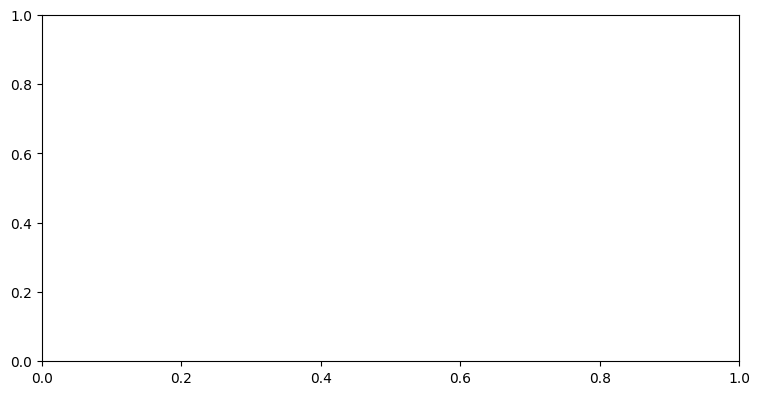

In [141]:
# Step 334: Save feature-selection comparison plot

from pathlib import Path
import matplotlib.pyplot as plt

print("=== Step 334: Feature Selection Plot ===")

p = session.results_store["pearson_filter_9"]["record"].summary
s = session.results_store["spearman_filter_10"]["record"].summary

pearson = set(p["kept_terms"])
spearman = set(s["kept_terms"])

counts = [
    len(pearson - spearman),
    len(pearson & spearman),
    len(spearman - pearson)
]

labels = [
    "Pearson only",
    "Selected by both",
    "Spearman only"
]

assert counts == [169, 2824, 292], counts

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar

In [142]:
# Step 334A: Diagnose saved plot

from pathlib import Path
import matplotlib.pyplot as plt

print("=== Step 334A: Plot Diagnosis ===")

plot_path = Path(
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png"
)

print("File exists:", plot_path.exists())

if plot_path.exists():
    print("File size:", plot_path.stat().st_size, "bytes")

    from PIL import Image

    with Image.open(plot_path) as img:
        print("Image dimensions:", img.size)
        display(img.copy())

print("\nOpen Matplotlib figures:", plt.get_fignums())
print("Main DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 334A: COMPLETE")

=== Step 334A: Plot Diagnosis ===
File exists: False

Open Matplotlib figures: []
Main DTM: (1079, 19666)
Stored results: 10
Step 334A: COMPLETE


=== Step 334B: Rebuild Plot ===
Image dimensions: (1601, 787)


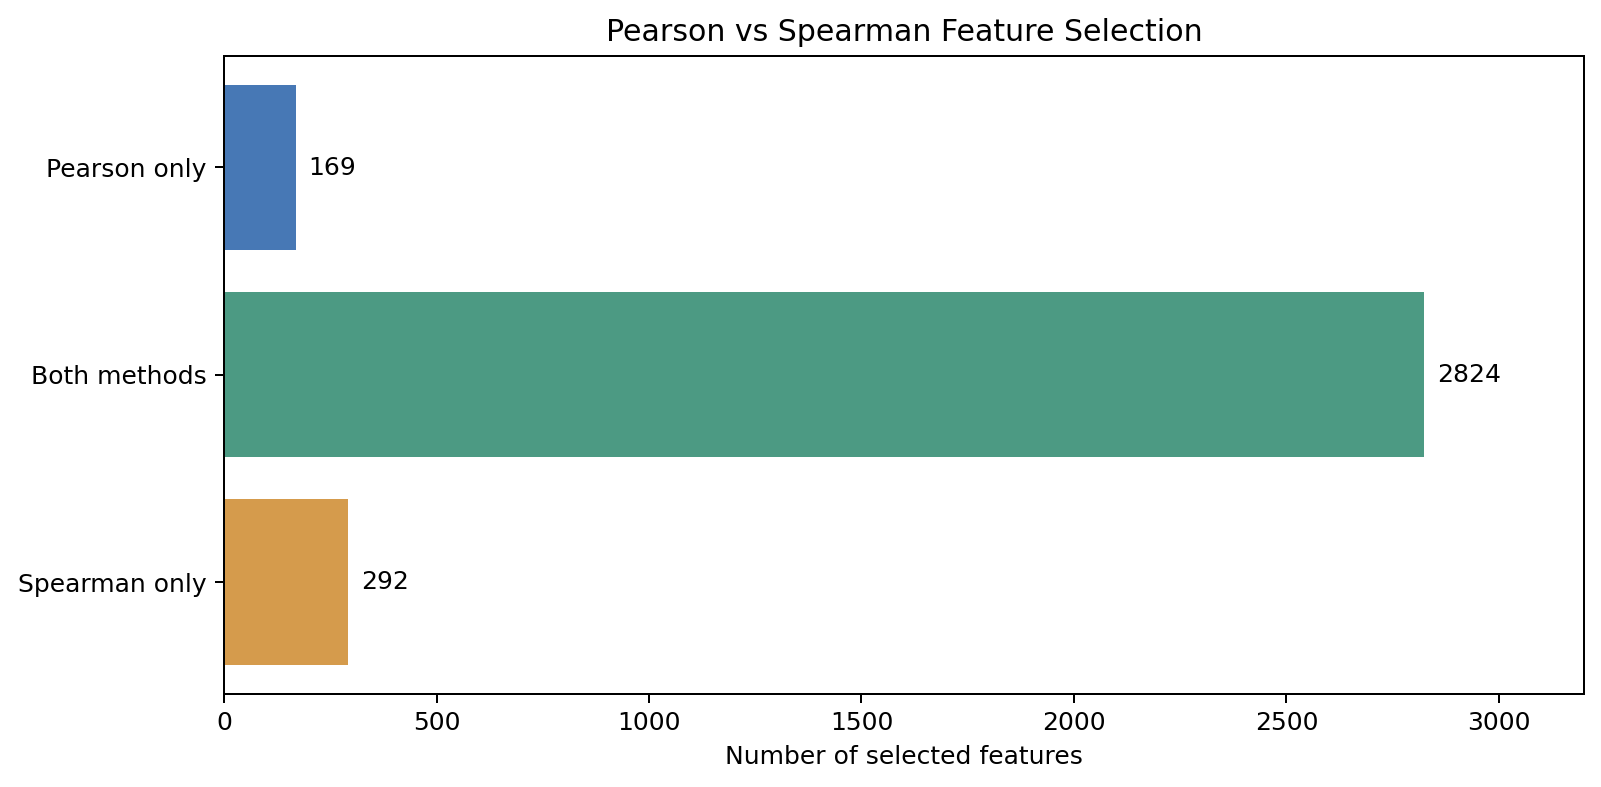

Saved: plots\李中信_agentic-pipeline_feature_selection_comparison.png
File size: 36690 bytes
Counts: [169, 2824, 292]
Main DTM: (1079, 19666)
Stored results: 10
Step 334B: COMPLETE


In [143]:
# Step 334B: Rebuild and verify comparison chart

from pathlib import Path
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt

print("=== Step 334B: Rebuild Plot ===")

p = session.results_store["pearson_filter_9"]["record"].summary
s = session.results_store["spearman_filter_10"]["record"].summary

P = set(p["kept_terms"])
S = set(s["kept_terms"])

labels = ["Pearson only", "Both methods", "Spearman only"]
counts = [len(P - S), len(P & S), len(S - P)]

assert counts == [169, 2824, 292], counts

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.barh(
    labels,
    counts,
    color=["#4778B5", "#4C9A83", "#D59B4C"]
)

for bar, count in zip(bars, counts):
    ax.text(
        count + 30,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        va="center"
    )

ax.set_xlim(0, 3200)
ax.set_xlabel("Number of selected features")
ax.set_title("Pearson vs Spearman Feature Selection")
ax.invert_yaxis()

fig.tight_layout()

path = Path(
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png"
)
path.parent.mkdir(exist_ok=True)

fig.savefig(path, dpi=180, bbox_inches="tight")
plt.close(fig)

assert path.is_file(), "PNG was not created"

with Image.open(path) as img:
    print("Image dimensions:", img.size)
    display(img.copy())

print("Saved:", path)
print("File size:", path.stat().st_size, "bytes")
print("Counts:", counts)
print("Main DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 334B: COMPLETE")

In [144]:
# Step 335: Embed verified chart into report

from pathlib import Path

print("=== Step 335: Embed Analysis Plot ===")

report_path = Path(
    "reports/李中信_d11409105_agentic-pipeline_report.md"
)

plot_path = Path(
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png"
)

assert report_path.is_file(), "Report not found"
assert plot_path.is_file(), "Plot not found"

text = report_path.read_text(encoding="utf-8")

image_link = (
    "![Pearson and Spearman feature selection comparison]"
    "(../plots/李中信_agentic-pipeline_feature_selection_comparison.png)"
)

figure_section = (
    "\n\n### Feature Selection Comparison Figure\n\n"
    + image_link
    + "\n\n"
    + "The figure shows 2,824 features selected by both methods, "
    + "169 selected only by Pearson, and 292 selected only by "
    + "Spearman. It was generated separately from the Agent "
    + "conversation using the stored results "
    + "`pearson_filter_9` and `spearman_filter_10`.\n"
)

if image_link not in text:
    backup = report_path.with_suffix(".step335.bak")
    if not backup.exists():
        backup.write_text(text, encoding="utf-8")

    report_path.write_text(
        text + figure_section,
        encoding="utf-8"
    )
    print("Figure embedded successfully")
else:
    print("Figure already embedded; no changes made")

updated = report_path.read_text(encoding="utf-8")

print("Report:", report_path)
print("Image link present:", image_link in updated)
print("Plot exists:", plot_path.exists())
print("Report sections:", updated.count("\n## "))
print("Report size:", report_path.stat().st_size, "bytes")
print("Main DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 335: COMPLETE")

=== Step 335: Embed Analysis Plot ===
Figure embedded successfully
Report: reports\李中信_d11409105_agentic-pipeline_report.md
Image link present: True
Plot exists: True
Report sections: 4
Report size: 2269 bytes
Main DTM: (1079, 19666)
Stored results: 10
Step 335: COMPLETE


In [145]:
# Step 336: Git and submission readiness check

import subprocess
from pathlib import Path

print("=== Step 336: Git Submission Check ===")

commands = [
    ["git", "status", "--short"],
    ["git", "branch", "--show-current"],
    ["git", "remote", "-v"],
    ["git", "ls-files", "session_logs", "plots", "reports"]
]

for cmd in commands:
    print("\n$", " ".join(cmd))
    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        timeout=30
    )
    print(result.stdout.strip() or "(no output)")
    if result.returncode != 0:
        print("ERROR:", result.stderr.strip())

print("\n=== Required Files ===")

required = [
    "session_logs/agent_dev_session.jsonl.enc",
    "session_logs/agent_pipeline_session.jsonl.enc",
    "reports/李中信_d11409105_agentic-pipeline_report.md",
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png"
]

for name in required:
    p = Path(name)
    print(
        "OK" if p.is_file() else "MISSING",
        name,
        f"({p.stat().st_size} bytes)" if p.is_file() else ""
    )

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 336: COMPLETE")

=== Step 336: Git Submission Check ===

$ git status --short
M DM2026-Lab1-AgentDev.ipynb
 M DM2026-Lab1-AgenticPipeline.ipynb
 M DM2026-Lab1-Master.ipynb
 M helpers/text_filtering_helpers.py
 M output_files/text_transformation/term_frequencies/term_frequency_distribution_log.png
?? output_files/text_transformation/term_frequencies/term_frequency_distribution_log_top50.png
?? reports/
?? tests/

$ git branch --show-current
main

$ git remote -v
origin	https://github.com/d11409105/DM2026-Lab1-Exercise.git (fetch)
origin	https://github.com/d11409105/DM2026-Lab1-Exercise.git (push)

$ git ls-files session_logs plots reports
(no output)

=== Required Files ===
OK session_logs/agent_dev_session.jsonl.enc (148831 bytes)
OK session_logs/agent_pipeline_session.jsonl.enc (32203 bytes)
OK reports/李中信_d11409105_agentic-pipeline_report.md (2269 bytes)
OK plots/李中信_agentic-pipeline_feature_selection_comparison.png (36690 bytes)

Main DTM: (1079, 19666)
Stored results: 10
Step 336: COMPLETE


In [146]:
# Step 337: Inspect Git ignore rules and submission files

import subprocess
from pathlib import Path

print("=== Step 337: Git Ignore Inspection ===")

paths = [
    "session_logs/agent_dev_session.jsonl.enc",
    "session_logs/agent_pipeline_session.jsonl.enc",
    "session_logs/agent_pipeline_gemini_session.jsonl.enc",
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png",
    "reports/李中信_d11409105_agentic-pipeline_report.md",
]

for path in paths:
    result = subprocess.run(
        ["git", "check-ignore", "-v", path],
        capture_output=True,
        text=True,
        timeout=15
    )

    print("\nFile:", path)
    print("Exists:", Path(path).is_file())
    print(
        "Ignore rule:",
        result.stdout.strip() if result.returncode == 0
        else "(not ignored)"
    )

print("\n=== Test Files ===")

for path in sorted(Path("tests").glob("test_tools_*.py")):
    print(path.name)

print("\n=== Workspace Backup Files ===")

for path in sorted(Path("agent_dev_workspace").glob("*.bak")):
    print(path.name)

print("\n=== Git Ignore File ===")

ignore_path = Path(".gitignore")
if ignore_path.exists():
    print(ignore_path.read_text(encoding="utf-8")[:4000])
else:
    print("No .gitignore found")

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 337: COMPLETE")

=== Step 337: Git Ignore Inspection ===

File: session_logs/agent_dev_session.jsonl.enc
Exists: True
Ignore rule: .gitignore:51:session_logs/*.jsonl.enc	session_logs/agent_dev_session.jsonl.enc

File: session_logs/agent_pipeline_session.jsonl.enc
Exists: True
Ignore rule: .gitignore:51:session_logs/*.jsonl.enc	session_logs/agent_pipeline_session.jsonl.enc

File: session_logs/agent_pipeline_gemini_session.jsonl.enc
Exists: True
Ignore rule: .gitignore:51:session_logs/*.jsonl.enc	session_logs/agent_pipeline_gemini_session.jsonl.enc

File: plots/李中信_agentic-pipeline_feature_selection_comparison.png
Exists: True
Ignore rule: .gitignore:52:plots/*.png	"plots/\346\235\216\344\270\255\344\277\241_agentic-pipeline_feature_selection_comparison.png"

File: reports/李中信_d11409105_agentic-pipeline_report.md
Exists: True
Ignore rule: .gitignore:53:reports/*.md	"reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.md"

=== Test Files ===
test_tools_data.py
test_tools_dtm.py


In [147]:
# Step 338: Inspect student tool source files

from pathlib import Path
import subprocess

print("=== Step 338: Student Tool Submission Audit ===")

workspace = Path("agent_dev_workspace")

source_files = sorted(workspace.glob("*.py"))

print("\n=== Python Source Files ===")

for path in source_files:
    print(
        path.name,
        "| bytes:", path.stat().st_size
    )

print("\nTotal Python source files:", len(source_files))

print("\n=== Backup Files ===")

backups = [
    p for p in workspace.iterdir()
    if p.is_file() and p.suffix == ".bak"
]

print("Backup files:", len(backups))

print("\n=== Git Tracking Check ===")

for path in source_files:
    r = subprocess.run(
        ["git", "ls-files", "--error-unmatch", str(path)],
        capture_output=True,
        text=True
    )

    status = "TRACKED" if r.returncode == 0 else "NOT TRACKED"
    print(status, path.name)

print("\n=== Security Check ===")

print("config/.env exists:", Path("config/.env").exists())
print("No files staged or committed by this cell")

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("Step 338: COMPLETE")

=== Step 338: Student Tool Submission Audit ===

=== Python Source Files ===
tools_data.py | bytes: 12455
tools_dtm.py | bytes: 8909
tools_exploration.py | bytes: 5358
tools_filtering.py | bytes: 10553
tools_patterns.py | bytes: 6308
tools_reduction.py | bytes: 6468

Total Python source files: 6

=== Backup Files ===
Backup files: 20

=== Git Tracking Check ===
NOT TRACKED tools_data.py
NOT TRACKED tools_dtm.py
NOT TRACKED tools_exploration.py
NOT TRACKED tools_filtering.py
NOT TRACKED tools_patterns.py
NOT TRACKED tools_reduction.py

=== Security Check ===
config/.env exists: True
No files staged or committed by this cell

Main DTM: (1079, 19666)
Stored results: 10
Step 338: COMPLETE


In [148]:
# Step 339: Stage submission files safely

import subprocess
from pathlib import Path

print("=== Step 339: Stage Submission Files ===")

tool_files = sorted(
    str(p) for p in Path("agent_dev_workspace").glob("*.py")
)

test_files = sorted(
    str(p) for p in Path("tests").glob("test_tools_*.py")
)

required_files = [
    "DM2026-Lab1-AgentDev.ipynb",
    "DM2026-Lab1-AgenticPipeline.ipynb",
    "DM2026-Lab1-Master.ipynb",
    "helpers/text_filtering_helpers.py",
    "session_logs/agent_dev_session.jsonl.enc",
    "session_logs/agent_pipeline_session.jsonl.enc",
    "session_logs/agent_pipeline_gemini_session.jsonl.enc",
    "reports/李中信_d11409105_agentic-pipeline_report.md",
    "plots/李中信_agentic-pipeline_feature_selection_comparison.png",
]

files = tool_files + test_files + required_files

missing = [f for f in files if not Path(f).is_file()]
assert not missing, f"Missing files: {missing}"

print("Files selected:", len(files))

result = subprocess.run(
    ["git", "add", "-f", "--", *files],
    capture_output=True,
    text=True,
    timeout=60
)

print("Git add exit code:", result.returncode)

if result.stderr:
    print("Git message:", result.stderr)

if result.returncode == 0:
    status = subprocess.run(
        ["git", "diff", "--cached", "--name-only"],
        capture_output=True,
        text=True,
        timeout=30
    )
    print("\n=== Staged Files ===")
    print(status.stdout)
else:
    print("Staging failed; do not commit yet.")

print("Step 339: COMPLETE")

=== Step 339: Stage Submission Files ===
Files selected: 21
Git add exit code: 0
Git message: warning: in the working copy of 'helpers/text_filtering_helpers.py', CRLF will be replaced by LF the next time Git touches it


=== Staged Files ===
DM2026-Lab1-AgentDev.ipynb
DM2026-Lab1-AgenticPipeline.ipynb
DM2026-Lab1-Master.ipynb
agent_dev_workspace/tools_data.py
agent_dev_workspace/tools_dtm.py
agent_dev_workspace/tools_exploration.py
agent_dev_workspace/tools_filtering.py
agent_dev_workspace/tools_patterns.py
agent_dev_workspace/tools_reduction.py
helpers/text_filtering_helpers.py
"plots/\346\235\216\344\270\255\344\277\241_agentic-pipeline_feature_selection_comparison.png"
"reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.md"
session_logs/agent_dev_session.jsonl.enc
session_logs/agent_pipeline_gemini_session.jsonl.enc
session_logs/agent_pipeline_session.jsonl.enc
tests/test_tools_data.py
tests/test_tools_dtm.py
tests/test_tools_exploration.py
tests/test_to

In [149]:
# Step 340: Pre-commit safety audit

import subprocess
from pathlib import Path

print("=== Step 340: Pre-Commit Audit ===")

r = subprocess.run(
    ["git", "diff", "--cached", "--name-only", "-z"],
    capture_output=True,
    timeout=30
)

assert r.returncode == 0

staged = [
    x.decode("utf-8")
    for x in r.stdout.split(b"\0")
    if x
]

print("Staged files:", len(staged))

forbidden = [
    p for p in staged
    if (
        p.endswith(".bak")
        or p.endswith(".env")
        or "__pycache__" in p
        or "/keys/grading_private" in p
    )
]

print("Forbidden files:", forbidden)

report = Path(
    "reports/李中信_d11409105_agentic-pipeline_report.md"
).read_text(encoding="utf-8")

print(
    "Report placeholder present:",
    "Replace this with your own report" in report
)

print(
    "Report image reference:",
    "../plots/" in report
)

check = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    capture_output=True,
    text=True,
    timeout=30
)

print("Git whitespace check:", check.returncode)
if check.stdout:
    print(check.stdout[:1500])
if check.stderr:
    print(check.stderr[:1500])

safe = (
    len(staged) == 21
    and not forbidden
    and "Replace this with your own report" not in report
    and "../plots/" in report
    and check.returncode == 0
)

print("Pre-commit audit:", "PASS" if safe else "REVIEW REQUIRED")
print("No commit or push performed")
print("Step 340: COMPLETE")

=== Step 340: Pre-Commit Audit ===
Staged files: 21
Forbidden files: []
Report placeholder present: False
Report image reference: True
Git whitespace check: 0
Pre-commit audit: PASS
No commit or push performed
Step 340: COMPLETE


In [150]:
# Step 341: Commit staged assignment files

import subprocess

print("=== Step 341: Git Commit ===")

message = "Complete Lab 1 agent tools, tests and pipeline report"

r = subprocess.run(
    ["git", "commit", "-m", message],
    capture_output=True,
    text=True,
    timeout=120
)

print("=== Commit Output ===")
print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Commit exit code:", r.returncode)

if r.returncode == 0:
    h = subprocess.run(
        ["git", "log", "-1", "--format=%h %s"],
        capture_output=True,
        text=True,
        timeout=30
    )
    print("Latest commit:", h.stdout.strip())
else:
    print("Commit failed; do not push yet.")

print("Step 341: COMPLETE")

=== Step 341: Git Commit ===
=== Commit Output ===
[main 0e4b649] Complete Lab 1 agent tools, tests and pipeline report
 21 files changed, 36051 insertions(+), 1022 deletions(-)
 create mode 100644 agent_dev_workspace/tools_data.py
 create mode 100644 agent_dev_workspace/tools_dtm.py
 create mode 100644 agent_dev_workspace/tools_exploration.py
 create mode 100644 agent_dev_workspace/tools_filtering.py
 create mode 100644 agent_dev_workspace/tools_patterns.py
 create mode 100644 agent_dev_workspace/tools_reduction.py
 create mode 100644 "plots/\346\235\216\344\270\255\344\277\241_agentic-pipeline_feature_selection_comparison.png"
 create mode 100644 "reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.md"
 create mode 100644 session_logs/agent_dev_session.jsonl.enc
 create mode 100644 session_logs/agent_pipeline_gemini_session.jsonl.enc
 create mode 100644 session_logs/agent_pipeline_session.jsonl.enc
 create mode 100644 tests/test_tools_data.py
 create mode 1

In [151]:
# Step 342: Push committed assignment to GitHub

import subprocess

print("=== Step 342: GitHub Push ===")

r = subprocess.run(
    ["git", "push", "origin", "main"],
    capture_output=True,
    text=True,
    timeout=180
)

print("=== Push Output ===")
print(r.stdout)

if r.stderr:
    print("STDERR:", r.stderr)

print("Push exit code:", r.returncode)
print("GitHub push:", "PASS" if r.returncode == 0 else "FAIL")
print("Step 342: COMPLETE")

=== Step 342: GitHub Push ===


TimeoutExpired: Command '['git', 'push', 'origin', 'main']' timed out after 180 seconds

In [152]:
# Step 343: Diagnose GitHub push timeout

import subprocess

print("=== Step 343: GitHub Push Diagnosis ===")

commands = [
    ("Local Commit", ["git", "log", "-1", "--format=%h %s"]),
    ("Branch Status", ["git", "status", "-sb"]),
    ("Remote URL", ["git", "remote", "-v"]),
    ("Remote Tracking Commit", [
        "git", "log", "-1", "--format=%h %s", "refs/remotes/origin/main"
    ]),
]

for title, command in commands:
    print(f"\n=== {title} ===")

    try:
        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=15
        )

        print(result.stdout.strip() or "(no output)")

        if result.stderr:
            print("Message:", result.stderr.strip())

        print("Exit code:", result.returncode)

    except subprocess.TimeoutExpired:
        print("TIMEOUT")

print("\n=== Commit Comparison ===")

local = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    capture_output=True,
    text=True
)

remote = subprocess.run(
    ["git", "rev-parse", "refs/remotes/origin/main"],
    capture_output=True,
    text=True
)

if local.returncode == 0 and remote.returncode == 0:
    print("Local HEAD:", local.stdout.strip())
    print("Tracked origin/main:", remote.stdout.strip())
    print("Same commit:", local.stdout.strip() == remote.stdout.strip())
    print("Note: origin/main is a local cached reference, not a live GitHub check.")
else:
    print("Unable to compare commits.")

print("\nNo push, fetch, or commit performed.")
print("Step 343: COMPLETE")

=== Step 343: GitHub Push Diagnosis ===

=== Local Commit ===
0e4b649 Complete Lab 1 agent tools, tests and pipeline report
Exit code: 0

=== Branch Status ===
## main...origin/main
 M DM2026-Lab1-AgenticPipeline.ipynb
 M output_files/text_transformation/term_frequencies/term_frequency_distribution_log.png
?? output_files/text_transformation/term_frequencies/term_frequency_distribution_log_top50.png
?? "reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.step333.bak"
?? "reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.step335.bak"
?? tests/test_tools_data.py.step300.bak
?? tests/test_tools_exploration.py.step320.bak
?? tests/test_tools_exploration.py.step322.bak
?? tests/test_tools_exploration.py.step324.bak
?? tests/test_tools_patterns.before_step171.bak
?? tests/test_tools_patterns.before_step173.bak
?? tests/test_tools_reduction.py.step305.bak
?? tests/test_tools_reduction.py.step307.bak
?? tests/test_tools_reduction.py.step3

In [153]:
# Step 344: Verify commit directly on GitHub

import subprocess

print("=== Step 344: Verify GitHub Remote ===")

local = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    capture_output=True,
    text=True,
    timeout=10
)

print("Local HEAD:", local.stdout.strip())

try:
    remote = subprocess.run(
        ["git", "-c", "credential.interactive=never",
         "ls-remote", "origin", "refs/heads/main"],
        capture_output=True,
        text=True,
        timeout=30
    )

    print("Remote query exit code:", remote.returncode)

    if remote.returncode == 0 and remote.stdout.strip():
        remote_hash = remote.stdout.split()[0]
        local_hash = local.stdout.strip()

        print("GitHub main:", remote_hash)
        print("Local HEAD: ", local_hash)

        if remote_hash == local_hash:
            print("GitHub verification: PASS")
            print("Commit 0e4b649 is on GitHub.")
        else:
            print("GitHub verification: NOT MATCHED")
            print("Further investigation required.")
    else:
        print("GitHub verification: INCONCLUSIVE")
        print("Message:", remote.stderr.strip()[:500])

except subprocess.TimeoutExpired:
    print("GitHub verification: TIMEOUT")
    print("Network or authentication may still be blocking access.")

print("\nNo push, fetch, or commit performed.")
print("Step 344: COMPLETE")


=== Step 344: Verify GitHub Remote ===
Local HEAD: 0e4b6498ea9c021b08ea3b8a47bb8675b65432ef
Remote query exit code: 0
GitHub main: 0e4b6498ea9c021b08ea3b8a47bb8675b65432ef
Local HEAD:  0e4b6498ea9c021b08ea3b8a47bb8675b65432ef
GitHub verification: PASS
Commit 0e4b649 is on GitHub.

No push, fetch, or commit performed.
Step 344: COMPLETE


In [154]:
# Step 345: Final Submission Completeness Audit

from pathlib import Path
import subprocess
import re

print("=== Step 345: Submission Completeness Audit ===")

def git_output(*args):
    r = subprocess.run(
        ["git", *args],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=30
    )
    return r.stdout if r.returncode == 0 else ""

tracked = set(
    git_output("ls-files", "-z").split("\0")
)
tracked.discard("")

required_logs = [
    "session_logs/agent_pipeline_session.jsonl.enc",
    "session_logs/agent_dev_session.jsonl.enc",
]

print("\n=== 1. Required Session Logs ===")

for name in required_logs:
    p = Path(name)
    print(
        name,
        "| Exists:", p.is_file(),
        "| Git tracked:", name in tracked
    )

print("\n=== 2. Plots Directory ===")

plots = sorted(
    p for p in Path("plots").rglob("*.png")
    if p.is_file()
)

print("Total PNG plots:", len(plots))

for p in plots:
    name = p.as_posix()
    print(
        name,
        "| Git tracked:", name in tracked
    )

print("\n=== 3. Official Agent Plot Naming ===")

official_plots = [
    p for p in plots
    if re.match(
        r"^.+_agentic-pipeline_plot_.+\.png$",
        p.name
    )
]

print("Official-pattern plots:", len(official_plots))

for p in official_plots:
    print(p.as_posix())

print("\n=== 4. Report Verification ===")

report_path = Path(
    "reports/李中信_d11409105_agentic-pipeline_report.md"
)

print("Report exists:", report_path.is_file())
print(
    "Report Git tracked:",
    report_path.as_posix() in tracked
)

if report_path.is_file():

    report = report_path.read_text(encoding="utf-8")

    references = re.findall(
        r"!\[[^\]]*\]\(([^)]+)\)",
        report
    )

    print("Image references:", len(references))

    for ref in references:
        target = report_path.parent / ref
        print(
            ref,
            "| Exists:", target.is_file()
        )

print("\n=== 5. Untracked Submission Files ===")

for folder in ["plots", "reports", "session_logs"]:
    r = subprocess.run(
        ["git", "status", "--short", "--untracked-files=all", "--", folder],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        timeout=30
    )
    print(f"\n{folder}:")
    print(r.stdout.strip() or "(no visible changes)")

print("\nNo files modified, staged, committed, or pushed.")
print("Step 345: COMPLETE")

=== Step 345: Submission Completeness Audit ===

=== 1. Required Session Logs ===
session_logs/agent_pipeline_session.jsonl.enc | Exists: True | Git tracked: True
session_logs/agent_dev_session.jsonl.enc | Exists: True | Git tracked: True

=== 2. Plots Directory ===
Total PNG plots: 1
plots/李中信_agentic-pipeline_feature_selection_comparison.png | Git tracked: True

=== 3. Official Agent Plot Naming ===
Official-pattern plots: 0

=== 4. Report Verification ===
Report exists: True
Report Git tracked: True
Image references: 1
../plots/李中信_agentic-pipeline_feature_selection_comparison.png | Exists: True

=== 5. Untracked Submission Files ===

plots:
(no visible changes)

reports:
?? "reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.step333.bak"
?? "reports/\346\235\216\344\270\255\344\277\241_d11409105_agentic-pipeline_report.step335.bak"

session_logs:
(no visible changes)

No files modified, staged, committed, or pushed.
Step 345: COMPLETE


In [155]:
# Step 346: Audit plot-producing tool executions

from pathlib import Path

print("=== Step 346: Plot-Producing Tool Audit ===")

plot_tools = {
    "reduce_dimensions_tool",
    "visualize_result_tool",
}

found = []

for result_id, entry in session.results_store.items():
    record = entry.get("record")
    tool_name = getattr(record, "tool_name", "UNKNOWN")

    print(f"{result_id} | {tool_name}")

    if tool_name in plot_tools:
        found.append((result_id, tool_name))

print("\n=== Plot-Producing Results ===")
print("Count:", len(found))

for result_id, tool_name in found:
    print(result_id, "|", tool_name)

print("\n=== Saved PNG Files ===")
for path in sorted(Path("plots").glob("*.png")):
    print(path.name)

if not found:
    print("\nNo plot-producing tool results found in the current session.")
    print("Missing official-pattern plots may therefore be expected.")
else:
    print("\nPlot-producing results exist; inspect their saved images.")

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("No files modified.")
print("Step 346: COMPLETE")

=== Step 346: Plot-Producing Tool Audit ===
list_files_1 | list_files_tool
load_dataset_2 | load_dataset
check_missing_3 | check_missing_tool
check_duplicates_4 | check_duplicates_tool
tokenize_5 | tokenize_tool
build_dtm_6 | build_dtm_tool
term_frequency_7 | term_frequency_tool
variance_filter_8 | variance_filter_tool
pearson_filter_9 | pearson_filter_tool
spearman_filter_10 | spearman_filter_tool

=== Plot-Producing Results ===
Count: 0

=== Saved PNG Files ===
李中信_agentic-pipeline_feature_selection_comparison.png

No plot-producing tool results found in the current session.
Missing official-pattern plots may therefore be expected.

Main DTM: (1079, 19666)
Stored results: 10
No files modified.
Step 346: COMPLETE


In [156]:
# Step 347: Agent Conversation Coverage Audit

print("=== Step 347: Agent Conversation Audit ===")

states = {
    "Groq Agent": globals().get("graph_state_208"),
    "Gemini Agent": globals().get("gemini_graph_state"),
}

for agent_name, state in states.items():
    print(f"\n=== {agent_name} ===")

    if state is None:
        print("State not available")
        continue

    print("State type:", type(state).__name__)

    if isinstance(state, dict):
        print("State keys:", list(state.keys()))

        messages = state.get("messages", [])

        print("Messages:", len(messages))

        for i, msg in enumerate(messages):
            role = type(msg).__name__
            content = str(getattr(msg, "content", ""))

            tool_calls = getattr(msg, "tool_calls", None) or []

            print(
                f"{i:02d} | {role} | "
                f"tool_calls={len(tool_calls)} | "
                f"content={content[:120]!r}"
            )

            for call in tool_calls:
                print(
                    "     TOOL:",
                    call.get("name"),
                    "| ID:",
                    call.get("id")
                )
    else:
        print("State representation:", repr(state)[:500])

print("\n=== Session Results ===")

for result_id, entry in session.results_store.items():
    record = entry.get("record")
    print(
        result_id,
        "|",
        getattr(record, "tool_name", "UNKNOWN")
    )

print("\nMain DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))
print("No files modified.")
print("Step 347: COMPLETE")

=== Step 347: Agent Conversation Audit ===

=== Groq Agent ===
State not available

=== Gemini Agent ===
State type: dict
State keys: ['messages']
Messages: 4
00 | HumanMessage | tool_calls=0 | content='Please call tokenize_tool on the dataset already loaded in the current session. The dataset contains 1,079 documents fro'
01 | AIMessage | tool_calls=1 | content='[]'
     TOOL: tokenize_tool | ID: call_536733
02 | ToolMessage | tool_calls=0 | content="{'result_id': 'tokenize_5', 'n_documents': 1079, 'total_tokens': 491375, 'sample_unigrams': [['from', ':', 'nigel.allen'"
03 | AIMessage | tool_calls=0 | content='[{\'type\': \'text\', \'text\': "Here are the details returned by the `tokenize_tool`:\\n\\n* **Result ID:** tokenize_5\\n* **Doc'

=== Session Results ===
list_files_1 | list_files_tool
load_dataset_2 | load_dataset
check_missing_3 | check_missing_tool
check_duplicates_4 | check_duplicates_tool
tokenize_5 | tokenize_tool
build_dtm_6 | build_dtm_tool
term_frequency_7 | term_freq

In [157]:
# Step 348: Locate Groq Agent conversation state

print("=== Step 348: Groq Agent State Inspection ===")

candidate_names = [
    "graph_state",
    "graph_state_208",
    "gemini_graph_state",
]

for name in candidate_names:
    print(f"\n=== {name} ===")

    state = globals().get(name)

    if state is None:
        print("Not available")
        continue

    print("Type:", type(state).__name__)

    if not isinstance(state, dict):
        print("Representation:", repr(state)[:300])
        continue

    print("Keys:", list(state.keys()))

    messages = state.get("messages", [])
    print("Message count:", len(messages))

    for i, msg in enumerate(messages):
        role = type(msg).__name__
        calls = getattr(msg, "tool_calls", None) or []
        content = str(getattr(msg, "content", ""))

        print(
            f"{i:02d} | {role} | "
            f"calls={len(calls)} | "
            f"{content[:100]!r}"
        )

        for call in calls:
            print("    TOOL:", call.get("name"))

print("\n=== Related Variables ===")

for name in sorted(globals()):
    if any(
        keyword in name.lower()
        for keyword in ["graph_state", "logger", "chat"]
    ):
        if not name.startswith("_"):
            print(name, "|", type(globals()[name]).__name__)

print("\nNo files modified.")
print("Step 348: COMPLETE")

=== Step 348: Groq Agent State Inspection ===

=== graph_state ===
Type: dict
Keys: ['messages']
Message count: 36
00 | HumanMessage | calls=0 | 'Please list all tools currently available to you using list_available_tools_tool. Make exactly one t'
01 | AIMessage | calls=1 | ''
    TOOL: list_available_tools_tool
02 | ToolMessage | calls=0 | "{'tools': [{'name': 'binarize_labels_tool', 'description': 'One-hot encode document category labels."
03 | AIMessage | calls=0 | 'Here are the tools that are currently known, together with whether they have been granted access (i.'
04 | HumanMessage | calls=0 | 'I want you to use list_files_tool to inspect the current project directory. If access to my student-'
05 | AIMessage | calls=1 | ''
    TOOL: request_tool_access_tool
06 | ToolMessage | calls=0 | "{'status': 'pending_approval', 'tool_names': ['binarize_labels_tool', 'build_dtm_tool', 'check_dupli"
07 | AIMessage | calls=0 | 'I’ve submitted a request for access to all of the student‑built to

In [158]:
# Step 349: Inspect Agent log metadata safely

from pathlib import Path

print("=== Step 349: Agent Log Integrity ===")

logs = [
    "session_logs/agent_pipeline_session.jsonl.enc",
    "session_logs/agent_pipeline_gemini_session.jsonl.enc",
    "session_logs/agent_dev_session.jsonl.enc",
]

for name in logs:
    path = Path(name)
    print("\nFile:", name)
    print("Exists:", path.is_file())

    if path.is_file():
        print("Size:", path.stat().st_size, "bytes")
        print("Modified:", path.stat().st_mtime)

print("\n=== Agent Message Counts ===")

for name, state in [
    ("Groq", globals().get("graph_state")),
    ("Gemini", globals().get("gemini_graph_state")),
]:
    messages = state.get("messages", []) if isinstance(state, dict) else []
    tool_calls = sum(
        len(getattr(m, "tool_calls", None) or [])
        for m in messages
    )

    print(name, "| messages:", len(messages),
          "| tool calls:", tool_calls)

print("\n=== Logger Objects ===")

for name in ["logger", "gemini_logger"]:
    obj = globals().get(name)
    print(name, "| type:", type(obj).__name__)

print("\nNo files modified.")
print("Step 349: COMPLETE")

=== Step 349: Agent Log Integrity ===

File: session_logs/agent_pipeline_session.jsonl.enc
Exists: True
Size: 32203 bytes
Modified: 1791696260.265978

File: session_logs/agent_pipeline_gemini_session.jsonl.enc
Exists: True
Size: 24902 bytes
Modified: 1791696605.9828992

File: session_logs/agent_dev_session.jsonl.enc
Exists: True
Size: 148831 bytes
Modified: 1791684427.4836836

=== Agent Message Counts ===
Groq | messages: 36 | tool calls: 9
Gemini | messages: 4 | tool calls: 1

=== Logger Objects ===
logger | type: SessionLogger
gemini_logger | type: SessionLogger

No files modified.
Step 349: COMPLETE


In [159]:
# Step 350: Agent conversation compliance audit

print("=== Step 350: Agent Conversation Compliance ===")

states = {
    "Groq": globals().get("graph_state"),
    "Gemini": globals().get("gemini_graph_state"),
}

for agent_name, state in states.items():
    print(f"\n=== {agent_name} ===")

    if not isinstance(state, dict):
        print("State unavailable")
        continue

    messages = state.get("messages", [])
    violations = []
    tool_count = 0

    for i, msg in enumerate(messages):
        role = type(msg).__name__
        calls = getattr(msg, "tool_calls", None) or []

        if role != "AIMessage" or not calls:
            continue

        tool_count += len(calls)

        if len(calls) > 1:
            violations.append(
                f"Message {i}: multiple tool calls"
            )

        if i + 1 >= len(messages):
            violations.append(
                f"Message {i}: missing tool response"
            )
            continue

        next_role = type(messages[i + 1]).__name__

        if next_role != "ToolMessage":
            violations.append(
                f"Message {i}: next message is {next_role}"
            )

        if i + 2 >= len(messages):
            violations.append(
                f"Message {i}: missing AI explanation"
            )
        else:
            explanation_role = type(messages[i + 2]).__name__

            if explanation_role != "AIMessage":
                violations.append(
                    f"Message {i}: explanation is "
                    f"{explanation_role}"
                )

    print("Messages:", len(messages))
    print("Tool calls:", tool_count)
    print("Structural violations:", len(violations))

    for issue in violations:
        print("WARNING:", issue)

    if not violations:
        print("Structural compliance: PASS")

print("\n=== Authorization Evidence ===")

groq_messages = (
    states["Groq"].get("messages", [])
    if isinstance(states["Groq"], dict)
    else []
)

for i, msg in enumerate(groq_messages):
    for call in getattr(msg, "tool_calls", None) or []:
        name = call.get("name", "")

        if name in {
            "request_tool_access_tool",
            "grant_tool_access_tool",
            "list_files_tool",
        }:
            print(i, "|", name)

print("\nNo files modified.")
print("Step 350: COMPLETE")

=== Step 350: Agent Conversation Compliance ===

=== Groq ===
Messages: 36
Tool calls: 9
Structural violations: 0
Structural compliance: PASS

=== Gemini ===
Messages: 4
Tool calls: 1
Structural violations: 0
Structural compliance: PASS

=== Authorization Evidence ===
5 | request_tool_access_tool
9 | grant_tool_access_tool
13 | list_files_tool

No files modified.
Step 350: COMPLETE


In [160]:
# Step 351: Agent Analysis Coverage Audit

print("=== Step 351: Agent Analysis Coverage ===")

states = {
    "Groq": globals().get("graph_state"),
    "Gemini": globals().get("gemini_graph_state"),
}

agent_calls = {}

for agent_name, state in states.items():
    if not isinstance(state, dict):
        continue

    for msg in state.get("messages", []):
        for call in getattr(msg, "tool_calls", None) or []:
            name = call.get("name", "")
            agent_calls.setdefault(name, set()).add(agent_name)

print("\n=== Agent Tool Calls ===")

for name in sorted(agent_calls):
    print(name, "|", ", ".join(sorted(agent_calls[name])))

print("\n=== Stored Analysis Results ===")

covered = 0
direct_only = 0

for result_id, entry in session.results_store.items():
    record = entry.get("record")
    tool_name = getattr(record, "tool_name", "UNKNOWN")

    if tool_name in agent_calls:
        status = "AGENT CALLED"
        covered += 1
    else:
        status = "NOT FOUND IN AGENT MESSAGES"
        direct_only += 1

    print(f"{result_id:22} | {status:27} | {tool_name}")

print("\n=== Summary ===")
print("Results matching Agent tool names:", covered)
print("Results without matching Agent calls:", direct_only)
print("Total stored results:", len(session.results_store))

print("\nNo files modified.")
print("Step 351: COMPLETE")

=== Step 351: Agent Analysis Coverage ===

=== Agent Tool Calls ===
check_duplicates_tool | Groq
check_missing_tool | Groq
describe_tool_tool | Groq
grant_tool_access_tool | Groq
list_available_tools_tool | Groq
list_files_tool | Groq
load_dataset_tool | Groq
request_tool_access_tool | Groq
tokenize_tool | Gemini

=== Stored Analysis Results ===
list_files_1           | AGENT CALLED                | list_files_tool
load_dataset_2         | NOT FOUND IN AGENT MESSAGES | load_dataset
check_missing_3        | AGENT CALLED                | check_missing_tool
check_duplicates_4     | AGENT CALLED                | check_duplicates_tool
tokenize_5             | AGENT CALLED                | tokenize_tool
build_dtm_6            | NOT FOUND IN AGENT MESSAGES | build_dtm_tool
term_frequency_7       | NOT FOUND IN AGENT MESSAGES | term_frequency_tool
variance_filter_8      | NOT FOUND IN AGENT MESSAGES | variance_filter_tool
pearson_filter_9       | NOT FOUND IN AGENT MESSAGES | pearson_filter_to

In [161]:
# Step 352: Inspect existing Agent objects safely

print("=== Step 352: Agent Continuation Readiness ===")

names = [
    "app",
    "app_208",
    "gemini_app",
    "graph_state",
    "gemini_graph_state",
    "logger",
    "logger_208",
    "gemini_logger",
    "llm",
    "llm_208",
    "gemini_llm",
]

for name in names:
    obj = globals().get(name)

    if obj is None:
        print(f"{name:20} | NOT AVAILABLE")
    else:
        print(f"{name:20} | {type(obj).__name__}")

print("\n=== Logger Public Methods ===")

for name in ["logger", "gemini_logger"]:
    obj = globals().get(name)

    if obj is None:
        continue

    methods = [
        attr for attr in dir(obj)
        if not attr.startswith("_")
        and callable(getattr(obj, attr, None))
    ]

    print(name, "|", methods)

print("\n=== Session Integrity ===")
print("DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nNo API calls or file modifications.")
print("Step 352: COMPLETE")

=== Step 352: Agent Continuation Readiness ===
app                  | CompiledStateGraph
app_208              | NOT AVAILABLE
gemini_app           | CompiledStateGraph
graph_state          | dict
gemini_graph_state   | dict
logger               | SessionLogger
logger_208           | NOT AVAILABLE
gemini_logger        | SessionLogger
llm                  | RotatingKeyChatModel
llm_208              | NOT AVAILABLE
gemini_llm           | RotatingKeyChatModel

=== Logger Public Methods ===
logger | ['log_turn']
gemini_logger | ['log_turn']

=== Session Integrity ===
DTM: (1079, 19666)
Stored results: 10

No API calls or file modifications.
Step 352: COMPLETE


In [162]:
# Step 353: Inspect official Agent continuation mechanism

import inspect
from agent_pipeline.chat_widget import launch_chat
from agent_pipeline.session_logger import SessionLogger

print("=== Step 353: Agent Continuation Inspection ===")

print("\n=== launch_chat Signature ===")
print(inspect.signature(launch_chat))

print("\n=== launch_chat Source ===")
source = inspect.getsource(launch_chat)

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\n=== SessionLogger.log_turn Signature ===")
print(inspect.signature(SessionLogger.log_turn))

print("\n=== SessionLogger.log_turn Source ===")
source = inspect.getsource(SessionLogger.log_turn)

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

print("\n=== Session Integrity ===")
print("DTM:", session.feature_matrix.shape)
print("Stored results:", len(session.results_store))

print("\nNo API calls or file modifications.")
print("Step 353: COMPLETE")

=== Step 353: Agent Continuation Inspection ===

=== launch_chat Signature ===
(app, session, log_path, student_name, student_id, track=None, plots_dir=None, placeholder='Ask the agent...', llm=None)

=== launch_chat Source ===
001: def launch_chat(
002:     app,
003:     session,
004:     log_path,
005:     student_name,
006:     student_id,
007:     track=None,
008:     plots_dir=None,
009:     placeholder="Ask the agent...",
010:     llm=None,
011: ):
012:     # Re-running this cell (a common thing to do -- after an error, or to
013:     # start over) would otherwise display() a brand-new widget appended
014:     # below whatever the cell already showed, since Jupyter doesn't clear
015:     # a cell's prior output on its own. That leaves an old, now-orphaned
016:     # widget instance (its own input box and Send button, bound to a
017:     # graph_state nothing still references) stacked above the fresh one,
018:     # which looks exactly like the input row sitting above the chat box

In [163]:
print("=== Step 356: Kernel State Check ===")

for name in ["SYSTEM_PROMPT", "app", "graph_state", "logger", "session"]:
    print(name, ":", "EXISTS" if name in globals() else "MISSING")

if "graph_state" in globals():
    print("Groq messages:", len(graph_state.get("messages", [])))

if "session" in globals():
    print("Stored results:", len(session.results_store))

print("Step 356: COMPLETE")

=== Step 356: Kernel State Check ===
SYSTEM_PROMPT : EXISTS
app : EXISTS
graph_state : EXISTS
logger : EXISTS
session : EXISTS
Groq messages: 36
Stored results: 10
Step 356: COMPLETE


In [164]:
# Step 357: Inspect existing chat widgets (read-only)

import ipywidgets as widgets

print("=== Step 357: Existing Chat Widget Inspection ===")

live_widgets = [
    widget
    for widget in widgets.Widget.widgets.values()
    if isinstance(widget, widgets.Widget)
]

print("Total live widgets:", len(live_widgets))

for widget in live_widgets:
    if isinstance(widget, widgets.Button):
        print(
            "Button:",
            repr(widget.description),
            "| disabled:",
            widget.disabled
        )
    elif isinstance(widget, widgets.Text):
        print(
            "Text input:",
            repr(widget.placeholder),
            "| disabled:",
            widget.disabled
        )

print("\nNo widgets recreated.")
print("No API calls or files modified.")
print("Step 357: COMPLETE")

=== Step 357: Existing Chat Widget Inspection ===
Total live widgets: 43
Text input: 'Your name, as it should appear on the submission' | disabled: False
Text input: 'Your student ID' | disabled: False
Button: 'Confirm' | disabled: False
Text input: 'Ask the agent to run one of your tools... (or type /status to see key rotation status)' | disabled: False
Button: 'Send' | disabled: False
Text input: 'Ask the Gemini agent...' | disabled: False
Button: 'Send' | disabled: False

No widgets recreated.
No API calls or files modified.
Step 357: COMPLETE


In [165]:
# Step 358: Redisplay the existing Groq chat widget

import ipywidgets as widgets
from IPython.display import display

print("=== Step 358: Restore Existing Groq Chat Widget ===")

groq_inputs = [
    w for w in widgets.Widget.widgets.values()
    if isinstance(w, widgets.Text)
    and "Ask the agent to run one of your tools" in w.placeholder
]

if len(groq_inputs) != 1:
    print("Expected one Groq input; found:", len(groq_inputs))
else:
    groq_input = groq_inputs[0]

    containers = [
        w for w in widgets.Widget.widgets.values()
        if isinstance(w, widgets.VBox)
        and any(
            isinstance(child, widgets.HBox)
            and groq_input in child.children
            for child in w.children
        )
    ]

    if len(containers) == 1:
        display(containers[0])
        print("Existing Groq chat widget redisplayed.")
    else:
        print("Matching chat containers:", len(containers))
        print("No widget recreated.")

print("No API calls or log modifications.")
print("Step 358: COMPLETE")

=== Step 358: Restore Existing Groq Chat Widget ===


Existing Groq chat widget redisplayed.
No API calls or log modifications.
Step 358: COMPLETE


In [166]:
# Step 361: Final session safety check

from pathlib import Path

print("=== Step 361: Final Session Safety Check ===")

print("Groq messages:", len(graph_state["messages"]))
print("Gemini messages:", len(gemini_graph_state["messages"]))
print("Stored results:", len(session.results_store))
print("DTM shape:", session.feature_matrix.shape)

for path in [
    "session_logs/agent_pipeline_session.jsonl.enc",
    "session_logs/agent_pipeline_gemini_session.jsonl.enc",
    "session_logs/agent_dev_session.jsonl.enc",
]:
    p = Path(path)
    print(path, "| exists:", p.exists(),
          "| bytes:", p.stat().st_size if p.exists() else 0)

print("No API calls or file modifications.")
print("Step 361: COMPLETE")

=== Step 361: Final Session Safety Check ===
Groq messages: 36
Gemini messages: 4
Stored results: 10
DTM shape: (1079, 19666)
session_logs/agent_pipeline_session.jsonl.enc | exists: True | bytes: 32203
session_logs/agent_pipeline_gemini_session.jsonl.enc | exists: True | bytes: 24902
session_logs/agent_dev_session.jsonl.enc | exists: True | bytes: 148831
No API calls or file modifications.
Step 361: COMPLETE
